In [9]:
import re
import html
import warnings
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
tqdm.pandas()

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

In [2]:

nazario = pd.read_csv('/content/Nazario_5.csv')
trec    = pd.read_csv('/content/email_text.csv')
print("=== Nazario_5.csv ===")
print("Shape:", nazario.shape)
print("Columns:", nazario.columns.tolist())
print(nazario.head(3))
print("\n=== email_text.csv ===")
print("Shape:", trec.shape)
print("Columns:", trec.columns.tolist())
print(trec.head(3))

=== Nazario_5.csv ===
Shape: (3065, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']
                                 sender  \
0    "Hu, Sylvia" <Sylvia.Hu@ENRON.com>   
1      "Webb, Jay" <Jay.Webb@ENRON.com>   
2  "Symms, Mark" <Mark.Symms@ENRON.com>   

                                            receiver  \
0  "Acevedo, Felecia" <Felecia.Acevedo@ENRON.com>...   
1           "Lambie, Chris" <Chris.Lambie@ENRON.com>   
2        "Thomas, Paul D." <Paul.D.Thomas@ENRON.com>   

                              date  \
0  Fri, 29 Jun 2001 08:36:09 -0500   
1  Fri, 29 Jun 2001 09:37:04 -0500   
2  Fri, 29 Jun 2001 08:39:30 -0500   

                                       subject  \
0  FW: June 29 -- BNA, Inc. Daily Labor Report   
1                           NGX failover plan.   
2                            RE: Intranet Site   

                                                body  label  \
0  User ID:  enrondlr\nPW:        bnaweb22\n\n\n ...      0   
1  \nHi

In [3]:

nazario['text'] = nazario['subject'].fillna('') + ' ' + nazario['body'].fillna('')
nazario_clean   = nazario[['text', 'label']].copy()

trec_clean = trec[['text', 'label']].copy()

print("=== Nazario label values ===")
print(nazario_clean['label'].value_counts())

print("\n=== TREC label values ===")
print(trec_clean['label'].value_counts())

df = pd.concat([nazario_clean, trec_clean], ignore_index=True)

df.drop_duplicates(inplace=True)
df.dropna(subset=['text', 'label'], inplace=True)
df['text']  = df['text'].astype(str).str.strip()
df['label'] = df['label'].astype(int)

print("\n=== MERGED DATASET ===")
print("Shape:", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())
print("\nSample rows:")
print(df.head(3))

=== Nazario label values ===
label
1    1565
0    1500
Name: count, dtype: int64

=== TREC label values ===
label
1    29923
0    23745
Name: count, dtype: int64

=== MERGED DATASET ===
Shape: (56733, 2)

Label distribution:
label
1    31488
0    25245
Name: count, dtype: int64

Sample rows:
                                                text  label
0  FW: June 29 -- BNA, Inc. Daily Labor Report Us...      0
1  NGX failover plan. \nHi Chris,  \n\nTonight we...      0
2  RE: Intranet Site Rika r these new?\n\n -----O...      0


In [4]:
total = len(df)
phishing   = df['label'].value_counts()[1]
legitimate = df['label'].value_counts()[0]

print("=== CLASS BALANCE ===")
print(f"Total emails    : {total}")
print(f"Phishing  (1)   : {phishing}  ({phishing/total*100:.1f}%)")
print(f"Legitimate (0)  : {legitimate} ({legitimate/total*100:.1f}%)")

ratio = phishing / legitimate
print(f"Ratio (1:0)     : {ratio:.2f}")


=== CLASS BALANCE ===
Total emails    : 56733
Phishing  (1)   : 31488  (55.5%)
Legitimate (0)  : 25245 (44.5%)
Ratio (1:0)     : 1.25


In [5]:
print(df.isnull().sum())
empty_text = (df['text'].str.strip() == '').sum()
print(f"\nEmpty text rows : {empty_text}")
dupes = df.duplicated().sum()
print(f"Duplicate rows  : {dupes}")
df['text_length'] = df['text'].str.split().str.len()
print("\n=== TEXT LENGTH STATS (word count) ===")
print(df['text_length'].describe())
too_short = (df['text_length'] < 5).sum()
print(f"\nVery short emails (< 5 words): {too_short}")

text     0
label    0
dtype: int64

Empty text rows : 0
Duplicate rows  : 8

=== TEXT LENGTH STATS (word count) ===
count     56733.000000
mean        272.906721
std         862.195897
min           1.000000
25%          86.000000
50%         152.000000
75%         301.000000
max      127127.000000
Name: text_length, dtype: float64

Very short emails (< 5 words): 159


In [6]:

df.drop_duplicates(inplace=True)
print(f"After dropping duplicates: {df.shape}")


df = df[df['text_length'] >= 5].reset_index(drop=True)
print(f"After dropping short emails: {df.shape}")


def cap_text(text, max_words=512):
    words = text.split()
    return ' '.join(words[:max_words])

df['text'] = df['text'].apply(cap_text)


df.drop(columns=['text_length'], inplace=True)


df.reset_index(drop=True, inplace=True)


df['text_length'] = df['text'].str.split().str.len()

print("\n=== FINAL CLEAN DATASET ===")
print("Shape            :", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())
print("\nText length after capping:")
print(df['text_length'].describe())
print("\nDuplicates remaining:", df.duplicated().sum())
print("Nulls remaining     :", df.isnull().sum().sum())

df.drop(columns=['text_length'], inplace=True)
df.to_csv('/content/merged_clean.csv', index=False)
print("\n Saved as /content/merged_clean.csv")

After dropping duplicates: (56725, 3)
After dropping short emails: (56566, 3)

=== FINAL CLEAN DATASET ===
Shape            : (56566, 3)

Label distribution:
label
1    31336
0    25230
Name: count, dtype: int64

Text length after capping:
count    56566.000000
mean       207.389792
std        156.586770
min          5.000000
25%         86.000000
50%        152.000000
75%        302.000000
max        512.000000
Name: text_length, dtype: float64

Duplicates remaining: 43
Nulls remaining     : 0

 Saved as /content/merged_clean.csv


In [7]:

df.drop_duplicates(subset=['text'], inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape            :", df.shape)
print("Duplicates left  :", df.duplicated().sum())
print("Nulls            :", df.isnull().sum().sum())
print("\nLabel distribution:")
print(df['label'].value_counts())
phishing   = df['label'].value_counts()[1]
legitimate = df['label'].value_counts()[0]
total      = len(df)
print(f"\nPhishing   (1) : {phishing}  ({phishing/total*100:.1f}%)")
print(f"Legitimate (0) : {legitimate} ({legitimate/total*100:.1f}%)")
df.to_csv('/content/merged_clean.csv', index=False)
print("\n merged_clean.csv ")
print("\nSample:")
print(df.sample(3))

Shape            : (56522, 2)
Duplicates left  : 0
Nulls            : 0

Label distribution:
label
1    31315
0    25207
Name: count, dtype: int64

Phishing   (1) : 31315  (55.4%)
Legitimate (0) : 25207 (44.6%)

 merged_clean.csv 

Sample:
                                                    text  label
37224  while we may have high expectations of our ass...      1
30933  on monday may escapenumber escapenumber escape...      0
14974  find the ones that match and then remove them ...      0


In [8]:
df = pd.read_csv('/content/merged_clean.csv')
phishing   = df[df['label'] == 1].sample(n=5000, random_state=42)
legitimate = df[df['label'] == 0].sample(n=5000, random_state=42)
df_small = pd.concat([phishing, legitimate], ignore_index=True)
df_small = df_small.sample(frac=1, random_state=42).reset_index(drop=True)
print("Shape:", df_small.shape)
print("\nLabel distribution:")
print(df_small['label'].value_counts())
print(f"\nPhishing   : {df_small['label'].value_counts()[1]} (50.0%)")
print(f"Legitimate : {df_small['label'].value_counts()[0]} (50.0%)")
print("\nSample rows:")
print(df_small.head(3))
df_small.to_csv('/content/final_dataset.csv', index=False)

Shape: (10000, 2)

Label distribution:
label
0    5000
1    5000
Name: count, dtype: int64

Phishing   : 5000 (50.0%)
Legitimate : 5000 (50.0%)

Sample rows:
                                                text  label
0  ken foskey wrote i cannot get the syntax right...      0
1  news from incest porn collections  home inces...      1
2  anatrim escapenumber the newest and most encha...      1


# **NLP Preprocessing**

In [10]:
df = pd.read_csv('/content/final_dataset.csv')
print(df.shape)
print(df.columns.tolist())
print(df['label'].value_counts())
print(df.isnull().sum())
print(df.head(3))

(10000, 2)
['text', 'label']
label
0    5000
1    5000
Name: count, dtype: int64
text     0
label    0
dtype: int64
                                                text  label
0  ken foskey wrote i cannot get the syntax right...      0
1  news from incest porn collections  home inces...      1
2  anatrim escapenumber the newest and most encha...      1


In [11]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'(https?://\S+|www\.\S+)', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

In [12]:
sample = df.sample(3, random_state=42)
for i, row in sample.iterrows():
    print('label:', row['label'])
    print('raw  :', row['text'][:300])
    print('clean:', clean_text(row['text'])[:300])
    print()

label: 0
raw  : common dreams breaking news views for the progressive community weekend edition escapenumber escapenumber escapenumber escapenumber headlines escapenumber civilians dead in a week afghan leader blasts us allies http www commondreams org archive escapenumber escapenumber escapenumber escapenumber nom
clean: common dream breaking news view progressive community weekend edition escapenumber escapenumber escapenumber escapenumber headline escapenumber civilian dead week afghan leader blast ally http www commondreams org archive escapenumber escapenumber escapenumber escapenumber nominee top justice dept p

label: 0
raw  : use a 'list' as the return value containing the values you want returned x function list valescapenumber a valescapenumber b valescapenumber c on escapenumber escapenumber escapenumber vinod gullu wrote dera r users i have written a function which computes variance sd r escapenumber r escapenumberad
clean: use list return value containing value want return

In [13]:
df['clean_text'] = df['text'].progress_apply(clean_text)
df['clean_len'] = df['clean_text'].str.split().str.len()
print(df['clean_len'].describe())
print('Empty clean_text:', (df['clean_len'] == 0).sum())
print(df[df['clean_len'] == 0]['label'].value_counts())

  0%|          | 0/10000 [00:00<?, ?it/s]

count    10000.000000
mean       137.716000
std        108.190713
min          1.000000
25%         54.000000
50%        102.000000
75%        199.000000
max        713.000000
Name: clean_len, dtype: float64
Empty clean_text: 0
Series([], Name: count, dtype: int64)


In [14]:
df = df[df['clean_len'] > 0].reset_index(drop=True)
df = df.drop(columns=['clean_len'])
print(df.shape)
print(df['label'].value_counts())
print(df.isnull().sum())
print(df[['text', 'clean_text', 'label']].head(3))
df.to_csv('/content/final_dataset_clean.csv', index=False)

(10000, 3)
label
0    5000
1    5000
Name: count, dtype: int64
text          0
label         0
clean_text    0
dtype: int64
                                                text  \
0  ken foskey wrote i cannot get the syntax right...   
1  news from incest porn collections  home inces...   
2  anatrim escapenumber the newest and most encha...   

                                          clean_text  label  
0  ken foskey wrote cannot get syntax right child...      0  
1  news incest porn collection home incest lolita...      1  
2  anatrim escapenumber newest enchanting flesh l...      1  


# **EDA and Visualisation**

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from collections import Counter
from wordcloud import WordCloud

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

df = pd.read_csv('/content/final_dataset_clean.csv')
df['raw_len'] = df['text'].str.split().str.len()
df['clean_len'] = df['clean_text'].str.split().str.len()

esc = df['clean_text'].str.contains(r'\bescape\w*', regex=True)
print(pd.crosstab(esc, df['label'], margins=True))
print(df.groupby('label')[['raw_len', 'clean_len']].describe().T)

label          0     1    All
clean_text                   
False        753  1354   2107
True        4247  3646   7893
All         5000  5000  10000
label                      0            1
raw_len   count  5000.000000  5000.000000
          mean    260.157400   167.257600
          std     157.732738   144.849698
          min       6.000000     5.000000
          25%     129.000000    57.000000
          50%     213.000000   120.000000
          75%     398.250000   242.000000
          max     512.000000   512.000000
clean_len count  5000.000000  5000.000000
          mean    171.761600   103.670400
          std     112.052318    92.403523
          min       3.000000     1.000000
          25%      81.000000    36.750000
          50%     138.000000    69.000000
          75%     255.000000   149.000000
          max     713.000000   485.000000


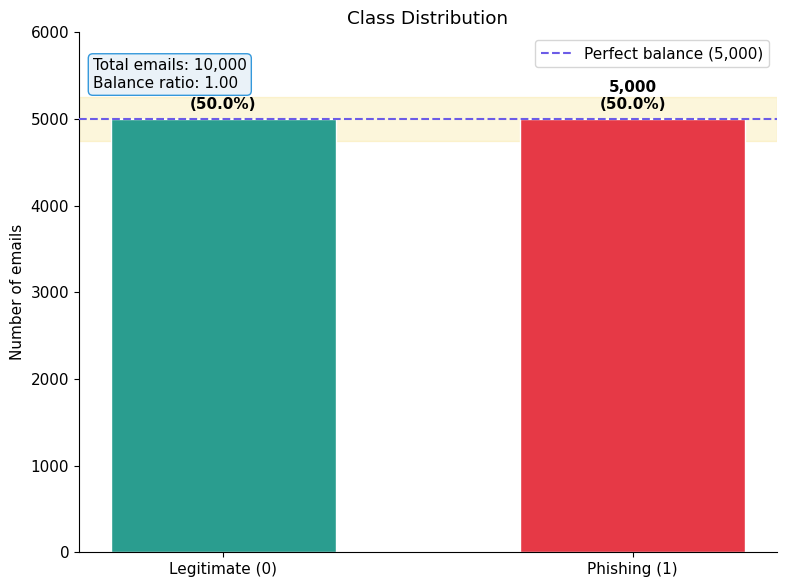

In [16]:
counts = df['label'].value_counts().sort_index()
names = ['Legitimate (0)', 'Phishing (1)']
colors = ['#2a9d8f', '#e63946']
total = counts.sum()

fig, ax = plt.subplots(figsize=(8, 6))
ax.axhspan(4750, 5250, color='#f1c40f', alpha=0.15, zorder=0)
bars = ax.bar(names, counts.values, color=colors, edgecolor='white', width=0.55, zorder=2)
ax.axhline(total / 2, color='#6c5ce7', linestyle='--', linewidth=1.5, label='Perfect balance (5,000)', zorder=3)

for b, c in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, c + 80, f'{c:,}\n({c / total * 100:.1f}%)',
            ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel('Number of emails')
ax.set_title('Class Distribution')
ax.text(0.02, 0.95, f'Total emails: {total:,}\nBalance ratio: {counts[1] / counts[0]:.2f}',
        transform=ax.transAxes, va='top', bbox=dict(boxstyle='round', facecolor='#eaf2f8', edgecolor='#3498db'))
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

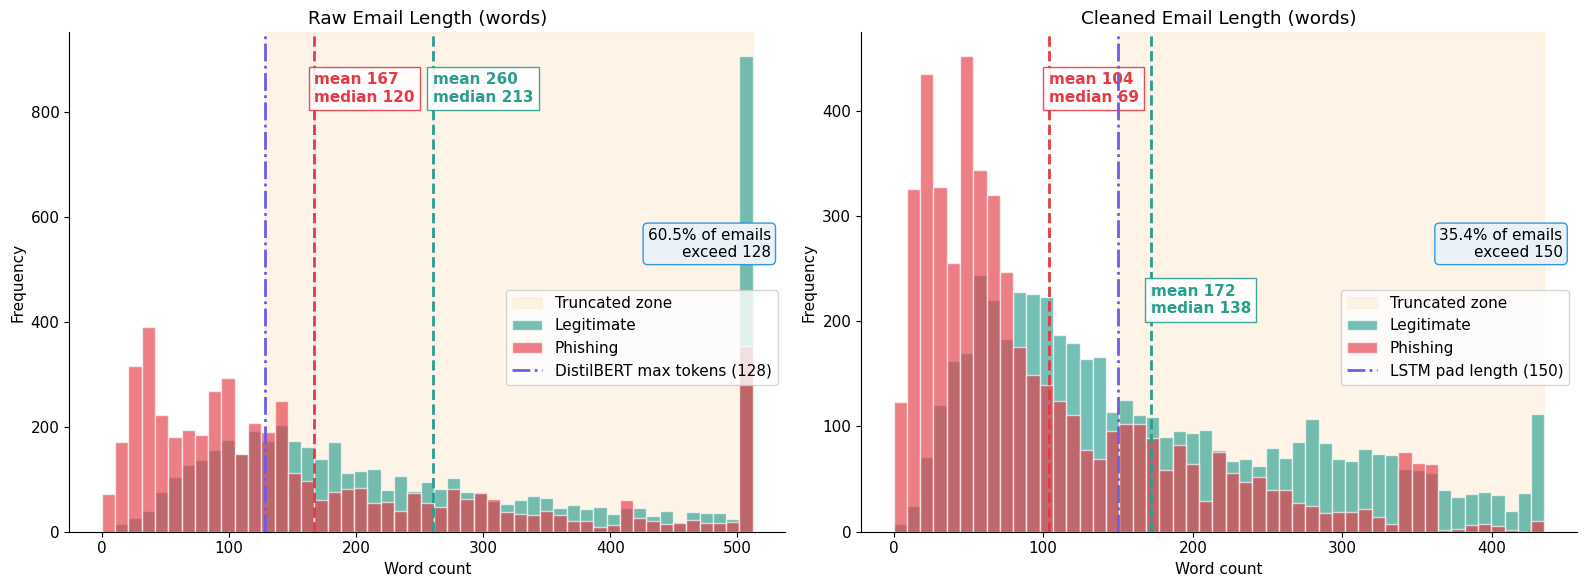

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
specs = [('raw_len', 'Raw Email Length (words)', 128, 'DistilBERT max tokens (128)'),
         ('clean_len', 'Cleaned Email Length (words)', 150, 'LSTM pad length (150)')]

for ax, (col, title, ref, ref_label) in zip(axes, specs):
    upper = int(df[col].quantile(0.99))
    bins = np.linspace(0, upper, 50)
    ax.axvspan(ref, upper, color='#fdebd0', alpha=0.5, zorder=0, label='Truncated zone')
    for lab, name, colr in [(0, 'Legitimate', '#2a9d8f'), (1, 'Phishing', '#e63946')]:
        vals = df.loc[df['label'] == lab, col].clip(upper=upper)
        ax.hist(vals, bins=bins, alpha=0.65, color=colr, label=name, edgecolor='white', zorder=2)
        m = df.loc[df['label'] == lab, col].mean()
        md = df.loc[df['label'] == lab, col].median()
        ax.axvline(m, color=colr, linestyle='--', linewidth=2, zorder=3)
        ax.text(m, ax.get_ylim()[1] * 0.92, f'mean {m:.0f}\nmedian {md:.0f}', color=colr,
                fontweight='bold', ha='left', va='top', bbox=dict(facecolor='white', edgecolor=colr, alpha=0.9))
    ax.axvline(ref, color='#6c5ce7', linestyle='-.', linewidth=2, label=ref_label, zorder=3)
    pct = (df[col] > ref).mean() * 100
    ax.text(0.98, 0.55, f'{pct:.1f}% of emails\nexceed {ref}', transform=ax.transAxes, ha='right',
            bbox=dict(boxstyle='round', facecolor='#eaf2f8', edgecolor='#3498db'))
    ax.set_title(title)
    ax.set_xlabel('Word count')
    ax.set_ylabel('Frequency')
    ax.legend(loc='upper right', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

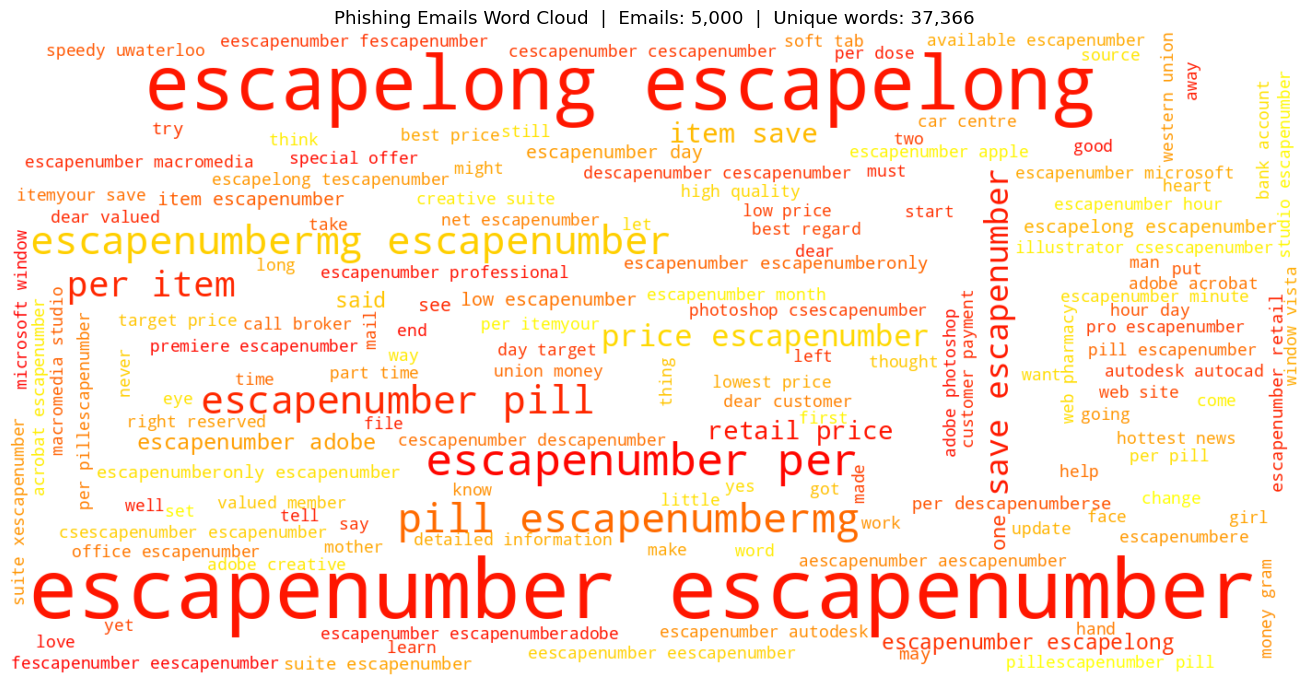

In [18]:
phish_text = ' '.join(df.loc[df['label'] == 1, 'clean_text'])
wc_p = WordCloud(width=1400, height=700, background_color='white', colormap='autumn',
                 max_words=150, random_state=42).generate(phish_text)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wc_p, interpolation='bilinear')
ax.axis('off')
n = (df['label'] == 1).sum()
v = len(set(phish_text.split()))
ax.set_title(f'Phishing Emails Word Cloud  |  Emails: {n:,}  |  Unique words: {v:,}')
plt.tight_layout()
plt.show()

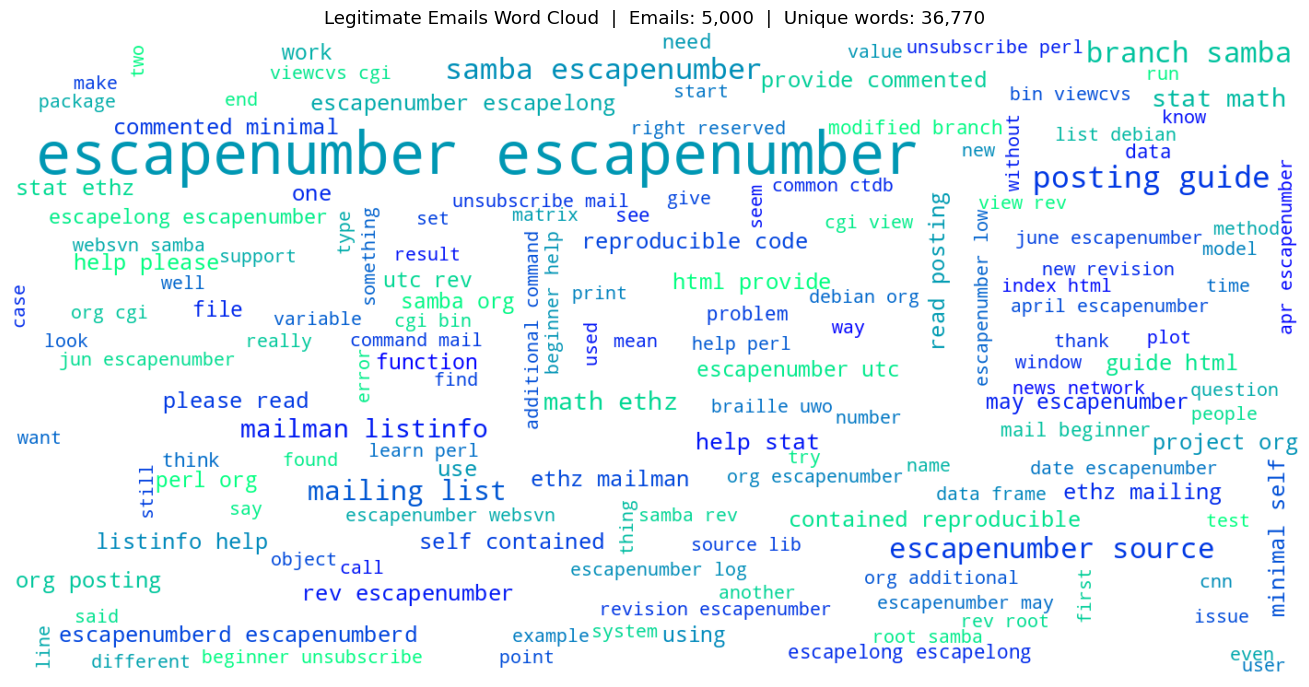

In [19]:
legit_text = ' '.join(df.loc[df['label'] == 0, 'clean_text'])
wc_l = WordCloud(width=1400, height=700, background_color='white', colormap='winter',
                 max_words=150, random_state=42).generate(legit_text)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wc_l, interpolation='bilinear')
ax.axis('off')
n = (df['label'] == 0).sum()
v = len(set(legit_text.split()))
ax.set_title(f'Legitimate Emails Word Cloud  |  Emails: {n:,}  |  Unique words: {v:,}')
plt.tight_layout()
plt.show()

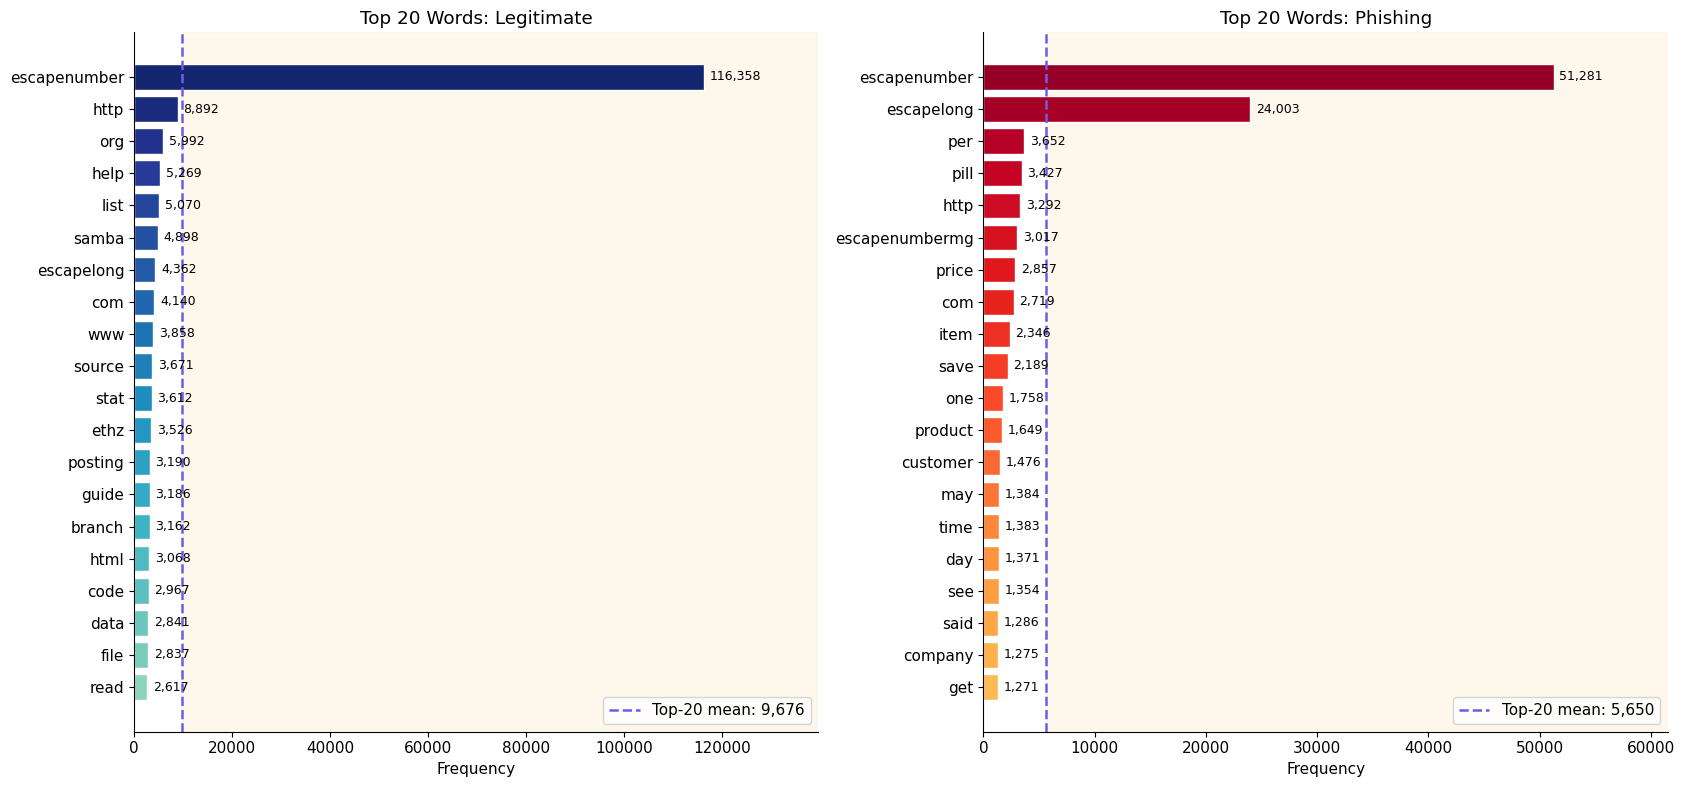

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
cmaps = [cm.YlGnBu, cm.YlOrRd]
labels = [(0, 'Legitimate'), (1, 'Phishing')]

for ax, (lab, name), cmap in zip(axes, labels, cmaps):
    words = ' '.join(df.loc[df['label'] == lab, 'clean_text']).split()
    top = Counter(words).most_common(20)[::-1]
    w = [t[0] for t in top]
    c = [t[1] for t in top]
    cols = cmap(np.linspace(0.35, 0.95, len(c)))
    ax.axvspan(np.mean(c), max(c) * 1.2, color='#fdebd0', alpha=0.4, zorder=0)
    bars = ax.barh(w, c, color=cols, edgecolor='white', zorder=2)
    ax.axvline(np.mean(c), color='#6c5ce7', linestyle='--', linewidth=1.8, label=f'Top-20 mean: {np.mean(c):,.0f}', zorder=3)
    for b, val in zip(bars, c):
        ax.text(val + max(c) * 0.01, b.get_y() + b.get_height() / 2, f'{val:,}', va='center', fontsize=9)
    ax.set_xlim(0, max(c) * 1.2)
    ax.set_title(f'Top 20 Words: {name}')
    ax.set_xlabel('Frequency')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

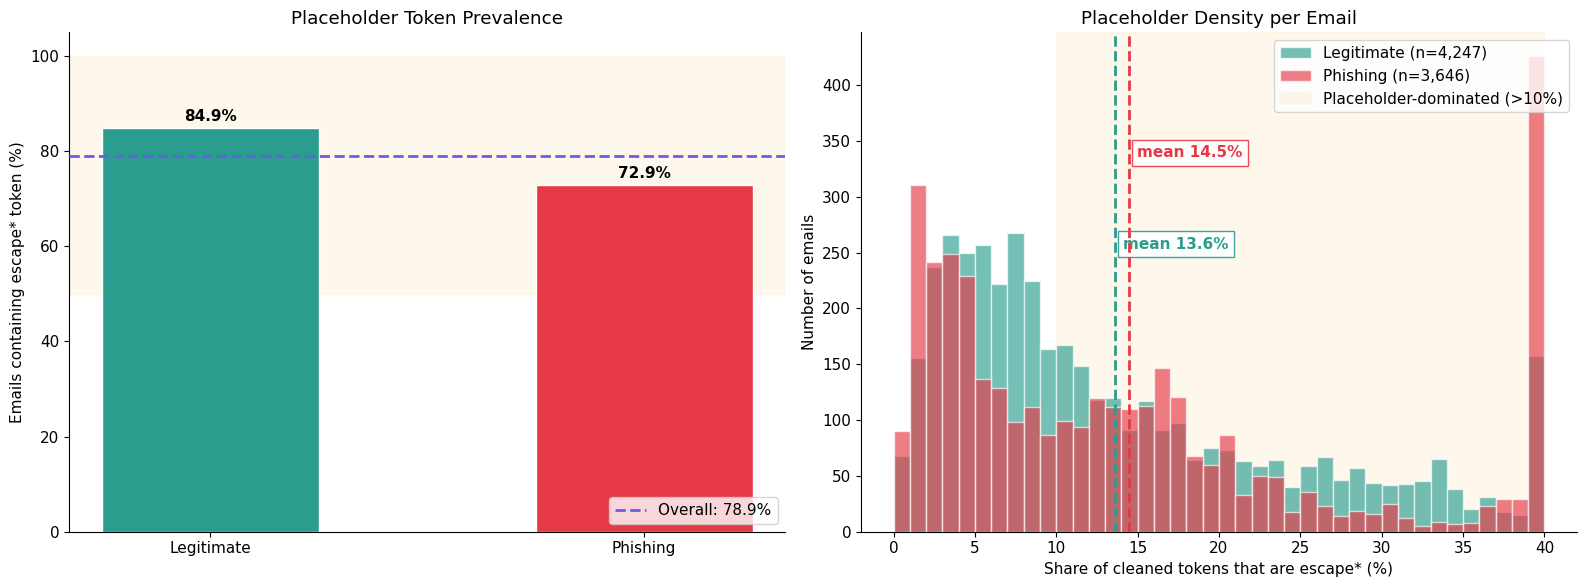

        count      mean        std  min    25%       50%        75%  \
label                                                                 
0      5000.0  11.95836  12.311817  0.0  3.125  8.078409  17.325562   
1      5000.0  11.84206  16.313668  0.0  0.000  5.084746  16.363636   

              max  
label              
0       93.514644  
1      100.000000  
Emails with >10% placeholder tokens: 4048


In [21]:
def esc_share(s):
    w = s.split()
    return sum(t.startswith('escape') for t in w) / max(len(w), 1) * 100

df['esc_pct'] = df['clean_text'].apply(esc_share)
df['has_esc'] = df['esc_pct'] > 0

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
names = ['Legitimate', 'Phishing']
colors = ['#2a9d8f', '#e63946']

share = df.groupby('label')['has_esc'].mean() * 100
ax = axes[0]
ax.axhspan(50, 100, color='#fdebd0', alpha=0.4, zorder=0)
bars = ax.bar(names, share.values, color=colors, edgecolor='white', width=0.5, zorder=2)
ax.axhline(df['has_esc'].mean() * 100, color='#6c5ce7', linestyle='--', linewidth=2,
           label=f"Overall: {df['has_esc'].mean() * 100:.1f}%", zorder=3)
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')
ax.set_ylim(0, 105)
ax.set_ylabel('Emails containing escape* token (%)')
ax.set_title('Placeholder Token Prevalence')
ax.legend(loc='lower right')

ax = axes[1]
bins = np.linspace(0, 40, 41)
for lab, name, colr in [(0, 'Legitimate', '#2a9d8f'), (1, 'Phishing', '#e63946')]:
    v = df.loc[(df['label'] == lab) & df['has_esc'], 'esc_pct'].clip(upper=40)
    ax.hist(v, bins=bins, alpha=0.65, color=colr, edgecolor='white', label=f'{name} (n={len(v):,})', zorder=2)
    ax.axvline(v.mean(), color=colr, linestyle='--', linewidth=2, zorder=3)
    ax.text(v.mean() + 0.5, ax.get_ylim()[1] * (0.9 if lab == 0 else 0.75), f'mean {v.mean():.1f}%',
            color=colr, fontweight='bold', bbox=dict(facecolor='white', edgecolor=colr, alpha=0.9))
ax.axvspan(10, 40, color='#fdebd0', alpha=0.4, zorder=0, label='Placeholder-dominated (>10%)')
ax.set_xlabel('Share of cleaned tokens that are escape* (%)')
ax.set_ylabel('Number of emails')
ax.set_title('Placeholder Density per Email')
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(df.groupby('label')['esc_pct'].describe())
print('Emails with >10% placeholder tokens:', (df['esc_pct'] > 10).sum())

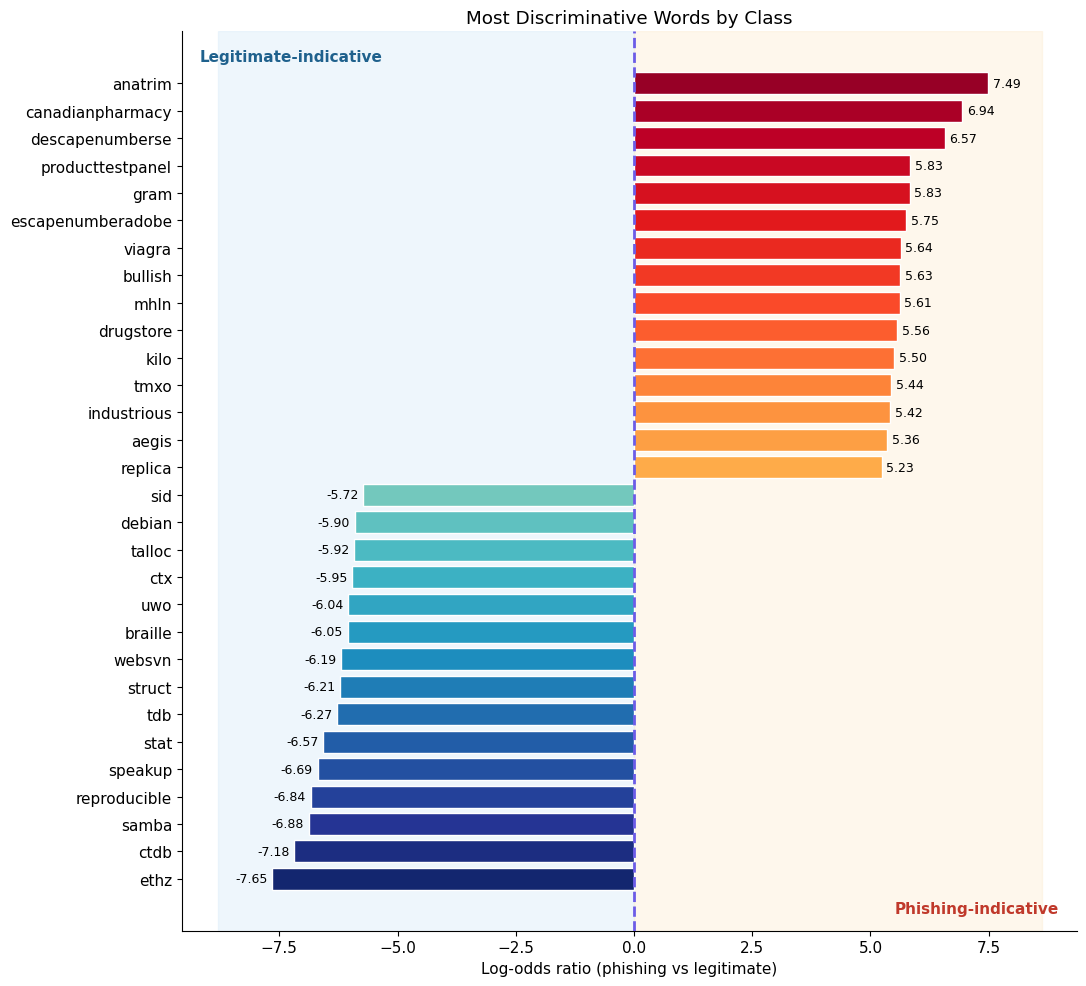

             word  log_odds
             ethz     -7.65
             ctdb     -7.18
            samba     -6.88
     reproducible     -6.84
          speakup     -6.69
             stat     -6.57
              tdb     -6.27
           struct     -6.21
           websvn     -6.19
          braille     -6.05
              uwo     -6.04
              ctx     -5.95
           talloc     -5.92
           debian     -5.90
              sid     -5.72
          replica      5.23
            aegis      5.36
      industrious      5.42
             tmxo      5.44
             kilo      5.50
        drugstore      5.56
             mhln      5.61
          bullish      5.63
           viagra      5.64
escapenumberadobe      5.75
             gram      5.83
 producttestpanel      5.83
  descapenumberse      6.57
 canadianpharmacy      6.94
          anatrim      7.49


In [23]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(min_df=30)
X = cv.fit_transform(df['clean_text'])
vocab = np.array(cv.get_feature_names_out())
y = df['label'].values

c1 = np.asarray(X[y == 1].sum(axis=0)).ravel() + 1
c0 = np.asarray(X[y == 0].sum(axis=0)).ravel() + 1
lo = np.log(c1 / c1.sum()) - np.log(c0 / c0.sum())

order = np.argsort(lo)
neg_idx = order[:15]
pos_idx = order[-15:]
sel = np.concatenate([neg_idx, pos_idx])
vals = lo[sel]
words = vocab[sel]

cols = np.vstack([cm.YlGnBu(np.linspace(0.95, 0.4, 15)), cm.YlOrRd(np.linspace(0.4, 0.95, 15))])

fig, ax = plt.subplots(figsize=(11, 10))
ax.axvspan(vals.min() * 1.15, 0, color='#d6eaf8', alpha=0.4, zorder=0)
ax.axvspan(0, vals.max() * 1.15, color='#fdebd0', alpha=0.4, zorder=0)
bars = ax.barh(words, vals, color=cols, edgecolor='white', zorder=2)
ax.axvline(0, color='#6c5ce7', linestyle='--', linewidth=2, zorder=3)
for b, v in zip(bars, vals):
    ax.text(v + (0.1 if v > 0 else -0.1), b.get_y() + b.get_height() / 2, f'{v:.2f}',
            va='center', ha='left' if v > 0 else 'right', fontsize=9)
ax.set_xlim(vals.min() * 1.25, vals.max() * 1.25)
ax.text(0.02, 0.98, 'Legitimate-indicative', transform=ax.transAxes, va='top', fontweight='bold', color='#1f618d')
ax.text(0.98, 0.02, 'Phishing-indicative', transform=ax.transAxes, ha='right', fontweight='bold', color='#c0392b')
ax.set_xlabel('Log-odds ratio (phishing vs legitimate)')
ax.set_title('Most Discriminative Words by Class')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'word': words, 'log_odds': vals.round(2)}).to_string(index=False))

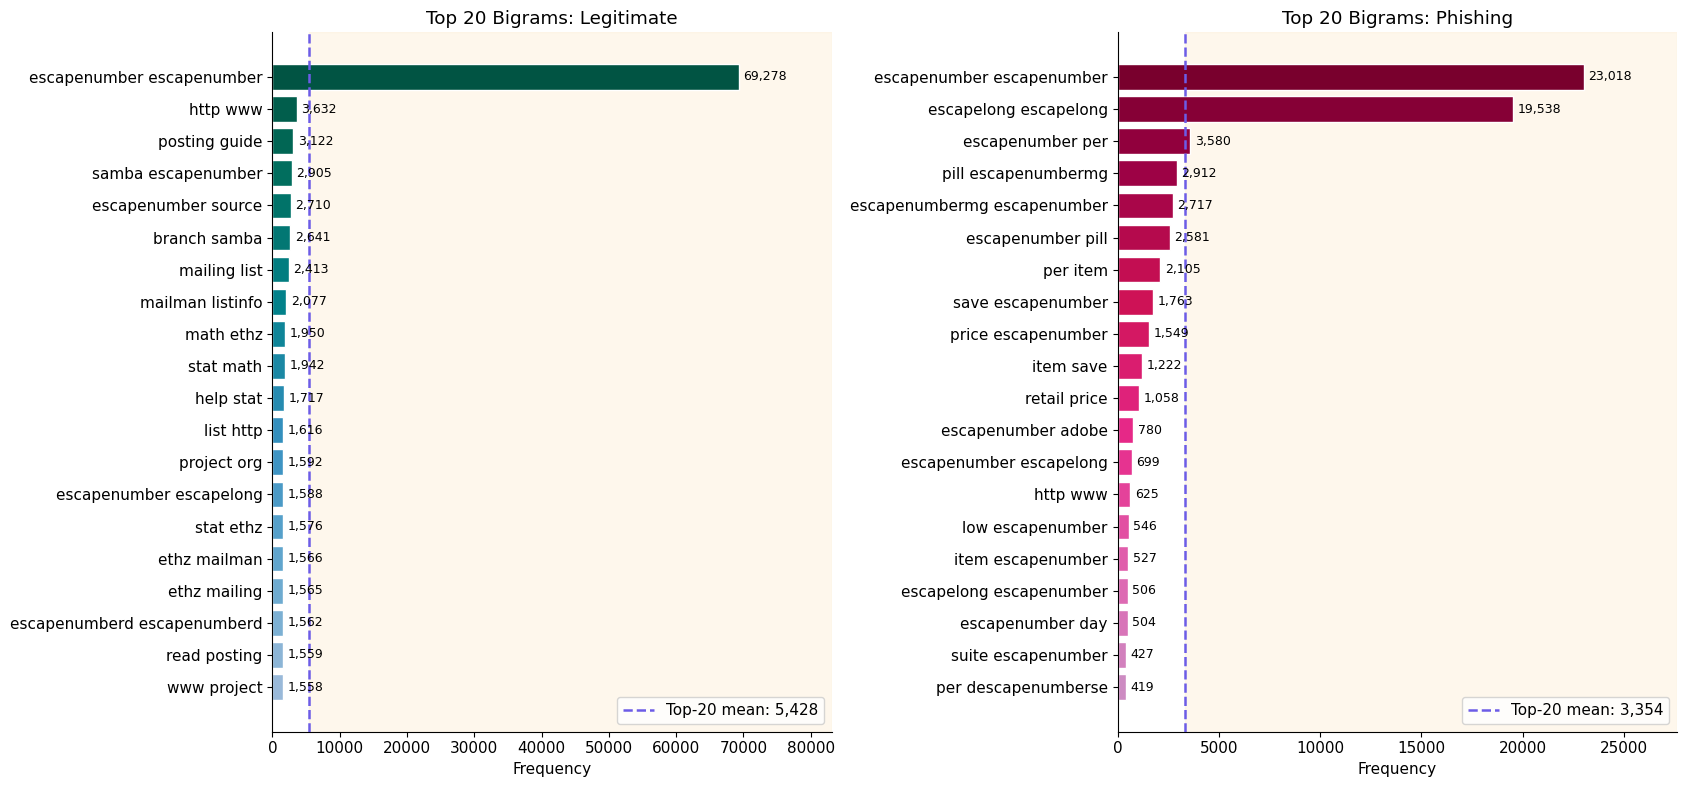

In [24]:
bv = CountVectorizer(ngram_range=(2, 2), min_df=5)
Xb = bv.fit_transform(df['clean_text'])
bvocab = np.array(bv.get_feature_names_out())

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
cmaps = [cm.PuBuGn, cm.PuRd]

for ax, lab, name, cmap in zip(axes, (0, 1), ('Legitimate', 'Phishing'), cmaps):
    cnt = np.asarray(Xb[df['label'].values == lab].sum(axis=0)).ravel()
    idx = np.argsort(cnt)[-20:]
    w = bvocab[idx]
    c = cnt[idx]
    cols = cmap(np.linspace(0.4, 0.95, len(c)))
    ax.axvspan(c.mean(), c.max() * 1.2, color='#fdebd0', alpha=0.4, zorder=0)
    bars = ax.barh(w, c, color=cols, edgecolor='white', zorder=2)
    ax.axvline(c.mean(), color='#6c5ce7', linestyle='--', linewidth=1.8, label=f'Top-20 mean: {c.mean():,.0f}', zorder=3)
    for b, v in zip(bars, c):
        ax.text(v + c.max() * 0.01, b.get_y() + b.get_height() / 2, f'{v:,}', va='center', fontsize=9)
    ax.set_xlim(0, c.max() * 1.2)
    ax.set_title(f'Top 20 Bigrams: {name}')
    ax.set_xlabel('Frequency')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

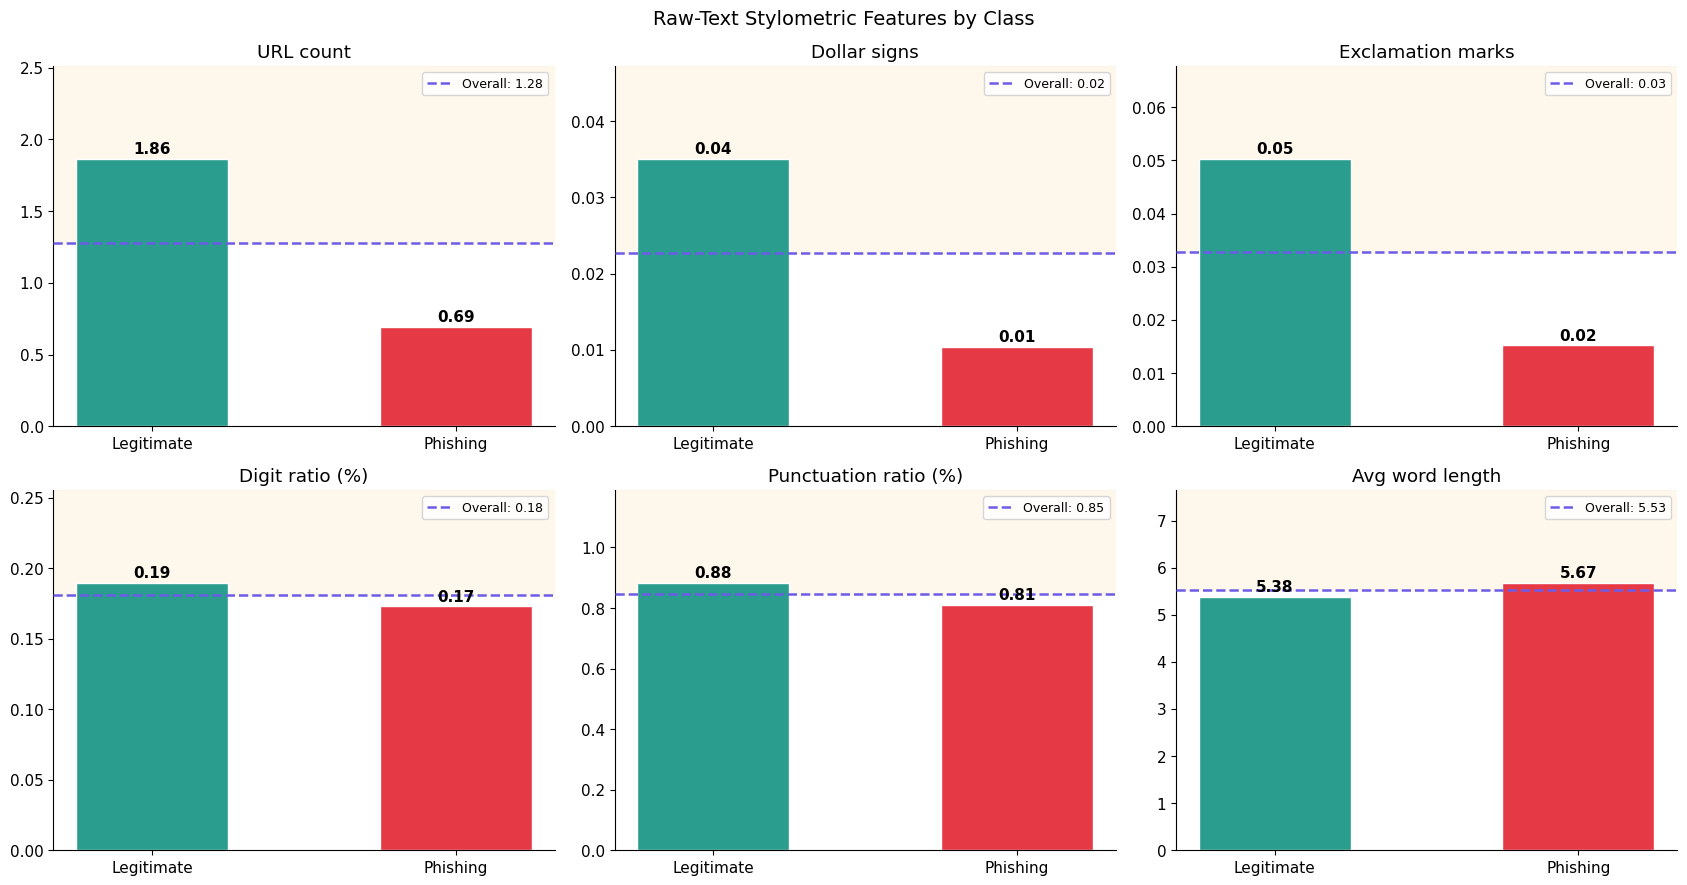

label                      0      1
URL count              1.861  0.692
Dollar signs           0.035  0.010
Exclamation marks      0.050  0.015
Digit ratio (%)        0.189  0.173
Punctuation ratio (%)  0.882  0.809
Avg word length        5.382  5.670
URL count               -0.282
Dollar signs            -0.024
Exclamation marks       -0.022
Digit ratio (%)         -0.007
Punctuation ratio (%)   -0.010
Avg word length          0.086
dtype: float64


In [25]:
feat = pd.DataFrame({
    'label': df['label'],
    'URL count': df['text'].str.count(r'http\S*|www\.'),
    'Dollar signs': df['text'].str.count(r'\$'),
    'Exclamation marks': df['text'].str.count('!'),
    'Digit ratio (%)': df['text'].apply(lambda s: sum(ch.isdigit() for ch in s) / max(len(s), 1) * 100),
    'Punctuation ratio (%)': df['text'].apply(lambda s: sum((not ch.isalnum()) and (not ch.isspace()) for ch in s) / max(len(s), 1) * 100),
    'Avg word length': df['text'].apply(lambda s: np.mean([len(w) for w in s.split()]))
})

cols_f = [c for c in feat.columns if c != 'label']
means = feat.groupby('label')[cols_f].mean()
overall = feat[cols_f].mean()
colors = ['#2a9d8f', '#e63946']

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, f in zip(axes.ravel(), cols_f):
    v = means[f].values
    ax.axhspan(overall[f], max(v) * 1.35, color='#fdebd0', alpha=0.4, zorder=0)
    bars = ax.bar(['Legitimate', 'Phishing'], v, color=colors, edgecolor='white', width=0.5, zorder=2)
    ax.axhline(overall[f], color='#6c5ce7', linestyle='--', linewidth=1.8, label=f'Overall: {overall[f]:.2f}', zorder=3)
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + max(v) * 0.02, f'{val:.2f}', ha='center', fontweight='bold')
    ax.set_ylim(0, max(v) * 1.35)
    ax.set_title(f)
    ax.legend(loc='upper right', fontsize=9)

plt.suptitle('Raw-Text Stylometric Features by Class', fontsize=14)
plt.tight_layout()
plt.show()

print(means.round(3).T)
print(feat.drop(columns='label').corrwith(feat['label']).round(3))

# **Train / Validation / Test Split**

In [26]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

df = pd.read_csv('/content/final_dataset_clean.csv')
n_start = len(df)
pat = re.compile(r'escape(?:number|long)\w*', re.I)
df['text'] = df['text'].apply(lambda s: re.sub(r'\s+', ' ', pat.sub(' ', str(s))).strip())
df['clean_text'] = df['text'].apply(clean_text)
df['raw_len'] = df['text'].str.split().str.len()
df['clean_len'] = df['clean_text'].str.split().str.len()

print('Start rows:', n_start)
print('Residual placeholder tokens in clean_text:', df['clean_text'].str.contains('escapenumber|escapelong').sum())
print('Raw length == 0:', (df['raw_len'] == 0).sum())
print('Clean length == 0:', (df['clean_len'] == 0).sum())
print('Raw length < 5:', (df['raw_len'] < 5).sum())
print(df.groupby('label')[['raw_len', 'clean_len']].describe().T)

Start rows: 10000
Residual placeholder tokens in clean_text: 0
Raw length == 0: 0
Clean length == 0: 12
Raw length < 5: 10
label                      0            1
raw_len   count  5000.000000  5000.000000
          mean    235.402400   150.908200
          std     143.602095   130.098240
          min       6.000000     2.000000
          25%     116.000000    52.000000
          50%     194.000000   108.500000
          75%     350.000000   202.000000
          max     512.000000   512.000000
clean_len count  5000.000000  5000.000000
          mean    145.489200    85.574000
          std      91.984565    71.887062
          min       3.000000     0.000000
          25%      72.000000    30.000000
          50%     118.000000    59.000000
          75%     213.000000   132.000000
          max     713.000000   386.000000


In [27]:
df = df[(df['raw_len'] >= 5) & (df['clean_len'] > 0)]
print('After length filter:', df.shape)

dup_text = df.duplicated(subset='text').sum()
dup_clean = df.duplicated(subset='clean_text').sum()
print('Duplicate text:', dup_text)
print('Duplicate clean_text:', dup_clean)

df = df.drop_duplicates(subset='clean_text').drop_duplicates(subset='text').reset_index(drop=True)
print('After deduplication:', df.shape)
print(df['label'].value_counts())

After length filter: (9979, 5)
Duplicate text: 3
Duplicate clean_text: 33
After deduplication: (9946, 5)
label
0    4998
1    4948
Name: count, dtype: int64


In [28]:
conflict = df.groupby('clean_text')['label'].nunique()
print('Clean texts with conflicting labels:', (conflict > 1).sum())

n_min = df['label'].value_counts().min()
df = (df.groupby('label', group_keys=False)
        .apply(lambda g: g.sample(n=n_min, random_state=42))
        .sample(frac=1, random_state=42)
        .reset_index(drop=True))
df['id'] = np.arange(len(df))
df['raw_len'] = df['text'].str.split().str.len()
df['clean_len'] = df['clean_text'].str.split().str.len()

print('Balanced dataset:', df.shape)
print(df['label'].value_counts())
df.to_csv('/content/final_dataset_v2.csv', index=False)

Clean texts with conflicting labels: 0
Balanced dataset: (9896, 6)
label
0    4948
1    4948
Name: count, dtype: int64


In [29]:
train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv('/content/train.csv', index=False)
val_df.to_csv('/content/val.csv', index=False)
test_df.to_csv('/content/test.csv', index=False)

print('Train:', train_df.shape)
print('Val  :', val_df.shape)
print('Test :', test_df.shape)

Train: (7916, 6)
Val  : (990, 6)
Test : (990, 6)


In [30]:
splits = {'Train': train_df, 'Validation': val_df, 'Test': test_df}
summary = pd.DataFrame({
    n: {
        'rows': len(d),
        'share (%)': len(d) / len(df) * 100,
        'legitimate': (d['label'] == 0).sum(),
        'phishing': (d['label'] == 1).sum(),
        'phishing (%)': d['label'].mean() * 100,
        'mean clean_len': d['clean_len'].mean(),
        'mean raw_len': d['raw_len'].mean()
    } for n, d in splits.items()
}).T.round(2)
print(summary)

ids = {n: set(d['id']) for n, d in splits.items()}
texts = {n: set(d['clean_text']) for n, d in splits.items()}
pairs = [('Train', 'Validation'), ('Train', 'Test'), ('Validation', 'Test')]
for a, b in pairs:
    print(f'{a}/{b} id overlap:', len(ids[a] & ids[b]), '| clean_text overlap:', len(texts[a] & texts[b]))
print('Total ids covered:', len(ids['Train'] | ids['Validation'] | ids['Test']), 'of', len(df))

              rows  share (%)  legitimate  phishing  phishing (%)  \
Train       7916.0      79.99      3958.0    3958.0          50.0   
Validation   990.0      10.00       495.0     495.0          50.0   
Test         990.0      10.00       495.0     495.0          50.0   

            mean clean_len  mean raw_len  
Train               115.80        193.44  
Validation          114.42        191.91  
Test                116.18        192.85  
Train/Validation id overlap: 0 | clean_text overlap: 0
Train/Test id overlap: 0 | clean_text overlap: 0
Validation/Test id overlap: 0 | clean_text overlap: 0
Total ids covered: 9896 of 9896


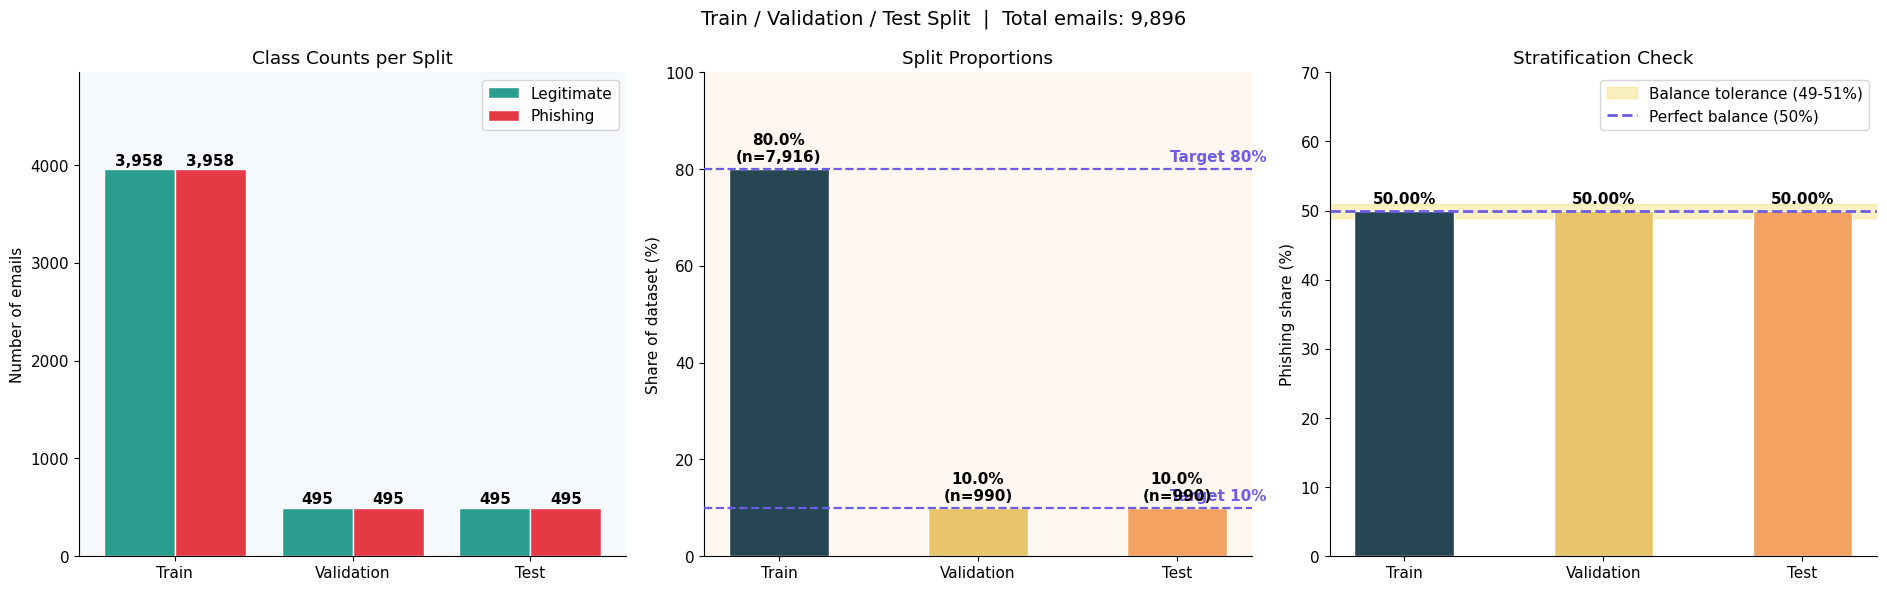

In [31]:
names = list(splits.keys())
legit = [(d['label'] == 0).sum() for d in splits.values()]
phish = [(d['label'] == 1).sum() for d in splits.values()]
shares = [len(d) / len(df) * 100 for d in splits.values()]
phish_pct = [d['label'].mean() * 100 for d in splits.values()]
zone_cols = ['#2a9d8f', '#e63946']
split_cols = ['#264653', '#e9c46a', '#f4a261']

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

ax = axes[0]
x = np.arange(3)
ax.axhspan(0, max(legit + phish) * 1.25, xmin=0.0, xmax=1.0, color='#eaf2f8', alpha=0.4, zorder=0)
b1 = ax.bar(x - 0.2, legit, 0.4, color=zone_cols[0], edgecolor='white', label='Legitimate', zorder=2)
b2 = ax.bar(x + 0.2, phish, 0.4, color=zone_cols[1], edgecolor='white', label='Phishing', zorder=2)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + max(legit + phish) * 0.01,
                f'{int(b.get_height()):,}', ha='center', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, max(legit + phish) * 1.25)
ax.set_ylabel('Number of emails')
ax.set_title('Class Counts per Split')
ax.legend(loc='upper right')

ax = axes[1]
ax.axhspan(0, 100, color='#fdebd0', alpha=0.3, zorder=0)
bars = ax.bar(names, shares, color=split_cols, edgecolor='white', width=0.5, zorder=2)
for ref, lab in [(80, 'Target 80%'), (10, 'Target 10%')]:
    ax.axhline(ref, color='#6c5ce7', linestyle='--', linewidth=1.6, zorder=3)
    ax.text(2.45, ref + 1.5, lab, ha='right', color='#6c5ce7', fontweight='bold')
for b, v, d in zip(bars, shares, splits.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f'{v:.1f}%\n(n={len(d):,})', ha='center', fontweight='bold')
ax.set_ylim(0, 100)
ax.set_ylabel('Share of dataset (%)')
ax.set_title('Split Proportions')

ax = axes[2]
ax.axhspan(49, 51, color='#f1c40f', alpha=0.25, zorder=0, label='Balance tolerance (49-51%)')
bars = ax.bar(names, phish_pct, color=split_cols, edgecolor='white', width=0.5, zorder=2)
ax.axhline(50, color='#6c5ce7', linestyle='--', linewidth=2, label='Perfect balance (50%)', zorder=3)
for b, v in zip(bars, phish_pct):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.2f}%', ha='center', fontweight='bold')
ax.set_ylim(0, 70)
ax.set_ylabel('Phishing share (%)')
ax.set_title('Stratification Check')
ax.legend(loc='upper right')

plt.suptitle(f'Train / Validation / Test Split  |  Total emails: {len(df):,}', fontsize=14)
plt.tight_layout()
plt.show()

# **Logistic Regression + TF-IDF**

In [32]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             precision_recall_curve, average_precision_score)

y_train = train_df['label'].values
y_val = val_df['label'].values
y_test = test_df['label'].values

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
t0 = time.time()
X_train = tfidf.fit_transform(train_df['clean_text'])
tfidf_time = time.time() - t0
X_val = tfidf.transform(val_df['clean_text'])
X_test = tfidf.transform(test_df['clean_text'])

print(X_train.shape, X_val.shape, X_test.shape)
print('Vocabulary size:', len(tfidf.vocabulary_))
print('Vectorisation time (s):', round(tfidf_time, 2))
print('Train matrix density (%):', round(X_train.nnz / (X_train.shape[0] * X_train.shape[1]) * 100, 3))

(7916, 20000) (990, 20000) (990, 20000)
Vocabulary size: 20000
Vectorisation time (s): 12.18
Train matrix density (%): 0.489


In [33]:
Cs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
rows = []
for C in Cs:
    m = LogisticRegression(C=C, max_iter=2000, solver='liblinear', random_state=42)
    m.fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    rows.append({'C': C,
                 'train_f1': f1_score(y_train, m.predict(X_train)),
                 'val_f1': f1_score(y_val, (p >= 0.5).astype(int)),
                 'val_auc': roc_auc_score(y_val, p)})

tune = pd.DataFrame(rows)
best_C = tune.loc[tune['val_f1'].idxmax(), 'C']
print(tune.round(4).to_string(index=False))
print('Best C:', best_C)

     C  train_f1  val_f1  val_auc
  0.01    0.9229  0.9199   0.9898
  0.03    0.9416  0.9364   0.9918
  0.10    0.9642  0.9618   0.9941
  0.30    0.9784  0.9722   0.9958
  1.00    0.9892  0.9781   0.9971
  3.00    0.9960  0.9800   0.9979
 10.00    0.9996  0.9820   0.9984
 30.00    0.9999  0.9820   0.9985
100.00    0.9999  0.9820   0.9985
Best C: 10.0


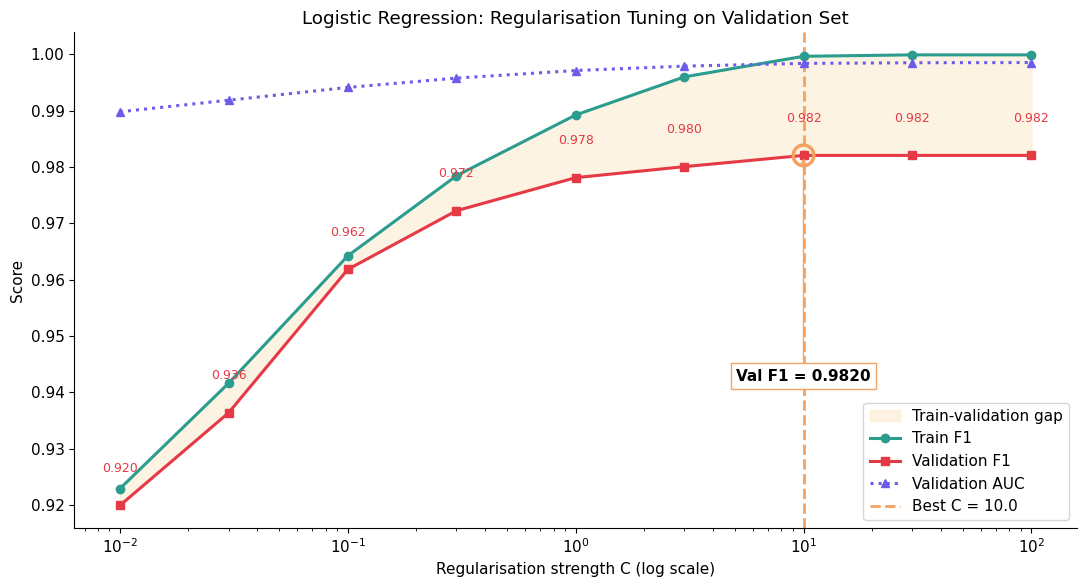

In [34]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.fill_between(tune['C'], tune['val_f1'], tune['train_f1'], color='#fdebd0', alpha=0.6, label='Train-validation gap', zorder=0)
ax.plot(tune['C'], tune['train_f1'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train F1', zorder=3)
ax.plot(tune['C'], tune['val_f1'], marker='s', color='#e63946', linewidth=2.2, label='Validation F1', zorder=3)
ax.plot(tune['C'], tune['val_auc'], marker='^', color='#6c5ce7', linewidth=2.2, linestyle=':', label='Validation AUC', zorder=3)
ax.axvline(best_C, color='#f4a261', linestyle='--', linewidth=2, label=f'Best C = {best_C}', zorder=2)
bv = tune.loc[tune['C'] == best_C, 'val_f1'].iloc[0]
ax.scatter([best_C], [bv], s=220, facecolor='none', edgecolor='#f4a261', linewidth=2.5, zorder=4)
ax.annotate(f'Val F1 = {bv:.4f}', xy=(best_C, bv), xytext=(best_C, bv - 0.04), ha='center', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#f4a261'), bbox=dict(facecolor='white', edgecolor='#f4a261'))
for c, v in zip(tune['C'], tune['val_f1']):
    ax.text(c, v + 0.006, f'{v:.3f}', ha='center', fontsize=9, color='#e63946')
ax.set_xscale('log')
ax.set_xlabel('Regularisation strength C (log scale)')
ax.set_ylabel('Score')
ax.set_title('Logistic Regression: Regularisation Tuning on Validation Set')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [35]:
def compute_metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred),
            'recall': recall_score(y_true, pred),
            'f1': f1_score(y_true, pred),
            'auc': roc_auc_score(y_true, prob)}

lr = LogisticRegression(C=best_C, max_iter=2000, solver='liblinear', random_state=42)
t0 = time.time()
lr.fit(X_train, y_train)
lr_train_time = time.time() - t0 + tfidf_time

val_prob = lr.predict_proba(X_val)[:, 1]
test_prob = lr.predict_proba(X_test)[:, 1]

results = {}
results['Logistic Regression'] = {'val': compute_metrics(y_val, val_prob),
                                  'test': compute_metrics(y_test, test_prob),
                                  'test_prob': test_prob,
                                  'train_time': lr_train_time}
np.save('/content/prob_lr.npy', test_prob)

r = results['Logistic Regression']
print(pd.DataFrame({'Validation': r['val'], 'Test': r['test']}).round(4))
print('Training time incl. TF-IDF (s):', round(lr_train_time, 2))
tn, fp, fn, tp = confusion_matrix(y_test, (test_prob >= 0.5).astype(int)).ravel()
print('TN, FP, FN, TP:', tn, fp, fn, tp)

           Validation    Test
accuracy       0.9818  0.9818
precision      0.9704  0.9799
recall         0.9939  0.9838
f1             0.9820  0.9819
auc            0.9984  0.9985
Training time incl. TF-IDF (s): 12.66
TN, FP, FN, TP: 485 10 8 487


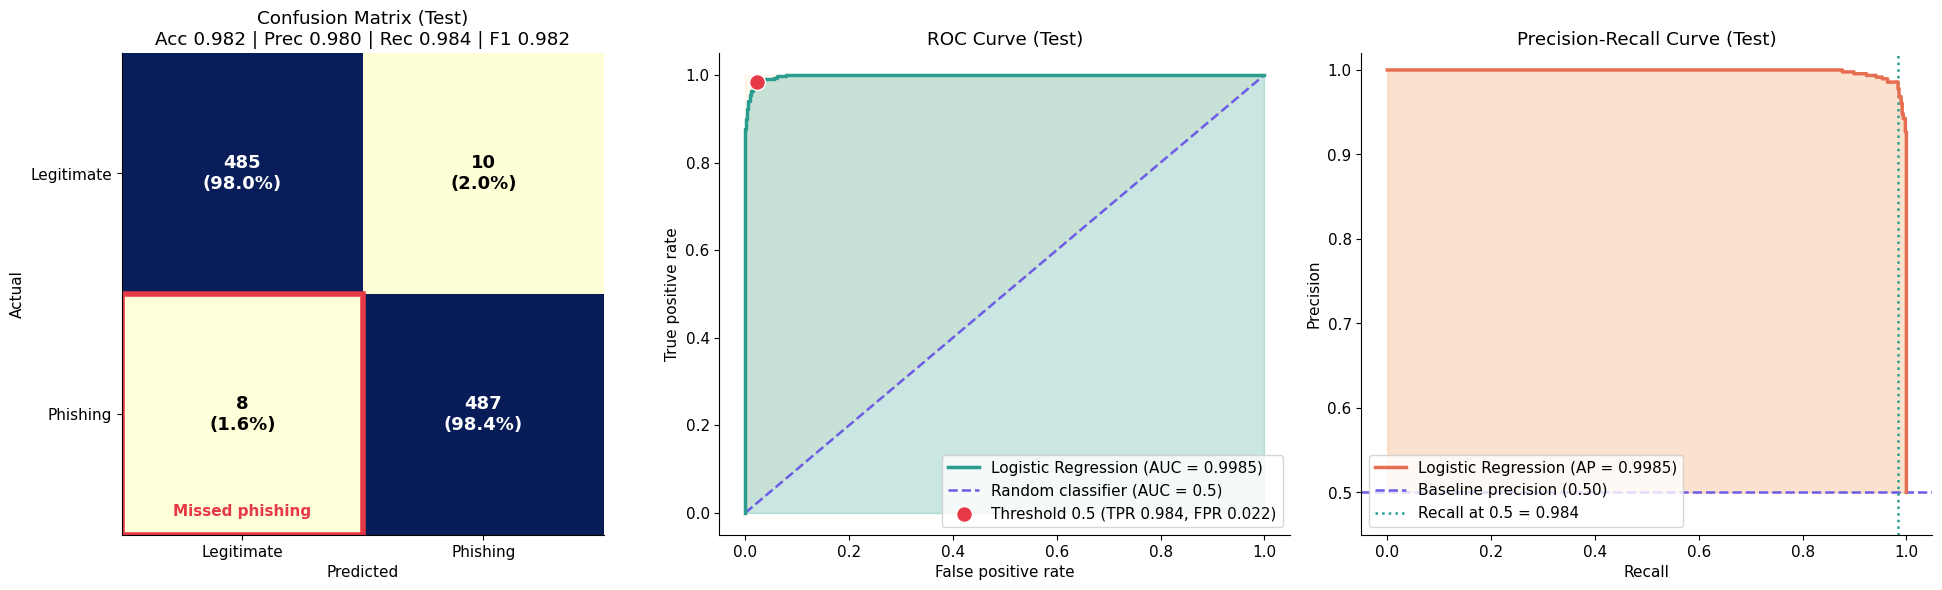

In [36]:
pred = (test_prob >= 0.5).astype(int)
cmx = confusion_matrix(y_test, pred)
fpr, tpr, thr = roc_curve(y_test, test_prob)
prec, rec, _ = precision_recall_curve(y_test, test_prob)
mt = results['Logistic Regression']['test']
ap = average_precision_score(y_test, test_prob)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
ax.imshow(cmx, cmap='YlGnBu')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cmx[i, j]:,}\n({cmx[i, j] / cmx[i].sum() * 100:.1f}%)', ha='center', va='center',
                fontweight='bold', fontsize=13, color='white' if cmx[i, j] > cmx.max() / 2 else 'black')
ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor='#e63946', linewidth=4))
ax.text(0, 1.42, 'Missed phishing', ha='center', color='#e63946', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Legitimate', 'Phishing'])
ax.set_yticklabels(['Legitimate', 'Phishing'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f"Confusion Matrix (Test)\nAcc {mt['accuracy']:.3f} | Prec {mt['precision']:.3f} | Rec {mt['recall']:.3f} | F1 {mt['f1']:.3f}")

ax = axes[1]
ax.fill_between(fpr, 0, tpr, color='#2a9d8f', alpha=0.25, zorder=1)
ax.fill_between([0, 1], [0, 1], [1, 1], color='#fdebd0', alpha=0.35, zorder=0)
ax.plot(fpr, tpr, color='#2a9d8f', linewidth=2.5, label=f"Logistic Regression (AUC = {mt['auc']:.4f})", zorder=3)
ax.plot([0, 1], [0, 1], color='#6c5ce7', linestyle='--', linewidth=1.8, label='Random classifier (AUC = 0.5)', zorder=2)
k = np.argmin(np.abs(thr - 0.5))
ax.scatter(fpr[k], tpr[k], s=130, color='#e63946', edgecolor='white', zorder=5, label=f'Threshold 0.5 (TPR {tpr[k]:.3f}, FPR {fpr[k]:.3f})')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC Curve (Test)')
ax.legend(loc='lower right')

ax = axes[2]
ax.fill_between(rec, 0.5, prec, color='#f4a261', alpha=0.3, zorder=1)
ax.plot(rec, prec, color='#e76f51', linewidth=2.5, label=f'Logistic Regression (AP = {ap:.4f})', zorder=3)
ax.axhline(0.5, color='#6c5ce7', linestyle='--', linewidth=1.8, label='Baseline precision (0.50)', zorder=2)
ax.axvline(mt['recall'], color='#2a9d8f', linestyle=':', linewidth=1.8, label=f"Recall at 0.5 = {mt['recall']:.3f}", zorder=2)
ax.set_ylim(0.45, 1.02)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve (Test)')
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

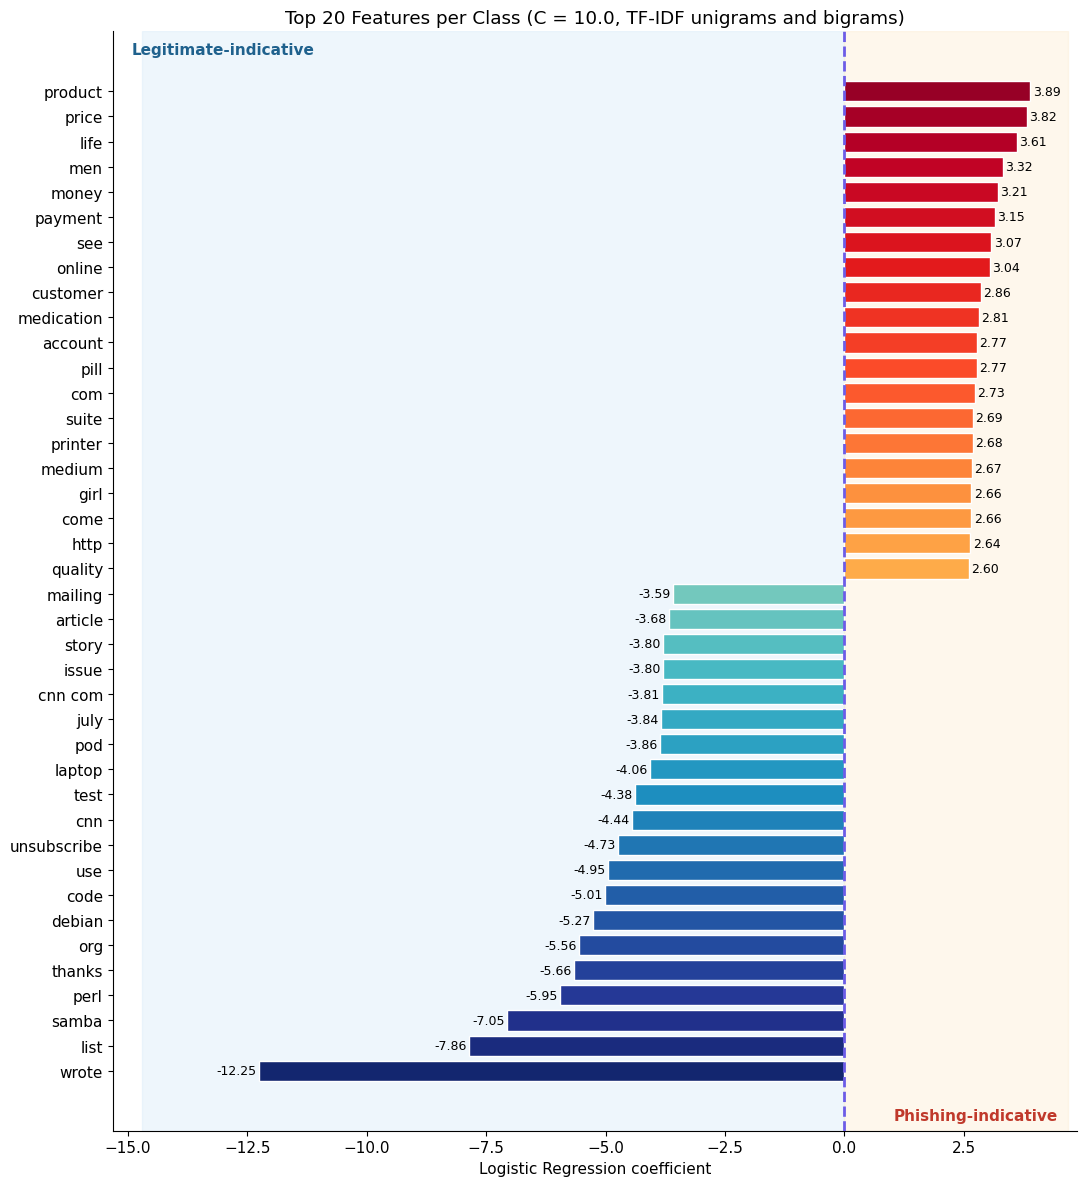

Misclassified test emails: 18 of 990
label
False positives    10
False negatives     8
Name: count, dtype: int64


In [37]:
names = np.array(tfidf.get_feature_names_out())
coef = lr.coef_.ravel()
order = np.argsort(coef)
sel = np.concatenate([order[:20], order[-20:]])
vals = coef[sel]
words = names[sel]
cols = np.vstack([cm.YlGnBu(np.linspace(0.95, 0.4, 20)), cm.YlOrRd(np.linspace(0.4, 0.95, 20))])

fig, ax = plt.subplots(figsize=(11, 12))
ax.axvspan(vals.min() * 1.2, 0, color='#d6eaf8', alpha=0.4, zorder=0)
ax.axvspan(0, vals.max() * 1.2, color='#fdebd0', alpha=0.4, zorder=0)
bars = ax.barh(words, vals, color=cols, edgecolor='white', zorder=2)
ax.axvline(0, color='#6c5ce7', linestyle='--', linewidth=2, zorder=3)
for b, v in zip(bars, vals):
    ax.text(v + (0.05 if v > 0 else -0.05), b.get_y() + b.get_height() / 2, f'{v:.2f}',
            va='center', ha='left' if v > 0 else 'right', fontsize=9)
ax.set_xlim(vals.min() * 1.25, vals.max() * 1.25)
ax.text(0.02, 0.99, 'Legitimate-indicative', transform=ax.transAxes, va='top', fontweight='bold', color='#1f618d')
ax.text(0.98, 0.01, 'Phishing-indicative', transform=ax.transAxes, ha='right', fontweight='bold', color='#c0392b')
ax.set_xlabel('Logistic Regression coefficient')
ax.set_title(f'Top 20 Features per Class (C = {best_C}, TF-IDF unigrams and bigrams)')
plt.tight_layout()
plt.show()

wrong = test_df[pred != y_test]
print('Misclassified test emails:', len(wrong), 'of', len(test_df))
print(wrong['label'].value_counts().rename({0: 'False positives', 1: 'False negatives'}))

# **LSTM**

In [38]:
import os
import random
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

MAX_WORDS = 20000
MAX_LEN = 150

tok = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tok.fit_on_texts(train_df['clean_text'])

def to_seq(texts):
    return pad_sequences(tok.texts_to_sequences(texts), maxlen=MAX_LEN, padding='post', truncating='post')

Xs_train = to_seq(train_df['clean_text'])
Xs_val = to_seq(val_df['clean_text'])
Xs_test = to_seq(test_df['clean_text'])

print(Xs_train.shape, Xs_val.shape, Xs_test.shape)
print('Tokenizer vocabulary (train):', len(tok.word_index))
print('Vocabulary used:', MAX_WORDS)
print('Train emails truncated (>150 tokens, %):', round((train_df['clean_len'] > MAX_LEN).mean() * 100, 1))
print('Validation OOV token rate (%):', round((Xs_val[Xs_val > 0] == 1).mean() * 100, 2))
print('GPUs:', tf.config.list_physical_devices('GPU'))

(7916, 150) (990, 150) (990, 150)
Tokenizer vocabulary (train): 51198
Vocabulary used: 20000
Train emails truncated (>150 tokens, %): 28.4
Validation OOV token rate (%): 6.02
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [39]:
from tensorflow.keras import layers, models

def build_rnn(bidirectional=False, embed_dim=128, units=64):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    inp = layers.Input(shape=(MAX_LEN,))
    x = layers.Embedding(MAX_WORDS, embed_dim, mask_zero=True)(inp)
    rnn = layers.LSTM(units)
    x = layers.Bidirectional(rnn)(x) if bidirectional else rnn(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    return model

lstm = build_rnn(bidirectional=False)
lstm.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 128)  │  2,560,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     49,408 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,611,521 (9.96 MB)

 Trainable params: 2,611,521 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
t0 = time.time()
hist = lstm.fit(Xs_train, y_train, validation_data=(Xs_val, y_val),
                epochs=10, batch_size=64, callbacks=[es], verbose=2)
lstm_time = time.time() - t0

h = pd.DataFrame(hist.history)
h.index = np.arange(1, len(h) + 1)
print(h.round(4))
print('Epochs run:', len(h))
print('Best epoch (val_loss):', int(h['val_loss'].idxmin()))
print('Training time (s):', round(lstm_time, 2))

Epoch 1/10
124/124 - 16s - 132ms/step - accuracy: 0.9142 - loss: 0.2611 - val_accuracy: 0.9697 - val_loss: 0.1000
Epoch 2/10
124/124 - 1s - 12ms/step - accuracy: 0.9867 - loss: 0.0546 - val_accuracy: 0.9616 - val_loss: 0.1154
Epoch 3/10
124/124 - 1s - 12ms/step - accuracy: 0.9960 - loss: 0.0194 - val_accuracy: 0.9727 - val_loss: 0.1097
Epoch 4/10
124/124 - 1s - 12ms/step - accuracy: 0.9985 - loss: 0.0091 - val_accuracy: 0.9747 - val_loss: 0.1327
   accuracy    loss  val_accuracy  val_loss
1    0.9142  0.2611        0.9697    0.1000
2    0.9867  0.0546        0.9616    0.1154
3    0.9960  0.0194        0.9727    0.1097
4    0.9985  0.0091        0.9747    0.1327
Epochs run: 4
Best epoch (val_loss): 1
Training time (s): 20.98


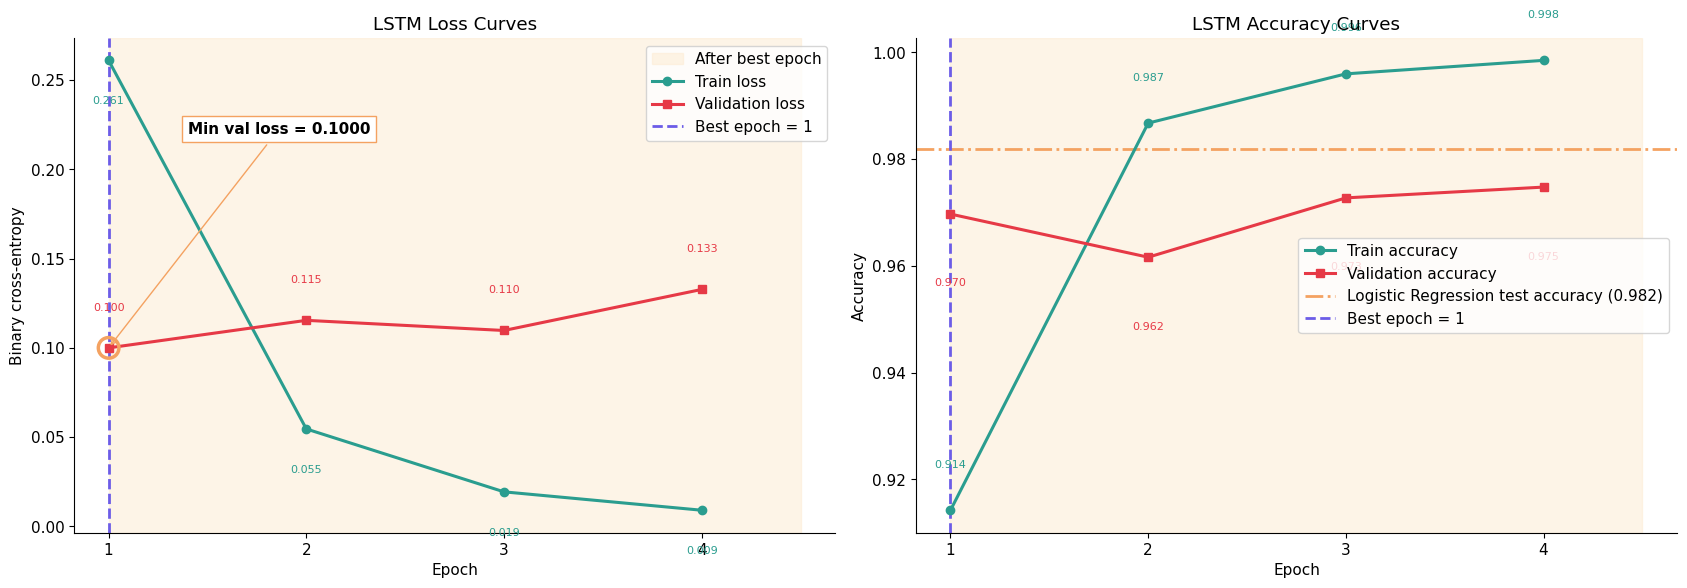

In [43]:
ep = np.arange(1, len(h) + 1)
best = int(h['val_loss'].idxmin())
lr_acc = results['Logistic Regression']['test']['accuracy']

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

ax = axes[0]
ax.axvspan(best, ep.max() + 0.5, color='#fdebd0', alpha=0.5, zorder=0, label='After best epoch')
ax.plot(ep, h['loss'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train loss', zorder=3)
ax.plot(ep, h['val_loss'], marker='s', color='#e63946', linewidth=2.2, label='Validation loss', zorder=3)
ax.axvline(best, color='#6c5ce7', linestyle='--', linewidth=2, label=f'Best epoch = {best}', zorder=2)
for e, a, b in zip(ep, h['loss'], h['val_loss']):
    ax.text(e, a - 0.02, f'{a:.3f}', ha='center', va='top', fontsize=8, color='#2a9d8f')
    ax.text(e, b + 0.02, f'{b:.3f}', ha='center', va='bottom', fontsize=8, color='#e63946')
bl = h.loc[best, 'val_loss']
ax.scatter([best], [bl], s=220, facecolor='none', edgecolor='#f4a261', linewidth=2.5, zorder=4)
ax.annotate(f'Min val loss = {bl:.4f}', xy=(best, bl), xytext=(best + 0.4, bl + 0.12),
            arrowprops=dict(arrowstyle='->', color='#f4a261'), fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='#f4a261'))
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary cross-entropy')
ax.set_title('LSTM Loss Curves')
ax.set_xticks(ep)
ax.legend(loc='upper right')

ax = axes[1]
ax.axvspan(best, ep.max() + 0.5, color='#fdebd0', alpha=0.5, zorder=0)
ax.plot(ep, h['accuracy'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train accuracy', zorder=3)
ax.plot(ep, h['val_accuracy'], marker='s', color='#e63946', linewidth=2.2, label='Validation accuracy', zorder=3)
ax.axhline(lr_acc, color='#f4a261', linestyle='-.', linewidth=2, label=f'Logistic Regression test accuracy ({lr_acc:.3f})', zorder=2)
ax.axvline(best, color='#6c5ce7', linestyle='--', linewidth=2, label=f'Best epoch = {best}', zorder=2)
for e, a, b in zip(ep, h['accuracy'], h['val_accuracy']):
    ax.text(e, a + 0.008, f'{a:.3f}', ha='center', fontsize=8, color='#2a9d8f')
    ax.text(e, b - 0.012, f'{b:.3f}', ha='center', va='top', fontsize=8, color='#e63946')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('LSTM Accuracy Curves')
ax.set_xticks(ep)
ax.legend(loc='center right')

plt.tight_layout()
plt.show()

In [44]:
lstm_val_prob = lstm.predict(Xs_val, verbose=0).ravel()
lstm_test_prob = lstm.predict(Xs_test, verbose=0).ravel()

results['LSTM'] = {'val': compute_metrics(y_val, lstm_val_prob),
                   'test': compute_metrics(y_test, lstm_test_prob),
                   'test_prob': lstm_test_prob,
                   'train_time': lstm_time,
                   'epochs': len(h),
                   'params': lstm.count_params()}
np.save('/content/prob_lstm.npy', lstm_test_prob)

r = results['LSTM']
print(pd.DataFrame({'Validation': r['val'], 'Test': r['test']}).round(4))
print('Parameters:', f"{r['params']:,}")
print('Training time (s):', round(r['train_time'], 2))
tn, fp, fn, tp = confusion_matrix(y_test, (lstm_test_prob >= 0.5).astype(int)).ravel()
print('TN, FP, FN, TP:', tn, fp, fn, tp)

           Validation    Test
accuracy       0.9697  0.9768
precision      0.9678  0.9816
recall         0.9717  0.9717
f1             0.9698  0.9766
auc            0.9938  0.9949
Parameters: 2,611,521
Training time (s): 20.98
TN, FP, FN, TP: 486 9 14 481


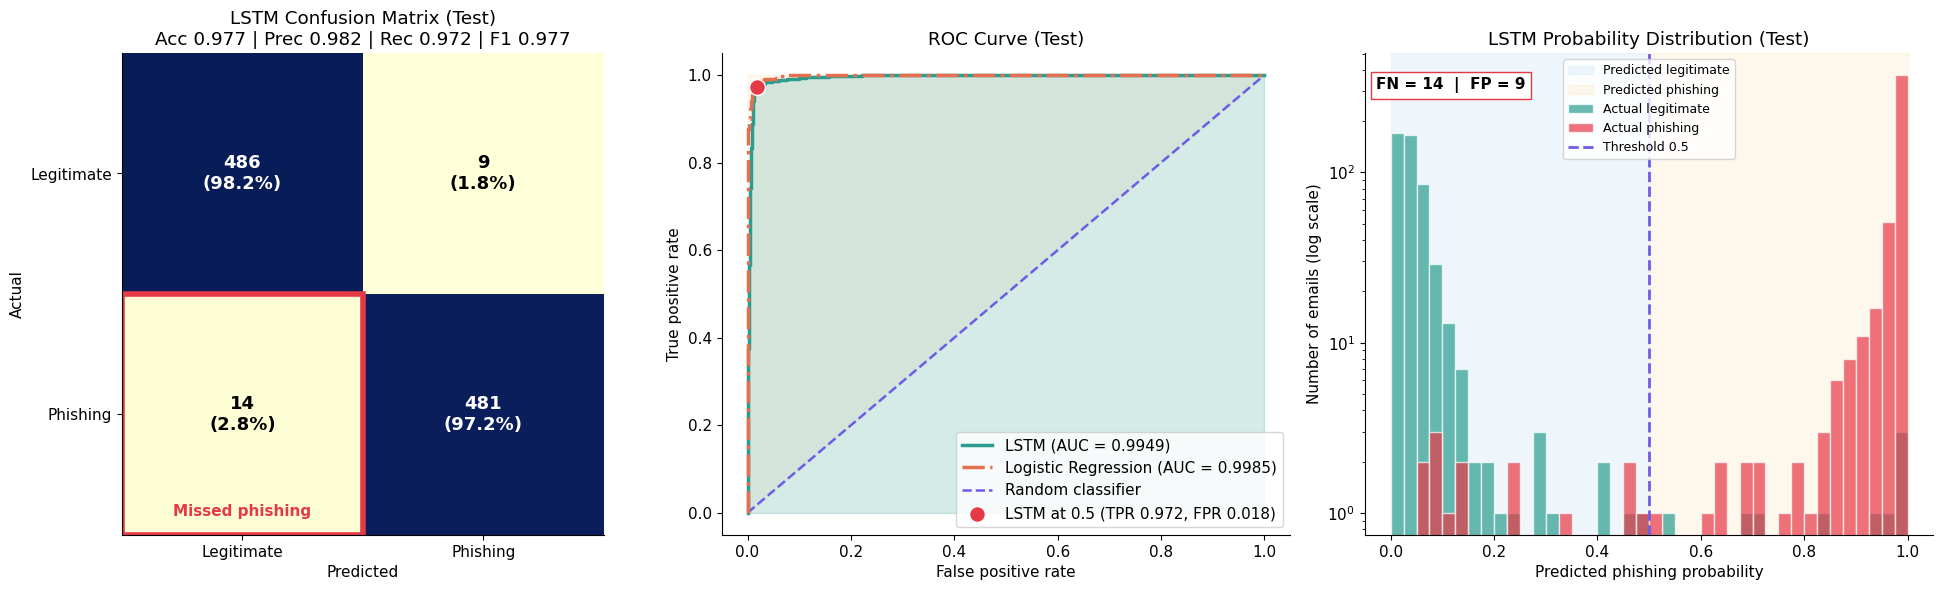

In [45]:
pred_l = (lstm_test_prob >= 0.5).astype(int)
cmx = confusion_matrix(y_test, pred_l)
mt = results['LSTM']['test']
lr_prob = results['Logistic Regression']['test_prob']
lr_auc = results['Logistic Regression']['test']['auc']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
ax.imshow(cmx, cmap='YlGnBu')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cmx[i, j]:,}\n({cmx[i, j] / cmx[i].sum() * 100:.1f}%)', ha='center', va='center',
                fontweight='bold', fontsize=13, color='white' if cmx[i, j] > cmx.max() / 2 else 'black')
ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor='#e63946', linewidth=4))
ax.text(0, 1.42, 'Missed phishing', ha='center', color='#e63946', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Legitimate', 'Phishing'])
ax.set_yticklabels(['Legitimate', 'Phishing'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f"LSTM Confusion Matrix (Test)\nAcc {mt['accuracy']:.3f} | Prec {mt['precision']:.3f} | Rec {mt['recall']:.3f} | F1 {mt['f1']:.3f}")

ax = axes[1]
f1_, t1_, th1 = roc_curve(y_test, lstm_test_prob)
f2_, t2_, _ = roc_curve(y_test, lr_prob)
ax.fill_between([0, 1], [0, 1], [1, 1], color='#fdebd0', alpha=0.35, zorder=0)
ax.fill_between(f1_, 0, t1_, color='#2a9d8f', alpha=0.2, zorder=1)
ax.plot(f1_, t1_, color='#2a9d8f', linewidth=2.5, label=f"LSTM (AUC = {mt['auc']:.4f})", zorder=3)
ax.plot(f2_, t2_, color='#e76f51', linewidth=2.5, linestyle='-.', label=f'Logistic Regression (AUC = {lr_auc:.4f})', zorder=3)
ax.plot([0, 1], [0, 1], color='#6c5ce7', linestyle='--', linewidth=1.8, label='Random classifier', zorder=2)
k = np.argmin(np.abs(th1 - 0.5))
ax.scatter(f1_[k], t1_[k], s=130, color='#e63946', edgecolor='white', zorder=5, label=f'LSTM at 0.5 (TPR {t1_[k]:.3f}, FPR {f1_[k]:.3f})')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC Curve (Test)')
ax.legend(loc='lower right')

ax = axes[2]
bins = np.linspace(0, 1, 41)
ax.axvspan(0, 0.5, color='#d6eaf8', alpha=0.4, zorder=0, label='Predicted legitimate')
ax.axvspan(0.5, 1, color='#fdebd0', alpha=0.4, zorder=0, label='Predicted phishing')
ax.hist(lstm_test_prob[y_test == 0], bins=bins, color='#2a9d8f', alpha=0.7, edgecolor='white', label='Actual legitimate', zorder=2)
ax.hist(lstm_test_prob[y_test == 1], bins=bins, color='#e63946', alpha=0.7, edgecolor='white', label='Actual phishing', zorder=2)
ax.axvline(0.5, color='#6c5ce7', linestyle='--', linewidth=2, label='Threshold 0.5', zorder=3)
ax.set_yscale('log')
ax.text(0.02, 0.95, f'FN = {cmx[1, 0]}  |  FP = {cmx[0, 1]}', transform=ax.transAxes, va='top', fontweight='bold',
        bbox=dict(facecolor='white', edgecolor='#e63946'))
ax.set_xlabel('Predicted phishing probability')
ax.set_ylabel('Number of emails (log scale)')
ax.set_title('LSTM Probability Distribution (Test)')
ax.legend(loc='upper center', fontsize=9)

plt.tight_layout()
plt.show()

# **BiLSTM**

In [46]:
bilstm = build_rnn(bidirectional=True)
bilstm.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 128)  │  2,560,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      4,128 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,662,977 (10.16 MB)

 Trainable params: 2,662,977 (10.16 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
histories = {'LSTM': h.copy()}
es_b = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
t0 = time.time()
hist_b = bilstm.fit(Xs_train, y_train, validation_data=(Xs_val, y_val),
                    epochs=10, batch_size=64, callbacks=[es_b], verbose=2)
bilstm_time = time.time() - t0

hb = pd.DataFrame(hist_b.history)
hb.index = np.arange(1, len(hb) + 1)
histories['BiLSTM'] = hb.copy()
print(hb.round(4))
print('Epochs run:', len(hb))
print('Best epoch (val_loss):', int(hb['val_loss'].idxmin()))
print('Training time (s):', round(bilstm_time, 2))

Epoch 1/10
124/124 - 8s - 61ms/step - accuracy: 0.9298 - loss: 0.2080 - val_accuracy: 0.9788 - val_loss: 0.0721
Epoch 2/10
124/124 - 5s - 38ms/step - accuracy: 0.9905 - loss: 0.0361 - val_accuracy: 0.9848 - val_loss: 0.0594
Epoch 3/10
124/124 - 5s - 40ms/step - accuracy: 0.9971 - loss: 0.0098 - val_accuracy: 0.9818 - val_loss: 0.0709
Epoch 4/10
124/124 - 8s - 65ms/step - accuracy: 0.9994 - loss: 0.0040 - val_accuracy: 0.9798 - val_loss: 0.0804
Epoch 5/10
124/124 - 4s - 33ms/step - accuracy: 0.9996 - loss: 0.0020 - val_accuracy: 0.9818 - val_loss: 0.0818
   accuracy    loss  val_accuracy  val_loss
1    0.9298  0.2080        0.9788    0.0721
2    0.9905  0.0361        0.9848    0.0594
3    0.9971  0.0098        0.9818    0.0709
4    0.9994  0.0040        0.9798    0.0804
5    0.9996  0.0020        0.9818    0.0818
Epochs run: 5
Best epoch (val_loss): 2
Training time (s): 29.45


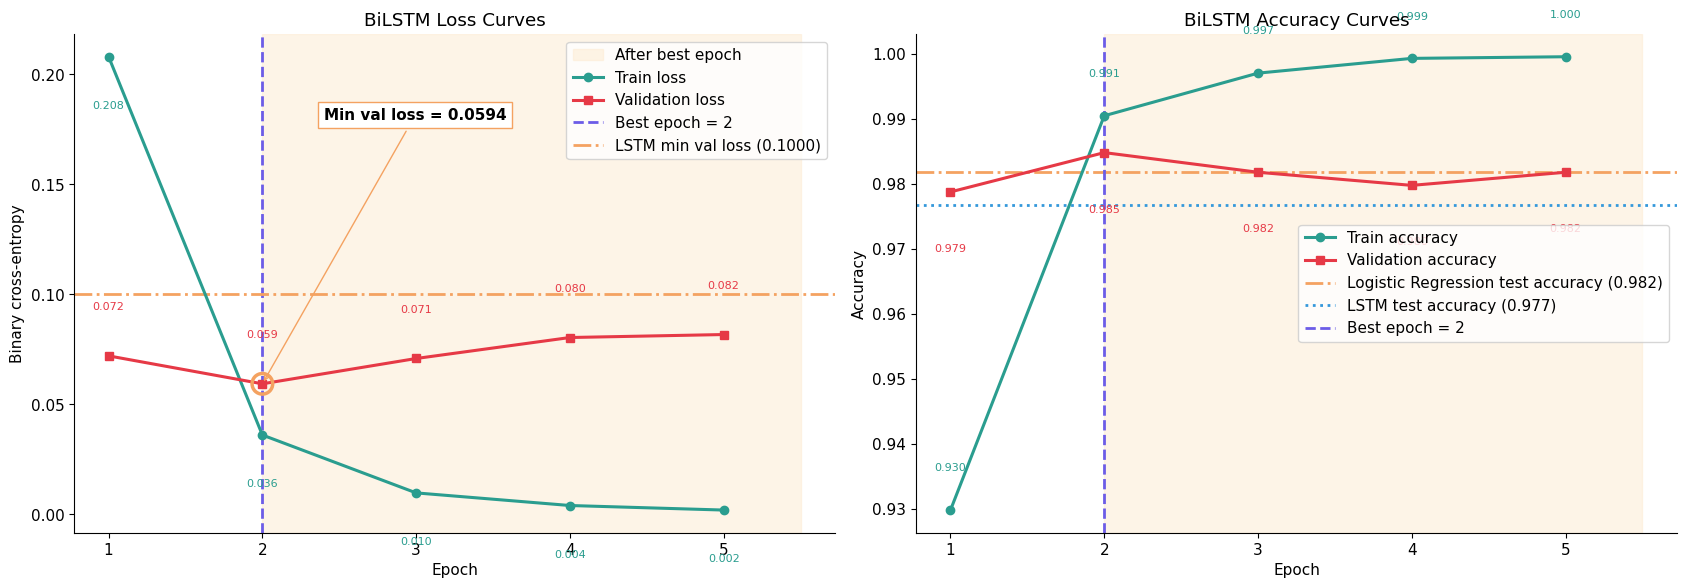

In [48]:
ep = np.arange(1, len(hb) + 1)
best_b = int(hb['val_loss'].idxmin())
lstm_min = h['val_loss'].min()
lr_acc = results['Logistic Regression']['test']['accuracy']
lstm_acc = results['LSTM']['test']['accuracy']

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

ax = axes[0]
ax.axvspan(best_b, ep.max() + 0.5, color='#fdebd0', alpha=0.5, zorder=0, label='After best epoch')
ax.plot(ep, hb['loss'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train loss', zorder=3)
ax.plot(ep, hb['val_loss'], marker='s', color='#e63946', linewidth=2.2, label='Validation loss', zorder=3)
ax.axvline(best_b, color='#6c5ce7', linestyle='--', linewidth=2, label=f'Best epoch = {best_b}', zorder=2)
ax.axhline(lstm_min, color='#f4a261', linestyle='-.', linewidth=2, label=f'LSTM min val loss ({lstm_min:.4f})', zorder=2)
for e, a, b in zip(ep, hb['loss'], hb['val_loss']):
    ax.text(e, a - 0.02, f'{a:.3f}', ha='center', va='top', fontsize=8, color='#2a9d8f')
    ax.text(e, b + 0.02, f'{b:.3f}', ha='center', va='bottom', fontsize=8, color='#e63946')
bl = hb.loc[best_b, 'val_loss']
ax.scatter([best_b], [bl], s=220, facecolor='none', edgecolor='#f4a261', linewidth=2.5, zorder=4)
ax.annotate(f'Min val loss = {bl:.4f}', xy=(best_b, bl), xytext=(best_b + 0.4, bl + 0.12),
            arrowprops=dict(arrowstyle='->', color='#f4a261'), fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='#f4a261'))
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary cross-entropy')
ax.set_title('BiLSTM Loss Curves')
ax.set_xticks(ep)
ax.legend(loc='upper right')

ax = axes[1]
ax.axvspan(best_b, ep.max() + 0.5, color='#fdebd0', alpha=0.5, zorder=0)
ax.plot(ep, hb['accuracy'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train accuracy', zorder=3)
ax.plot(ep, hb['val_accuracy'], marker='s', color='#e63946', linewidth=2.2, label='Validation accuracy', zorder=3)
ax.axhline(lr_acc, color='#f4a261', linestyle='-.', linewidth=2, label=f'Logistic Regression test accuracy ({lr_acc:.3f})', zorder=2)
ax.axhline(lstm_acc, color='#3498db', linestyle=':', linewidth=2, label=f'LSTM test accuracy ({lstm_acc:.3f})', zorder=2)
ax.axvline(best_b, color='#6c5ce7', linestyle='--', linewidth=2, label=f'Best epoch = {best_b}', zorder=2)
for e, a, b in zip(ep, hb['accuracy'], hb['val_accuracy']):
    ax.text(e, a + 0.006, f'{a:.3f}', ha='center', fontsize=8, color='#2a9d8f')
    ax.text(e, b - 0.008, f'{b:.3f}', ha='center', va='top', fontsize=8, color='#e63946')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('BiLSTM Accuracy Curves')
ax.set_xticks(ep)
ax.legend(loc='center right')

plt.tight_layout()
plt.show()

In [49]:
bi_val_prob = bilstm.predict(Xs_val, verbose=0).ravel()
bi_test_prob = bilstm.predict(Xs_test, verbose=0).ravel()

results['BiLSTM'] = {'val': compute_metrics(y_val, bi_val_prob),
                     'test': compute_metrics(y_test, bi_test_prob),
                     'test_prob': bi_test_prob,
                     'train_time': bilstm_time,
                     'epochs': len(hb),
                     'params': bilstm.count_params()}
np.save('/content/prob_bilstm.npy', bi_test_prob)

r = results['BiLSTM']
print(pd.DataFrame({'Validation': r['val'], 'Test': r['test']}).round(4))
print('Parameters:', f"{r['params']:,}")
print('Training time (s):', round(r['train_time'], 2))
tn, fp, fn, tp = confusion_matrix(y_test, (bi_test_prob >= 0.5).astype(int)).ravel()
print('TN, FP, FN, TP:', tn, fp, fn, tp)

           Validation    Test
accuracy       0.9848  0.9838
precision      0.9743  0.9819
recall         0.9960  0.9859
f1             0.9850  0.9839
auc            0.9979  0.9980
Parameters: 2,662,977
Training time (s): 29.45
TN, FP, FN, TP: 486 9 7 488


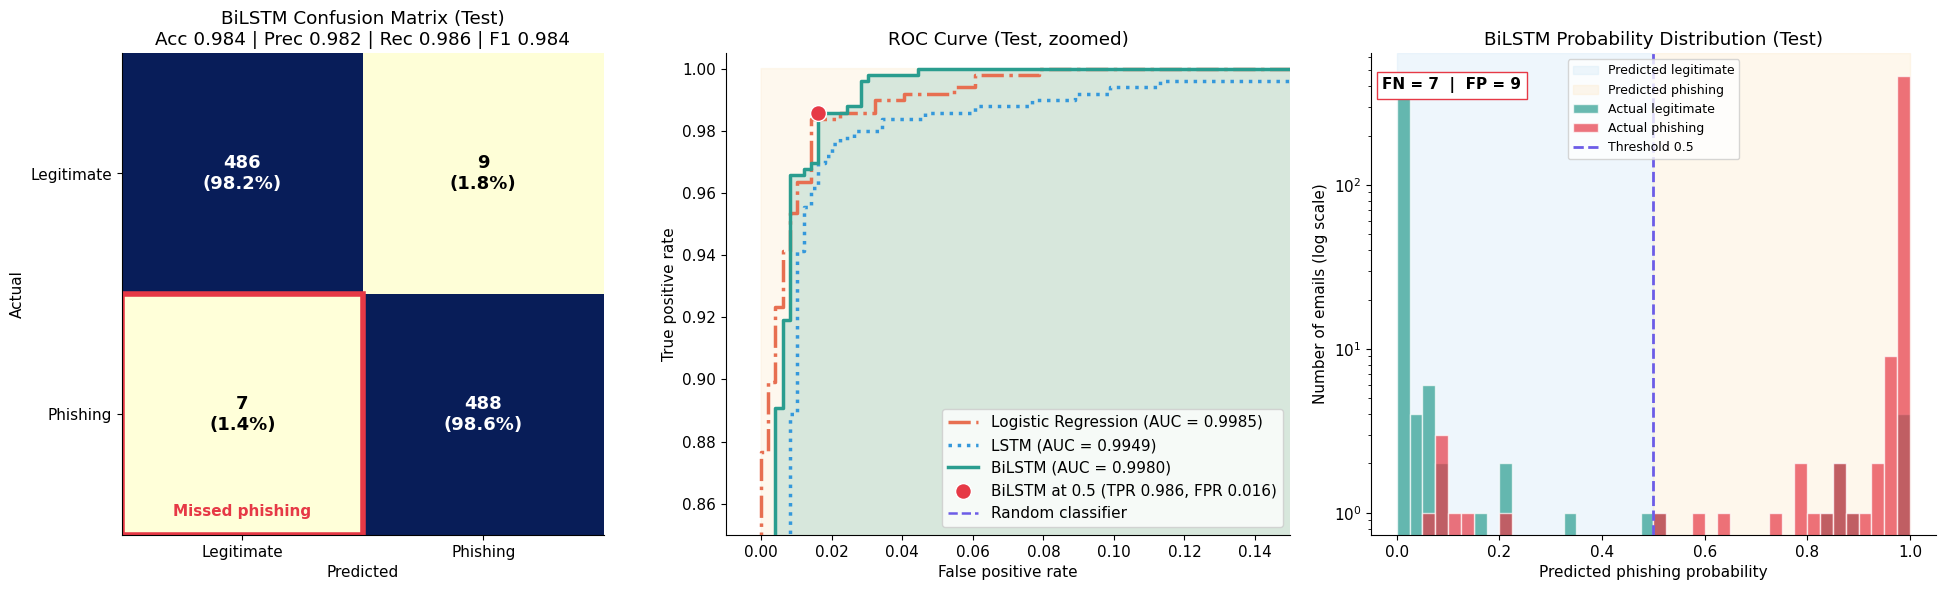

In [50]:
pred_b = (bi_test_prob >= 0.5).astype(int)
cmx = confusion_matrix(y_test, pred_b)
mt = results['BiLSTM']['test']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
ax.imshow(cmx, cmap='YlGnBu')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cmx[i, j]:,}\n({cmx[i, j] / cmx[i].sum() * 100:.1f}%)', ha='center', va='center',
                fontweight='bold', fontsize=13, color='white' if cmx[i, j] > cmx.max() / 2 else 'black')
ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor='#e63946', linewidth=4))
ax.text(0, 1.42, 'Missed phishing', ha='center', color='#e63946', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Legitimate', 'Phishing'])
ax.set_yticklabels(['Legitimate', 'Phishing'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f"BiLSTM Confusion Matrix (Test)\nAcc {mt['accuracy']:.3f} | Prec {mt['precision']:.3f} | Rec {mt['recall']:.3f} | F1 {mt['f1']:.3f}")

ax = axes[1]
ax.fill_between([0, 1], [0, 1], [1, 1], color='#fdebd0', alpha=0.35, zorder=0)
curves = [('Logistic Regression', '#e76f51', '-.'), ('LSTM', '#3498db', ':'), ('BiLSTM', '#2a9d8f', '-')]
for name, col, ls in curves:
    fp_, tp_, th_ = roc_curve(y_test, results[name]['test_prob'])
    ax.plot(fp_, tp_, color=col, linestyle=ls, linewidth=2.5, label=f"{name} (AUC = {results[name]['test']['auc']:.4f})", zorder=3)
    if name == 'BiLSTM':
        ax.fill_between(fp_, 0, tp_, color=col, alpha=0.18, zorder=1)
        k = np.argmin(np.abs(th_ - 0.5))
        ax.scatter(fp_[k], tp_[k], s=130, color='#e63946', edgecolor='white', zorder=5,
                   label=f'BiLSTM at 0.5 (TPR {tp_[k]:.3f}, FPR {fp_[k]:.3f})')
ax.plot([0, 1], [0, 1], color='#6c5ce7', linestyle='--', linewidth=1.8, label='Random classifier', zorder=2)
ax.set_xlim(-0.01, 0.15)
ax.set_ylim(0.85, 1.005)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC Curve (Test, zoomed)')
ax.legend(loc='lower right')

ax = axes[2]
bins = np.linspace(0, 1, 41)
ax.axvspan(0, 0.5, color='#d6eaf8', alpha=0.4, zorder=0, label='Predicted legitimate')
ax.axvspan(0.5, 1, color='#fdebd0', alpha=0.4, zorder=0, label='Predicted phishing')
ax.hist(bi_test_prob[y_test == 0], bins=bins, color='#2a9d8f', alpha=0.7, edgecolor='white', label='Actual legitimate', zorder=2)
ax.hist(bi_test_prob[y_test == 1], bins=bins, color='#e63946', alpha=0.7, edgecolor='white', label='Actual phishing', zorder=2)
ax.axvline(0.5, color='#6c5ce7', linestyle='--', linewidth=2, label='Threshold 0.5', zorder=3)
ax.set_yscale('log')
ax.text(0.02, 0.95, f'FN = {cmx[1, 0]}  |  FP = {cmx[0, 1]}', transform=ax.transAxes, va='top', fontweight='bold',
        bbox=dict(facecolor='white', edgecolor='#e63946'))
ax.set_xlabel('Predicted phishing probability')
ax.set_ylabel('Number of emails (log scale)')
ax.set_title('BiLSTM Probability Distribution (Test)')
ax.legend(loc='upper center', fontsize=9)

plt.tight_layout()
plt.show()

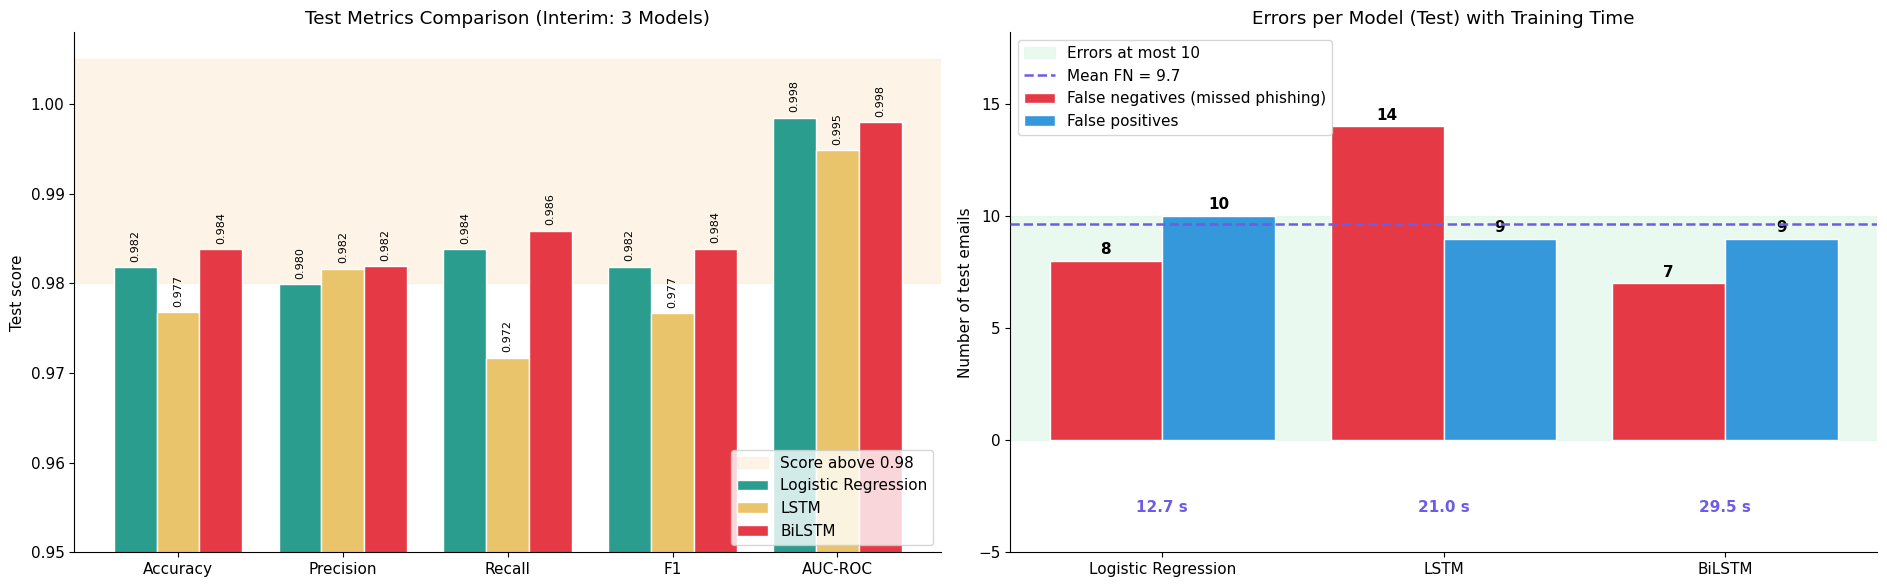

{'Logistic Regression': 8, 'LSTM': 14, 'BiLSTM': 7}
Missed by all three: 3
Missed by at least one: 18


In [51]:
models = ['Logistic Regression', 'LSTM', 'BiLSTM']
metric_names = ['accuracy', 'precision', 'recall', 'f1', 'auc']
palette = ['#2a9d8f', '#e9c46a', '#e63946']
preds = {m: (results[m]['test_prob'] >= 0.5).astype(int) for m in models}
fn_n = [int(((y_test == 1) & (preds[m] == 0)).sum()) for m in models]
fp_n = [int(((y_test == 0) & (preds[m] == 1)).sum()) for m in models]

fig, axes = plt.subplots(1, 2, figsize=(19, 6))

ax = axes[0]
x = np.arange(len(metric_names))
w = 0.26
ax.axhspan(0.98, 1.005, color='#fdebd0', alpha=0.5, zorder=0, label='Score above 0.98')
for i, (m, c) in enumerate(zip(models, palette)):
    v = [results[m]['test'][k] for k in metric_names]
    bars = ax.bar(x + (i - 1) * w, v, w, color=c, edgecolor='white', label=m, zorder=2)
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.0006, f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1', 'AUC-ROC'])
ax.set_ylim(0.95, 1.008)
ax.set_ylabel('Test score')
ax.set_title('Test Metrics Comparison (Interim: 3 Models)')
ax.legend(loc='lower right')

ax = axes[1]
x = np.arange(len(models))
ax.axhspan(0, 10, color='#d5f5e3', alpha=0.5, zorder=0, label='Errors at most 10')
b1 = ax.bar(x - 0.2, fn_n, 0.4, color='#e63946', edgecolor='white', label='False negatives (missed phishing)', zorder=2)
b2 = ax.bar(x + 0.2, fp_n, 0.4, color='#3498db', edgecolor='white', label='False positives', zorder=2)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f'{int(b.get_height())}', ha='center', fontweight='bold')
for i, m in enumerate(models):
    ax.text(i, -3.2, f"{results[m]['train_time']:.1f} s", ha='center', fontweight='bold', color='#6c5ce7')
ax.axhline(np.mean(fn_n), color='#6c5ce7', linestyle='--', linewidth=1.8, label=f'Mean FN = {np.mean(fn_n):.1f}', zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(-5, max(fn_n + fp_n) * 1.3)
ax.set_ylabel('Number of test emails')
ax.set_title('Errors per Model (Test) with Training Time')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

fn_sets = {m: set(np.where((y_test == 1) & (preds[m] == 0))[0]) for m in models}
print({m: len(s) for m, s in fn_sets.items()})
print('Missed by all three:', len(set.intersection(*fn_sets.values())))
print('Missed by at least one:', len(set.union(*fn_sets.values())))

# **DistilBERT**

In [52]:
import time
import random
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification, get_linear_schedule_with_warmup

with open('/content/results_backup.pkl', 'wb') as f:
    pickle.dump({'results': results, 'histories': histories}, f)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    free, total = torch.cuda.mem_get_info()
    print('GPU:', torch.cuda.get_device_name(0))
    print('Free GPU memory (GB):', round(free / 1e9, 2), 'of', round(total / 1e9, 2))

MAX_TOK = 128
tokenizer = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')

def encode(texts):
    enc = tokenizer(texts.tolist(), truncation=True, padding='max_length', max_length=MAX_TOK, return_tensors='pt')
    return enc['input_ids'], enc['attention_mask']

t0 = time.time()
tr_ids, tr_mask = encode(train_df['text'])
va_ids, va_mask = encode(val_df['text'])
te_ids, te_mask = encode(test_df['text'])
print('Tokenisation time (s):', round(time.time() - t0, 2))
print(tr_ids.shape, va_ids.shape, te_ids.shape)
full = tokenizer(train_df['text'].tolist(), truncation=False, add_special_tokens=True)['input_ids']
lens = np.array([len(x) for x in full])
print('Train emails truncated at 128 tokens (%):', round((lens > MAX_TOK).mean() * 100, 1))
print('Median token length:', int(np.median(lens)))

Device: cuda
GPU: Tesla T4
Free GPU memory (GB): 15.23 of 15.64


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenisation time (s): 13.15
torch.Size([7916, 128]) torch.Size([990, 128]) torch.Size([990, 128])


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (542 > 512). Running this sequence through the model will result in indexing errors


Train emails truncated at 128 tokens (%): 66.6
Median token length: 186


In [53]:
BATCH = 32
EPOCHS = 4
LR = 2e-5

train_loader = DataLoader(TensorDataset(tr_ids, tr_mask, torch.tensor(y_train)), batch_size=BATCH, shuffle=True)
val_loader = DataLoader(TensorDataset(va_ids, va_mask, torch.tensor(y_val)), batch_size=64)
test_loader = DataLoader(TensorDataset(te_ids, te_mask, torch.tensor(y_test)), batch_size=64)

model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
scaler = torch.amp.GradScaler('cuda')

def evaluate(loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    probs = []
    with torch.no_grad():
        for ids, mask, yb in loader:
            ids, mask, yb = ids.to(device), mask.to(device), yb.to(device)
            with torch.autocast('cuda', dtype=torch.float16):
                logits = model(input_ids=ids, attention_mask=mask).logits
            loss_sum += criterion(logits.float(), yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
            probs.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
    return loss_sum / n, correct / n, np.concatenate(probs)

print('Parameters:', f"{sum(p.numel() for p in model.parameters()):,}")
print('Steps per epoch:', len(train_loader), '| total steps:', total_steps)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 66,955,010
Steps per epoch: 248 | total steps: 992


In [54]:
hist_d = []
best_val = float('inf')
best_state = None
best_epoch = 0
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    te0 = time.time()
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for ids, mask, yb in train_loader:
        ids, mask, yb = ids.to(device), mask.to(device), yb.to(device)
        optimizer.zero_grad()
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(input_ids=ids, attention_mask=mask).logits
        loss = criterion(logits.float(), yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    v_loss, v_acc, _ = evaluate(val_loader)
    hist_d.append({'loss': loss_sum / n, 'accuracy': correct / n, 'val_loss': v_loss, 'val_accuracy': v_acc,
                   'epoch_time': time.time() - te0})
    if v_loss < best_val:
        best_val, best_epoch = v_loss, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch {epoch}/{EPOCHS} | loss {loss_sum / n:.4f} | acc {correct / n:.4f} | val_loss {v_loss:.4f} | val_acc {v_acc:.4f} | {time.time() - te0:.1f}s")

distil_time = time.time() - t0
model.load_state_dict(best_state)
hd = pd.DataFrame(hist_d)
hd.index = np.arange(1, len(hd) + 1)
histories['DistilBERT'] = hd.copy()
print(hd.round(4))
print('Best epoch (val_loss):', best_epoch)
print('Training time (s):', round(distil_time, 2))

Epoch 1/4 | loss 0.2455 | acc 0.9017 | val_loss 0.0877 | val_acc 0.9707 | 36.2s
Epoch 2/4 | loss 0.0560 | acc 0.9843 | val_loss 0.0608 | val_acc 0.9838 | 33.5s
Epoch 3/4 | loss 0.0258 | acc 0.9937 | val_loss 0.0747 | val_acc 0.9848 | 31.7s
Epoch 4/4 | loss 0.0156 | acc 0.9966 | val_loss 0.0699 | val_acc 0.9818 | 31.4s
     loss  accuracy  val_loss  val_accuracy  epoch_time
1  0.2455    0.9017    0.0877        0.9707     35.7955
2  0.0560    0.9843    0.0608        0.9838     32.8403
3  0.0258    0.9937    0.0747        0.9848     31.7293
4  0.0156    0.9966    0.0699        0.9818     31.4171
Best epoch (val_loss): 2
Training time (s): 132.87


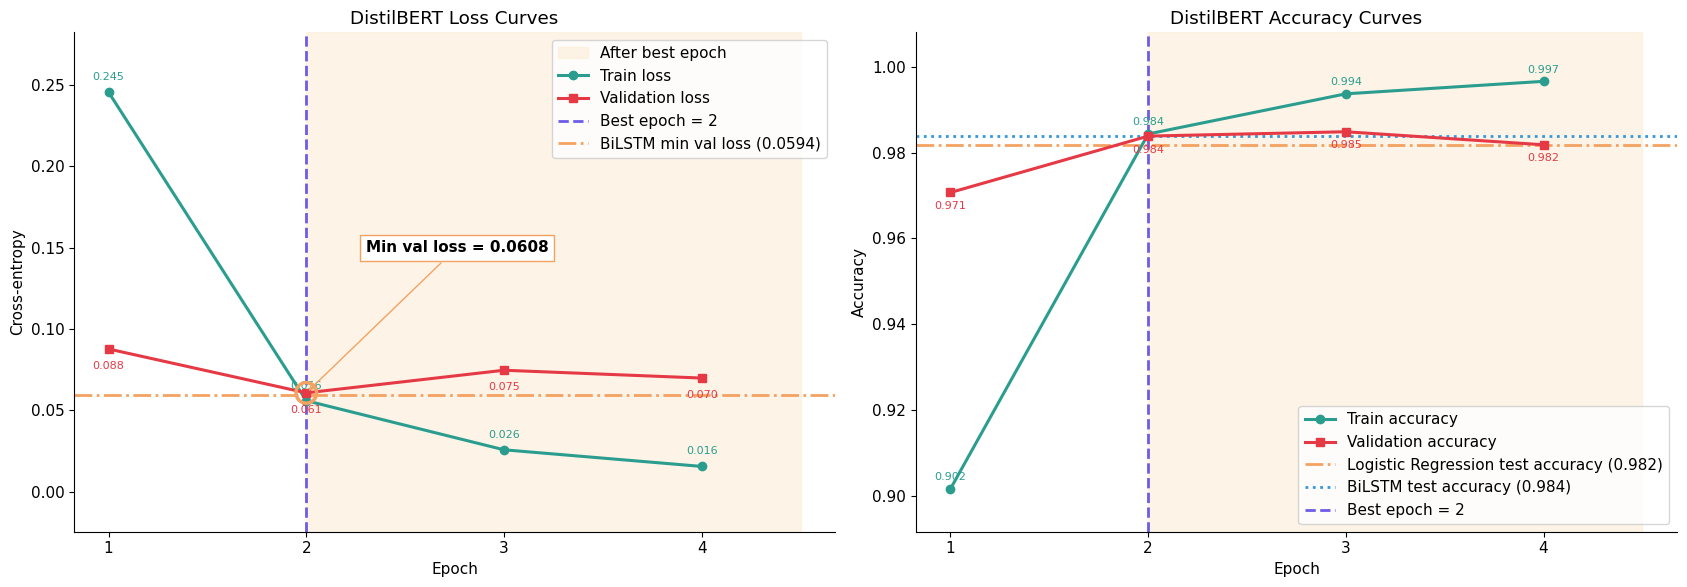

In [55]:
ep = np.arange(1, len(hd) + 1)
bl = hd.loc[best_epoch, 'val_loss']
bilstm_acc = results['BiLSTM']['test']['accuracy']
lr_acc = results['Logistic Regression']['test']['accuracy']

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

ax = axes[0]
ax.axvspan(best_epoch, ep.max() + 0.5, color='#fdebd0', alpha=0.5, zorder=0, label='After best epoch')
ax.plot(ep, hd['loss'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train loss', zorder=3)
ax.plot(ep, hd['val_loss'], marker='s', color='#e63946', linewidth=2.2, label='Validation loss', zorder=3)
ax.axvline(best_epoch, color='#6c5ce7', linestyle='--', linewidth=2, label=f'Best epoch = {best_epoch}', zorder=2)
ax.axhline(results['BiLSTM']['val']['auc'] * 0 + histories['BiLSTM']['val_loss'].min(), color='#f4a261', linestyle='-.',
           linewidth=2, label=f"BiLSTM min val loss ({histories['BiLSTM']['val_loss'].min():.4f})", zorder=2)
ymax = max(hd['loss'].max(), hd['val_loss'].max())
for e, a, b in zip(ep, hd['loss'], hd['val_loss']):
    ax.text(e, a + ymax * 0.03, f'{a:.3f}', ha='center', fontsize=8, color='#2a9d8f')
    ax.text(e, b - ymax * 0.03, f'{b:.3f}', ha='center', va='top', fontsize=8, color='#e63946')
ax.scatter([best_epoch], [bl], s=220, facecolor='none', edgecolor='#f4a261', linewidth=2.5, zorder=4)
ax.annotate(f'Min val loss = {bl:.4f}', xy=(best_epoch, bl), xytext=(best_epoch + 0.3, ymax * 0.6),
            arrowprops=dict(arrowstyle='->', color='#f4a261'), fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='#f4a261'))
ax.set_ylim(-ymax * 0.1, ymax * 1.15)
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-entropy')
ax.set_title('DistilBERT Loss Curves')
ax.set_xticks(ep)
ax.legend(loc='upper right')

ax = axes[1]
ax.axvspan(best_epoch, ep.max() + 0.5, color='#fdebd0', alpha=0.5, zorder=0)
ax.plot(ep, hd['accuracy'], marker='o', color='#2a9d8f', linewidth=2.2, label='Train accuracy', zorder=3)
ax.plot(ep, hd['val_accuracy'], marker='s', color='#e63946', linewidth=2.2, label='Validation accuracy', zorder=3)
ax.axhline(lr_acc, color='#f4a261', linestyle='-.', linewidth=2, label=f'Logistic Regression test accuracy ({lr_acc:.3f})', zorder=2)
ax.axhline(bilstm_acc, color='#3498db', linestyle=':', linewidth=2, label=f'BiLSTM test accuracy ({bilstm_acc:.3f})', zorder=2)
ax.axvline(best_epoch, color='#6c5ce7', linestyle='--', linewidth=2, label=f'Best epoch = {best_epoch}', zorder=2)
lo = min(hd['accuracy'].min(), hd['val_accuracy'].min()) - 0.01
for e, a, b in zip(ep, hd['accuracy'], hd['val_accuracy']):
    ax.text(e, a + 0.002, f'{a:.3f}', ha='center', fontsize=8, color='#2a9d8f')
    ax.text(e, b - 0.002, f'{b:.3f}', ha='center', va='top', fontsize=8, color='#e63946')
ax.set_ylim(lo, 1.008)
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('DistilBERT Accuracy Curves')
ax.set_xticks(ep)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [56]:
_, _, d_val_prob = evaluate(val_loader)
torch.cuda.synchronize()
ti0 = time.time()
_, _, d_test_prob = evaluate(test_loader)
torch.cuda.synchronize()
infer_time = time.time() - ti0

results['DistilBERT'] = {'val': compute_metrics(y_val, d_val_prob),
                         'test': compute_metrics(y_test, d_test_prob),
                         'test_prob': d_test_prob,
                         'train_time': distil_time,
                         'epochs': len(hd),
                         'params': sum(p.numel() for p in model.parameters()),
                         'infer_time': infer_time}
np.save('/content/prob_distilbert.npy', d_test_prob)
with open('/content/results_backup.pkl', 'wb') as f:
    pickle.dump({'results': results, 'histories': histories}, f)

r = results['DistilBERT']
print(pd.DataFrame({'Validation': r['val'], 'Test': r['test']}).round(4))
print('Parameters:', f"{r['params']:,}")
print('Training time (s):', round(r['train_time'], 2))
print('Test inference time (s):', round(infer_time, 2))
tn, fp, fn, tp = confusion_matrix(y_test, (d_test_prob >= 0.5).astype(int)).ravel()
print('TN, FP, FN, TP:', tn, fp, fn, tp)

           Validation    Test
accuracy       0.9838  0.9828
precision      0.9858  0.9878
recall         0.9818  0.9778
f1             0.9838  0.9827
auc            0.9971  0.9964
Parameters: 66,955,010
Training time (s): 132.87
Test inference time (s): 1.0
TN, FP, FN, TP: 489 6 11 484


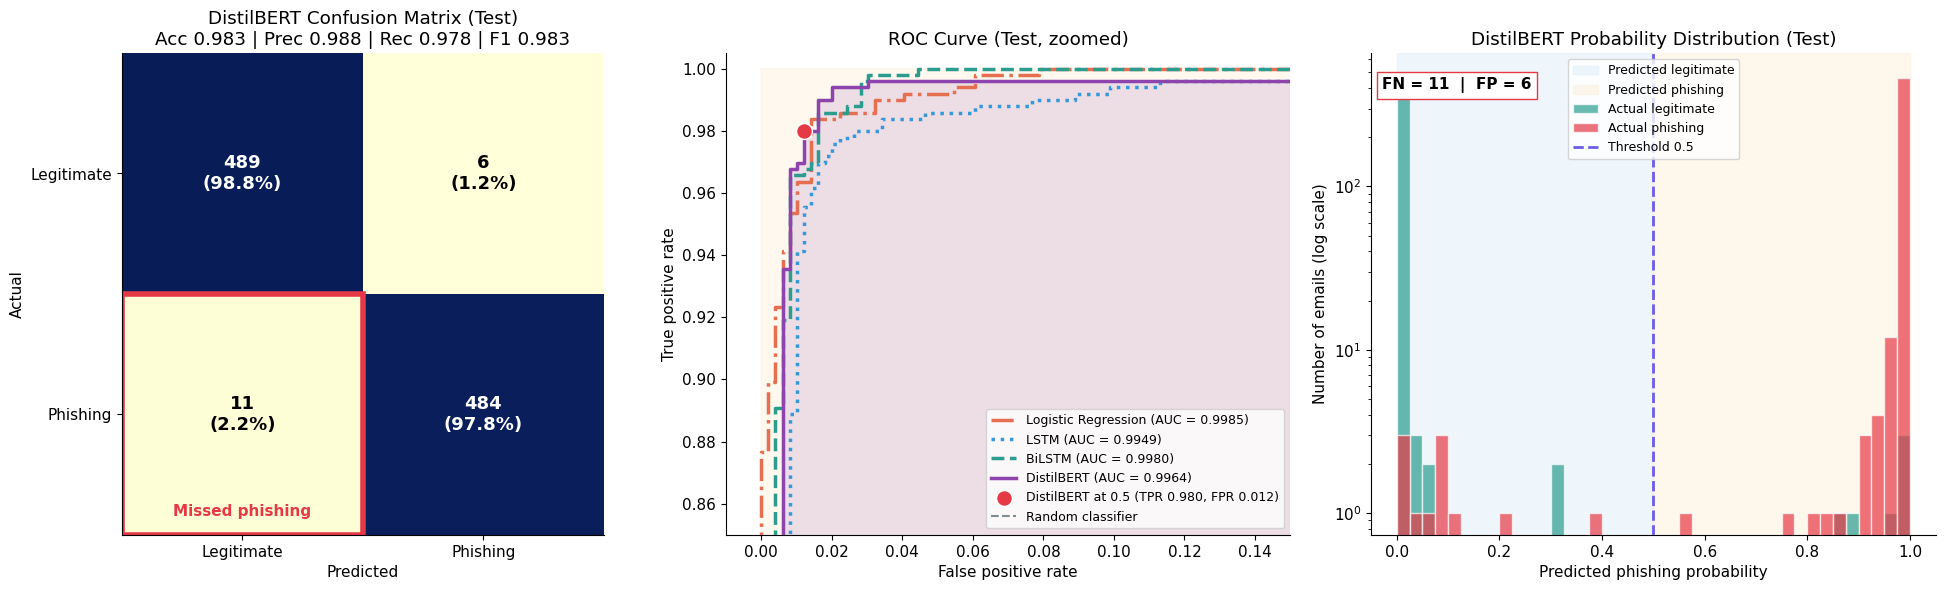

In [57]:
pred_d = (d_test_prob >= 0.5).astype(int)
cmx = confusion_matrix(y_test, pred_d)
mt = results['DistilBERT']['test']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
ax.imshow(cmx, cmap='YlGnBu')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cmx[i, j]:,}\n({cmx[i, j] / cmx[i].sum() * 100:.1f}%)', ha='center', va='center',
                fontweight='bold', fontsize=13, color='white' if cmx[i, j] > cmx.max() / 2 else 'black')
ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor='#e63946', linewidth=4))
ax.text(0, 1.42, 'Missed phishing', ha='center', color='#e63946', fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Legitimate', 'Phishing'])
ax.set_yticklabels(['Legitimate', 'Phishing'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f"DistilBERT Confusion Matrix (Test)\nAcc {mt['accuracy']:.3f} | Prec {mt['precision']:.3f} | Rec {mt['recall']:.3f} | F1 {mt['f1']:.3f}")

ax = axes[1]
ax.fill_between([0, 1], [0, 1], [1, 1], color='#fdebd0', alpha=0.35, zorder=0)
curves = [('Logistic Regression', '#e76f51', '-.'), ('LSTM', '#3498db', ':'), ('BiLSTM', '#2a9d8f', '--'), ('DistilBERT', '#8e44ad', '-')]
for name, col, ls in curves:
    fp_, tp_, th_ = roc_curve(y_test, results[name]['test_prob'])
    ax.plot(fp_, tp_, color=col, linestyle=ls, linewidth=2.5, label=f"{name} (AUC = {results[name]['test']['auc']:.4f})", zorder=3)
    if name == 'DistilBERT':
        ax.fill_between(fp_, 0, tp_, color=col, alpha=0.15, zorder=1)
        k = np.argmin(np.abs(th_ - 0.5))
        ax.scatter(fp_[k], tp_[k], s=130, color='#e63946', edgecolor='white', zorder=5,
                   label=f'DistilBERT at 0.5 (TPR {tp_[k]:.3f}, FPR {fp_[k]:.3f})')
ax.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', linewidth=1.5, label='Random classifier', zorder=2)
ax.set_xlim(-0.01, 0.15)
ax.set_ylim(0.85, 1.005)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC Curve (Test, zoomed)')
ax.legend(loc='lower right', fontsize=9)

ax = axes[2]
bins = np.linspace(0, 1, 41)
ax.axvspan(0, 0.5, color='#d6eaf8', alpha=0.4, zorder=0, label='Predicted legitimate')
ax.axvspan(0.5, 1, color='#fdebd0', alpha=0.4, zorder=0, label='Predicted phishing')
ax.hist(d_test_prob[y_test == 0], bins=bins, color='#2a9d8f', alpha=0.7, edgecolor='white', label='Actual legitimate', zorder=2)
ax.hist(d_test_prob[y_test == 1], bins=bins, color='#e63946', alpha=0.7, edgecolor='white', label='Actual phishing', zorder=2)
ax.axvline(0.5, color='#6c5ce7', linestyle='--', linewidth=2, label='Threshold 0.5', zorder=3)
ax.set_yscale('log')
ax.text(0.02, 0.95, f'FN = {cmx[1, 0]}  |  FP = {cmx[0, 1]}', transform=ax.transAxes, va='top', fontweight='bold',
        bbox=dict(facecolor='white', edgecolor='#e63946'))
ax.set_xlabel('Predicted phishing probability')
ax.set_ylabel('Number of emails (log scale)')
ax.set_title('DistilBERT Probability Distribution (Test)')
ax.legend(loc='upper center', fontsize=9)

plt.tight_layout()
plt.show()

# **Evaluation of all**

                     Accuracy  Precision    Recall  F1-Score   AUC-ROC  FN  FP  Train (s)    Params
Model                                                                                              
Logistic Regression  0.981818   0.979879  0.983838  0.981855  0.998490   8  10       12.7       N/A
LSTM                 0.976768   0.981633  0.971717  0.976650  0.994878  14   9       21.0   2611521
BiLSTM               0.983838   0.981891  0.985859  0.983871  0.998000   7   9       29.5   2662977
DistilBERT           0.982828   0.987755  0.977778  0.982741  0.996364  11   6      132.9  66955010


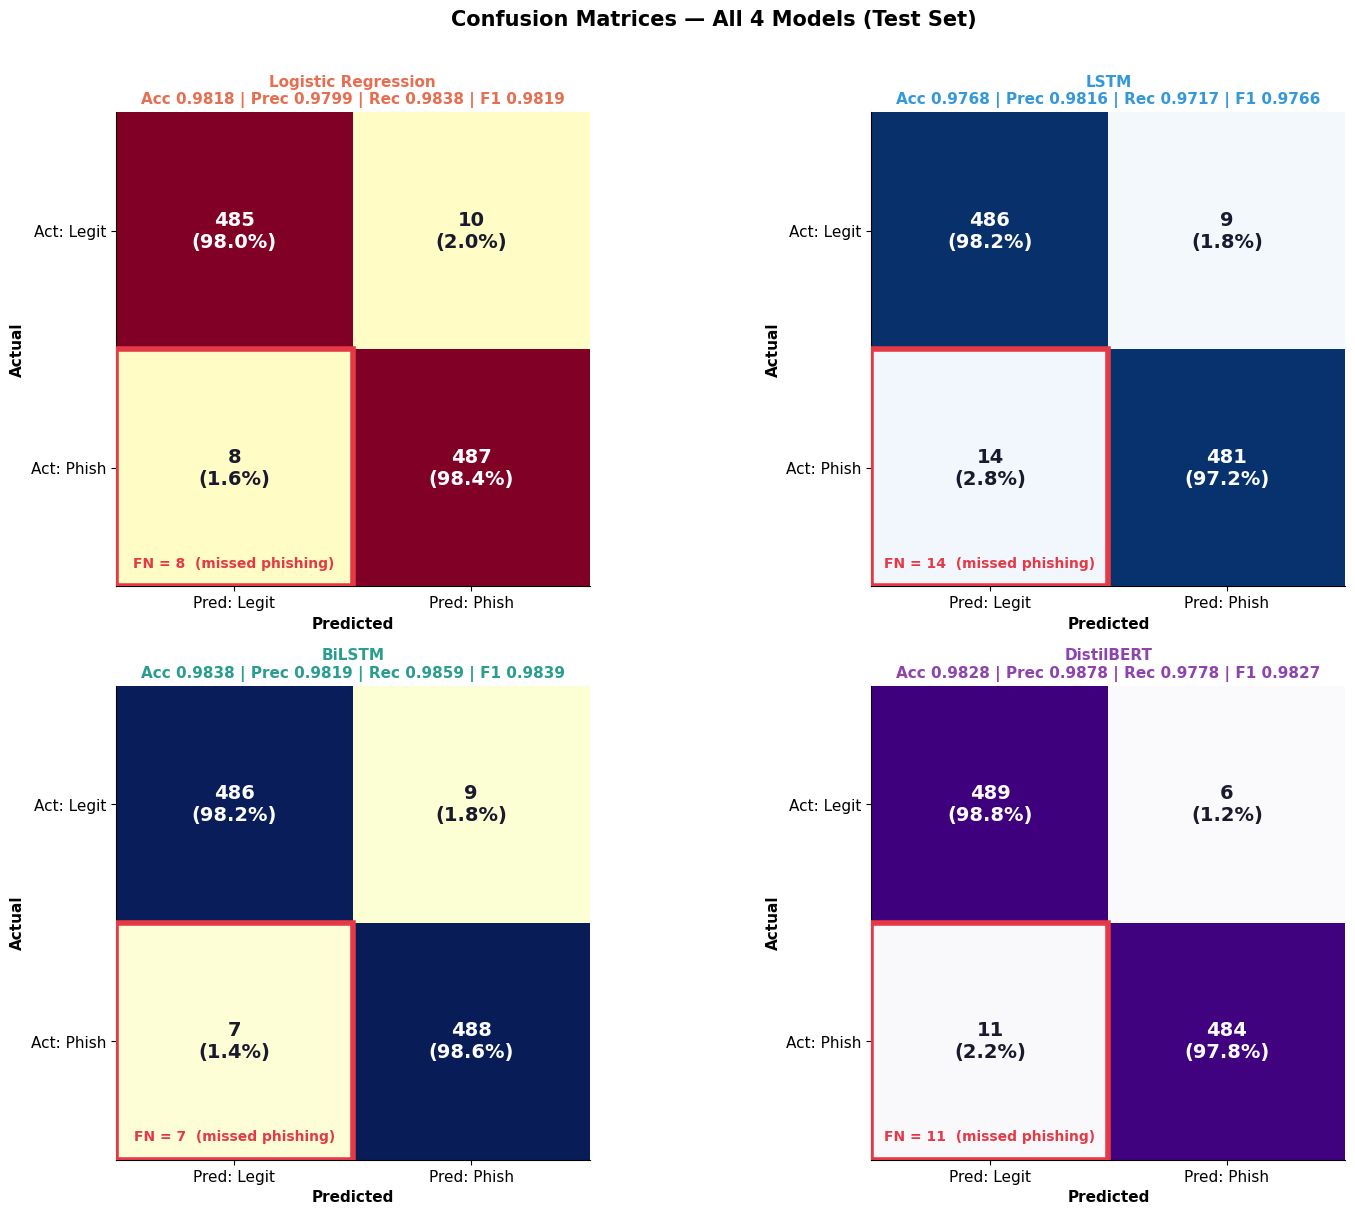

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve,
    precision_recall_curve, average_precision_score
)

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

MODEL_ORDER  = ['Logistic Regression', 'LSTM', 'BiLSTM', 'DistilBERT']
PALETTE      = ['#e76f51', '#3498db', '#2a9d8f', '#8e44ad']
CMAP_LIST    = ['YlOrRd', 'Blues', 'YlGnBu', 'Purples']
METRICS      = ['accuracy', 'precision', 'recall', 'f1', 'auc']
METRIC_LABEL = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']

rows = []
for m in MODEL_ORDER:
    r = results[m]['test']
    rows.append({
        'Model'     : m,
        'Accuracy'  : r['accuracy'],
        'Precision' : r['precision'],
        'Recall'    : r['recall'],
        'F1-Score'  : r['f1'],
        'AUC-ROC'   : r['auc'],
        'FN'        : int(((y_test == 1) & ((results[m]['test_prob'] >= 0.5).astype(int) == 0)).sum()),
        'FP'        : int(((y_test == 0) & ((results[m]['test_prob'] >= 0.5).astype(int) == 1)).sum()),
        'Train (s)' : round(results[m]['train_time'], 1),
        'Params'    : results[m].get('params', 'N/A')
    })

summary = pd.DataFrame(rows).set_index('Model')
print(summary.to_string())

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for ax, model, cmap_name, col in zip(axes, MODEL_ORDER, CMAP_LIST, PALETTE):
    prob  = results[model]['test_prob']
    pred  = (prob >= 0.5).astype(int)
    cmx   = confusion_matrix(y_test, pred)
    mt    = results[model]['test']
    cmap  = plt.get_cmap(cmap_name)

    im = ax.imshow(cmx, cmap=cmap, vmin=0, vmax=cmx.max())

    for i in range(2):
        for j in range(2):
            pct  = cmx[i, j] / cmx[i].sum() * 100
            dark = cmx[i, j] > cmx.max() * 0.55
            ax.text(j, i, f'{cmx[i, j]:,}\n({pct:.1f}%)',
                    ha='center', va='center', fontsize=14, fontweight='bold',
                    color='white' if dark else '#1a1a2e')

    ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1,
                               fill=False, edgecolor='#e63946', linewidth=4, zorder=3))
    ax.text(0, 1.42, f'FN = {cmx[1,0]}  (missed phishing)',
            ha='center', color='#e63946', fontweight='bold', fontsize=10)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred: Legit', 'Pred: Phish'])
    ax.set_yticklabels(['Act: Legit', 'Act: Phish'])
    ax.set_xlabel('Predicted', fontweight='bold')
    ax.set_ylabel('Actual', fontweight='bold')
    ax.set_title(
        f'{model}\n'
        f"Acc {mt['accuracy']:.4f} | Prec {mt['precision']:.4f} | "
        f"Rec {mt['recall']:.4f} | F1 {mt['f1']:.4f}",
        fontsize=11, fontweight='bold', color=col
    )

plt.suptitle('Confusion Matrices — All 4 Models (Test Set)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

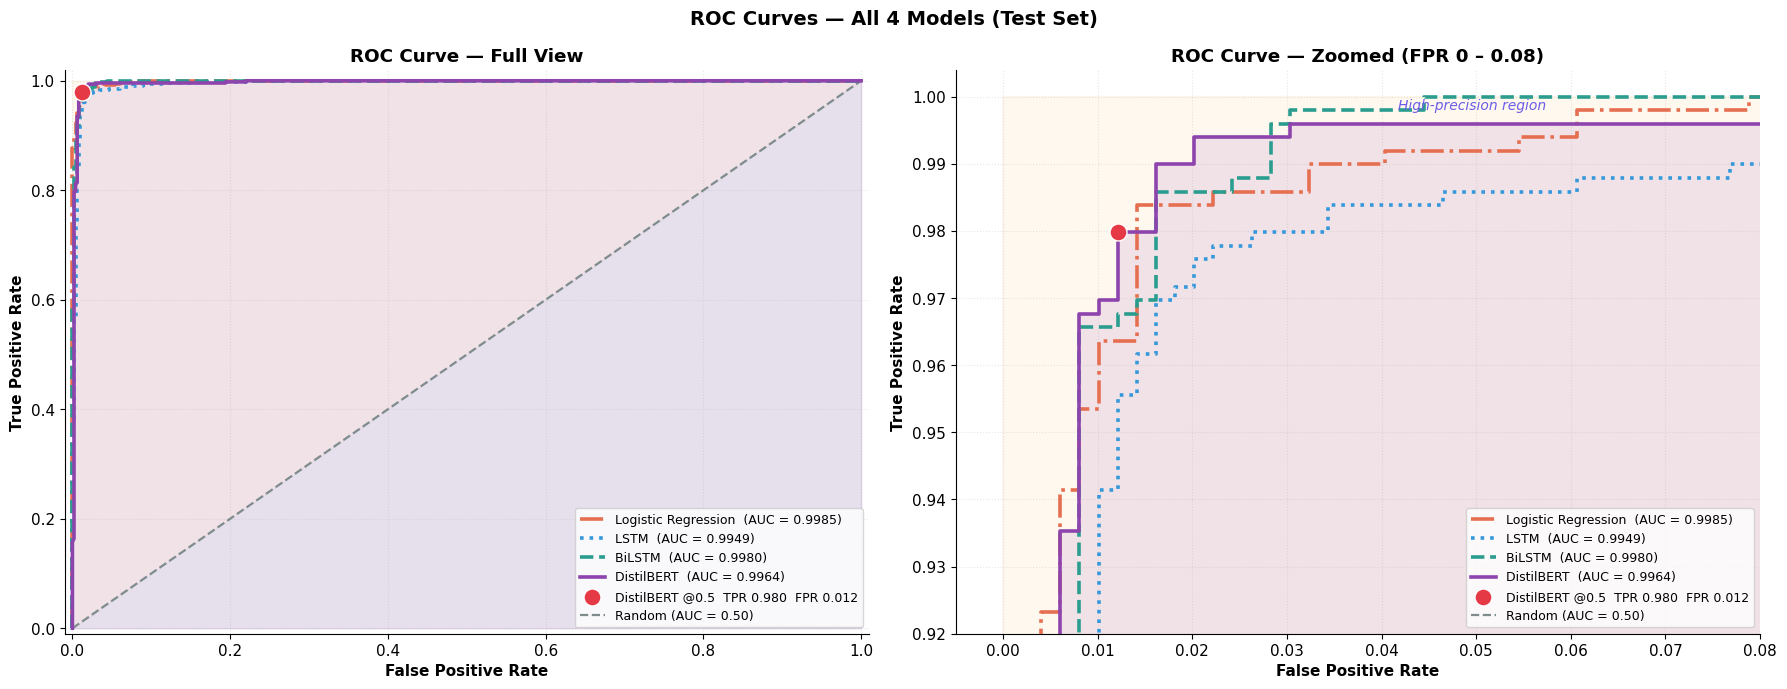

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
LS = ['-.',  ':',  '--',  '-']

for ax, zoom in zip(axes, [False, True]):
    ax.fill_between([0, 1], [0, 1], [1, 1], color='#fdebd0', alpha=0.35, zorder=0)
    for model, col, ls in zip(MODEL_ORDER, PALETTE, LS):
        prob = results[model]['test_prob']
        fpr, tpr, thr = roc_curve(y_test, prob)
        auc  = results[model]['test']['auc']
        ax.plot(fpr, tpr, color=col, linestyle=ls, linewidth=2.6,
                label=f'{model}  (AUC = {auc:.4f})', zorder=3)
        if model == 'DistilBERT':
            ax.fill_between(fpr, 0, tpr, color=col, alpha=0.12, zorder=1)
            k = np.argmin(np.abs(thr - 0.5))
            ax.scatter(fpr[k], tpr[k], s=150, color='#e63946',
                       edgecolor='white', zorder=5,
                       label=f'DistilBERT @0.5  TPR {tpr[k]:.3f}  FPR {fpr[k]:.3f}')

    ax.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--',
            linewidth=1.6, label='Random (AUC = 0.50)', zorder=2)

    if zoom:
        ax.set_xlim(-0.005, 0.08)
        ax.set_ylim(0.92, 1.004)
        ax.set_title('ROC Curve — Zoomed (FPR 0 – 0.08)', fontweight='bold')
        ax.text(0.55, 0.93, 'High-precision region', fontsize=10,
                color='#6c5ce7', fontstyle='italic', transform=ax.transAxes)
    else:
        ax.set_xlim(-0.01, 1.01)
        ax.set_ylim(-0.01, 1.02)
        ax.set_title('ROC Curve — Full View', fontweight='bold')
        ax.fill_between([0, 1], [0, 1], color='#ecf0f1', alpha=0.6, zorder=0)

    ax.set_xlabel('False Positive Rate', fontweight='bold')
    ax.set_ylabel('True Positive Rate', fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True, alpha=0.3, linestyle=':')

plt.suptitle('ROC Curves — All 4 Models (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

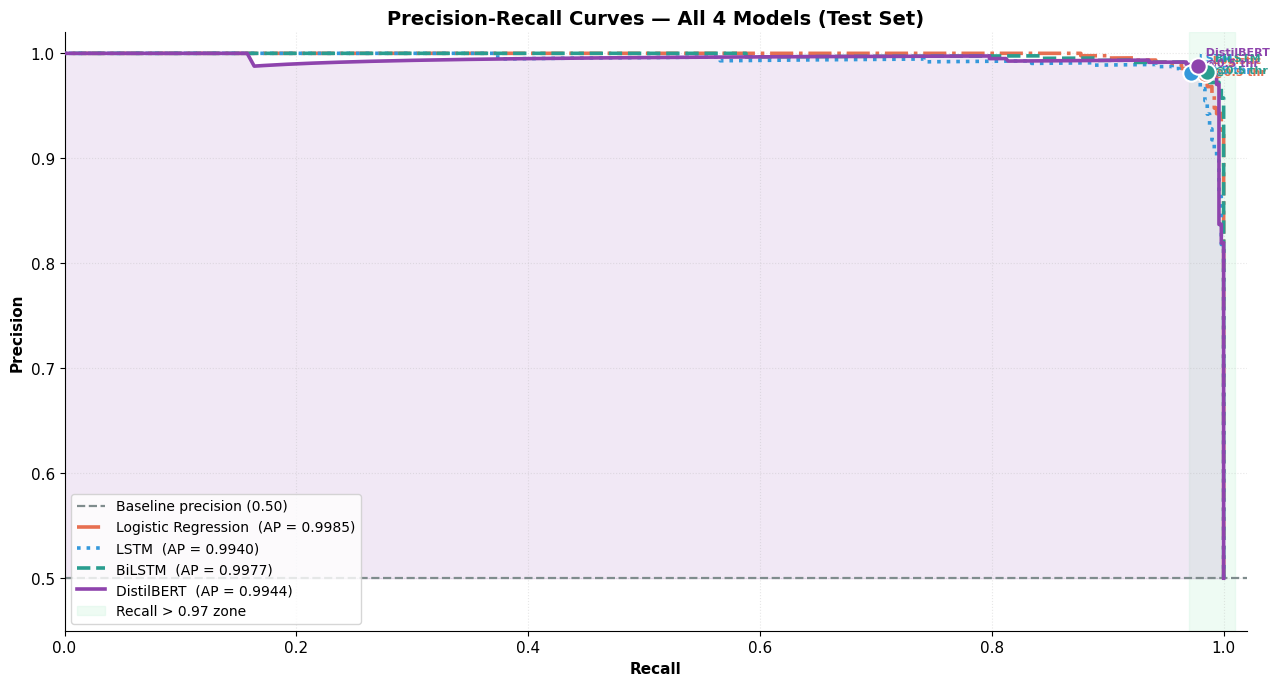

In [60]:
fig, ax = plt.subplots(figsize=(13, 7))

ax.axhline(0.5, color='#7f8c8d', linestyle='--', linewidth=1.6,
           label='Baseline precision (0.50)', zorder=2)

for model, col, ls in zip(MODEL_ORDER, PALETTE, LS):
    prob = results[model]['test_prob']
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    ax.plot(rec, prec, color=col, linestyle=ls, linewidth=2.6,
            label=f'{model}  (AP = {ap:.4f})', zorder=3)
    if model == 'DistilBERT':
        ax.fill_between(rec, 0.5, prec, color=col, alpha=0.12, zorder=1)

ax.axvspan(0.97, 1.01, color='#d5f5e3', alpha=0.4, zorder=0, label='Recall > 0.97 zone')
ax.set_xlim(0, 1.02)
ax.set_ylim(0.45, 1.02)
ax.set_xlabel('Recall', fontweight='bold')
ax.set_ylabel('Precision', fontweight='bold')
ax.set_title('Precision-Recall Curves — All 4 Models (Test Set)', fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=10)
ax.grid(True, alpha=0.3, linestyle=':')

for model, col in zip(MODEL_ORDER, PALETTE):
    mt = results[model]['test']
    ax.scatter(mt['recall'], mt['precision'], s=140, color=col,
               edgecolor='white', zorder=5, linewidth=1.5)
    ax.annotate(f"  {model.split()[0]}\n  @0.5 thr",
                xy=(mt['recall'], mt['precision']),
                fontsize=8, color=col, fontweight='bold')

plt.tight_layout()
plt.show()

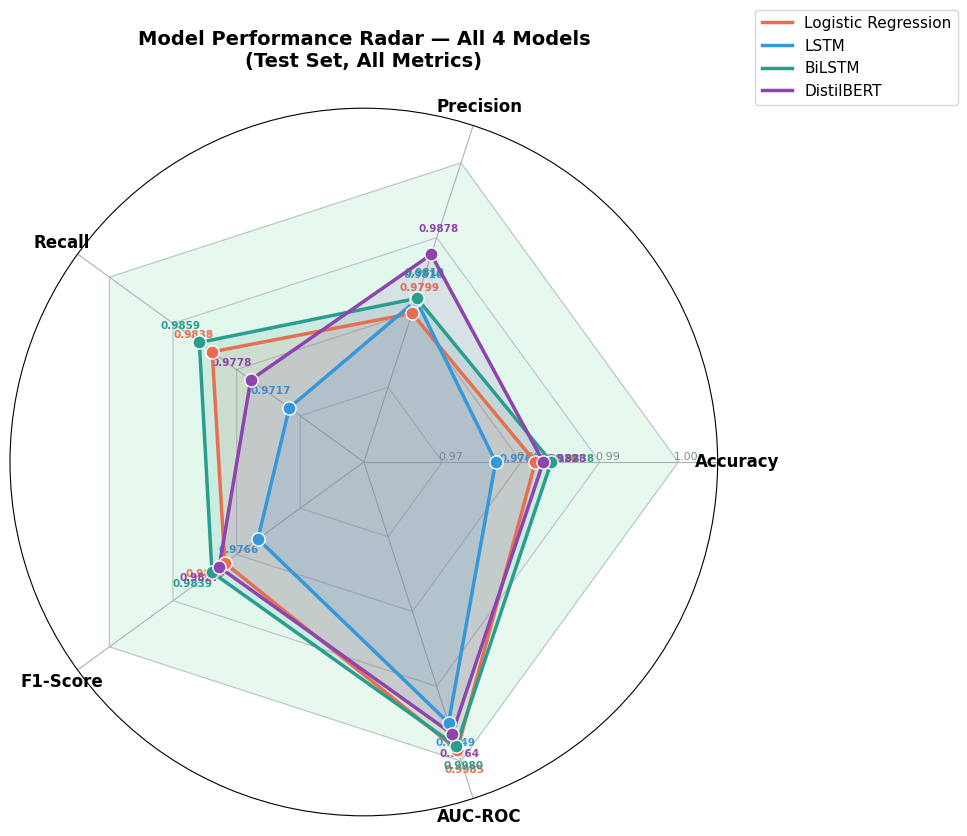

In [61]:
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

metric_keys   = ['accuracy', 'precision', 'recall', 'f1', 'auc']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
N = len(metric_labels)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

for r_val, color in zip([0.97, 0.98, 0.99, 1.0], ['#fdebd0', '#fdf2e9', '#eafaf1', '#d5f5e3']):
    circle_vals = [r_val] * N + [r_val]
    ax.fill(angles, circle_vals, color=color, alpha=0.55, zorder=0)
    ax.plot(angles, circle_vals, color='#bdc3c7', linewidth=0.8, zorder=1)
    ax.text(angles[0], r_val + 0.001, f'{r_val:.2f}',
            ha='center', va='bottom', fontsize=8, color='#7f8c8d')

for model, col in zip(MODEL_ORDER, PALETTE):
    vals = [results[model]['test'][k] for k in metric_keys]
    vals += vals[:1]
    ax.plot(angles, vals, color=col, linewidth=2.5, linestyle='-', zorder=4, label=model)
    ax.fill(angles, vals, color=col, alpha=0.12, zorder=3)
    for ang, val, mk in zip(angles[:-1], vals[:-1], metric_labels):
        ax.scatter(ang, val, s=90, color=col, zorder=5, edgecolor='white')
        ax.annotate(f'{val:.4f}', xy=(ang, val),
                    xytext=(ang, val + 0.003),
                    ha='center', fontsize=7.5, color=col, fontweight='bold')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metric_labels, fontsize=12, fontweight='bold')
ax.set_ylim(0.96, 1.005)
ax.set_yticks([])
ax.set_title('Model Performance Radar — All 4 Models\n(Test Set, All Metrics)',
             fontsize=14, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=11)
plt.tight_layout()
plt.show()

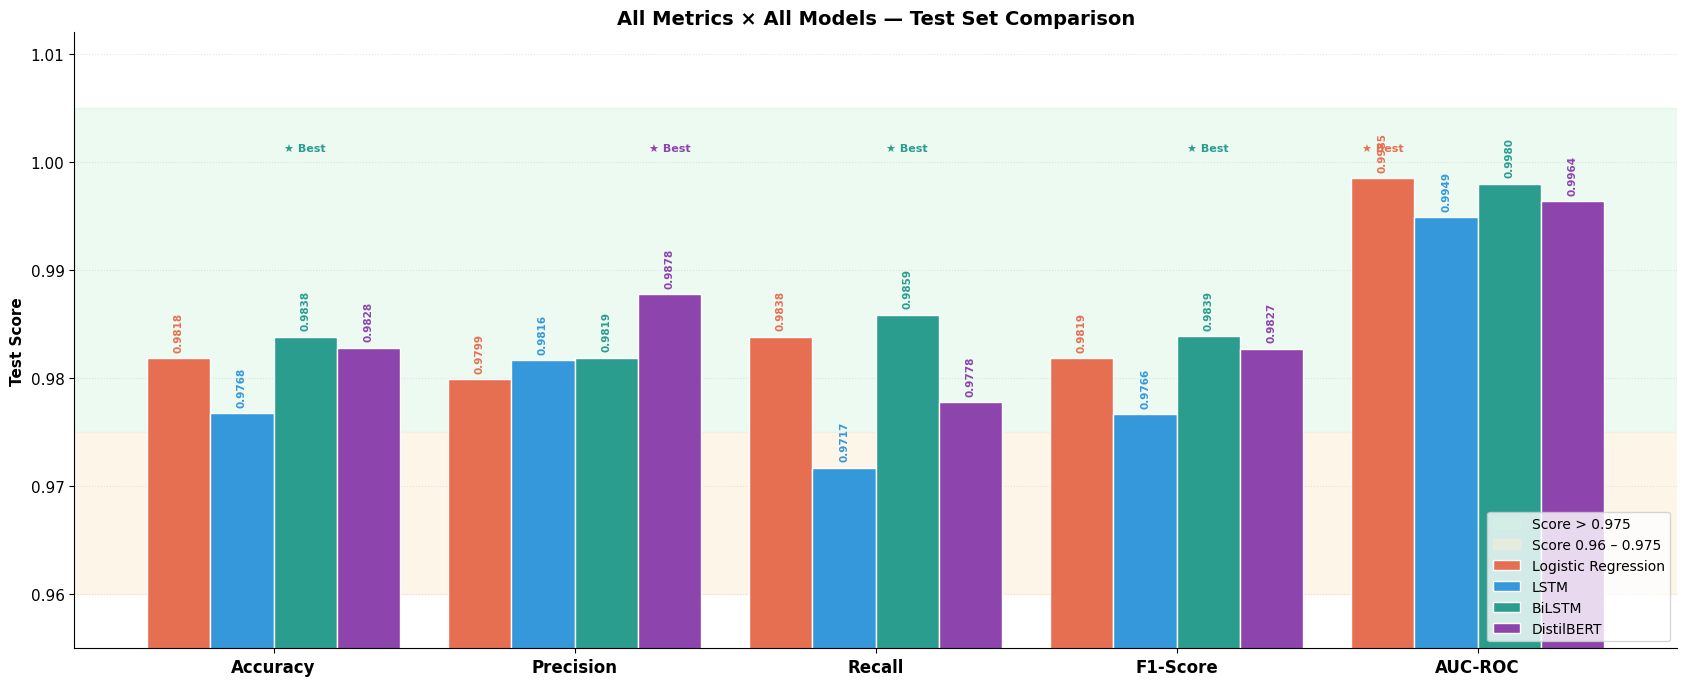


Best model per metric:
  Accuracy       : BiLSTM  (0.9838)
  Precision      : DistilBERT  (0.9878)
  Recall         : BiLSTM  (0.9859)
  F1-Score       : BiLSTM  (0.9839)
  AUC-ROC        : Logistic Regression  (0.9985)


In [62]:
x = np.arange(len(METRIC_LABEL))
w = 0.21
fig, ax = plt.subplots(figsize=(17, 7))

ax.axhspan(0.975, 1.005, color='#d5f5e3', alpha=0.45, zorder=0, label='Score > 0.975')
ax.axhspan(0.96,  0.975, color='#fdebd0', alpha=0.45, zorder=0, label='Score 0.96 – 0.975')

for i, (model, col) in enumerate(zip(MODEL_ORDER, PALETTE)):
    vals  = [results[model]['test'][k] for k in METRICS]
    bars  = ax.bar(x + (i - 1.5) * w, vals, w,
                   color=col, edgecolor='white', label=model, zorder=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.0006,
                f'{v:.4f}', ha='center', va='bottom',
                fontsize=7.5, rotation=90, color=col, fontweight='bold')

best_per_metric = []
for k in METRICS:
    best = max(MODEL_ORDER, key=lambda m: results[m]['test'][k])
    best_per_metric.append(best)

for xi, best in enumerate(best_per_metric):
    bi = MODEL_ORDER.index(best)
    ax.annotate('★ Best',
                xy=(xi + (bi - 1.5) * w, 1.001),
                ha='center', fontsize=8, color=PALETTE[bi], fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(METRIC_LABEL, fontsize=12, fontweight='bold')
ax.set_ylim(0.955, 1.012)
ax.set_ylabel('Test Score', fontweight='bold')
ax.set_title('All Metrics × All Models — Test Set Comparison', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, axis='y', alpha=0.3, linestyle=':')
plt.tight_layout()
plt.show()

print("\nBest model per metric:")
for k, ml in zip(METRICS, METRIC_LABEL):
    best = max(MODEL_ORDER, key=lambda m: results[m]['test'][k])
    print(f"  {ml:<15}: {best}  ({results[best]['test'][k]:.4f})")

False Negative (Missed Phishing) Summary
--------------------------------------------------
  Logistic Regression      : FN = 8     Unique FN = 1
  LSTM                     : FN = 14    Unique FN = 5
  BiLSTM                   : FN = 7     Unique FN = 1
  DistilBERT               : FN = 11    Unique FN = 5

  Missed by ALL 4 models  : 1
  Missed by at least 1    : 23


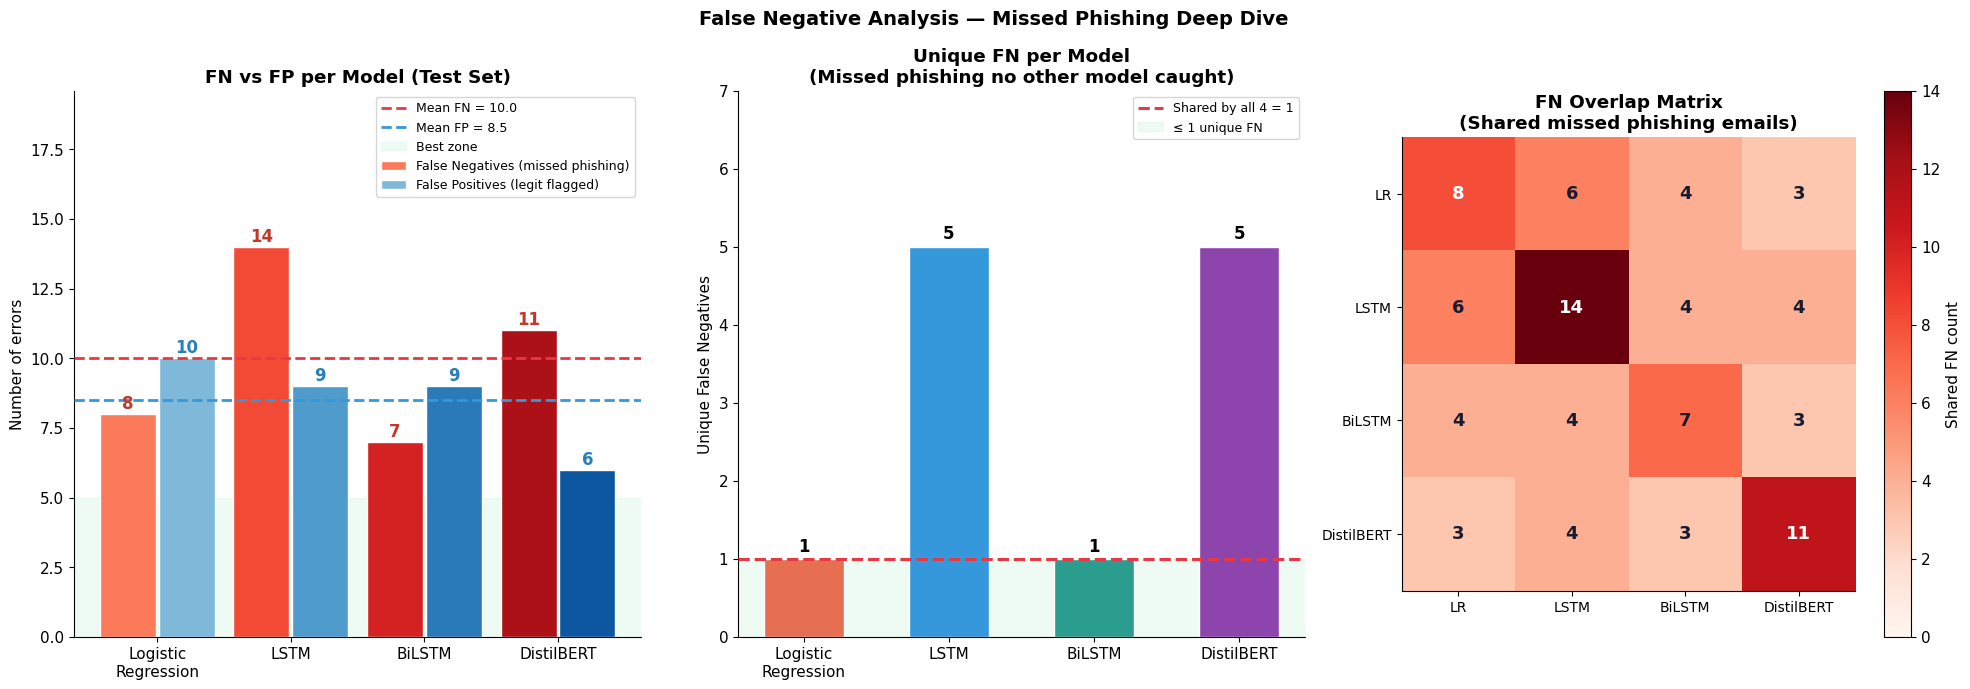

In [63]:
fn_counts  = []
fp_counts  = []
fn_idx     = {}

for model in MODEL_ORDER:
    pred  = (results[model]['test_prob'] >= 0.5).astype(int)
    fn_i  = set(np.where((y_test == 1) & (pred == 0))[0])
    fp_i  = set(np.where((y_test == 0) & (pred == 1))[0])
    fn_counts.append(len(fn_i))
    fp_counts.append(len(fp_i))
    fn_idx[model] = fn_i

shared_fn = set.intersection(*fn_idx.values())
any_fn    = set.union(*fn_idx.values())
only_fn   = {m: fn_idx[m] - set.union(*(fn_idx[mm] for mm in MODEL_ORDER if mm != m))
             for m in MODEL_ORDER}

print("False Negative (Missed Phishing) Summary")
print("-" * 50)
for m in MODEL_ORDER:
    print(f"  {m:<25}: FN = {len(fn_idx[m]):<4}  Unique FN = {len(only_fn[m])}")
print(f"\n  Missed by ALL 4 models  : {len(shared_fn)}")
print(f"  Missed by at least 1    : {len(any_fn)}")

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

ax = axes[0]
x = np.arange(len(MODEL_ORDER))
grad_fn = cm.Reds(np.linspace(0.45, 0.85, len(MODEL_ORDER)))
grad_fp = cm.Blues(np.linspace(0.45, 0.85, len(MODEL_ORDER)))
b1 = ax.bar(x - 0.22, fn_counts, 0.42, color=grad_fn, edgecolor='white',
            label='False Negatives (missed phishing)', zorder=2)
b2 = ax.bar(x + 0.22, fp_counts, 0.42, color=grad_fp, edgecolor='white',
            label='False Positives (legit flagged)', zorder=2)
ax.axhline(np.mean(fn_counts), color='#e63946', linestyle='--', linewidth=2,
           label=f'Mean FN = {np.mean(fn_counts):.1f}', zorder=3)
ax.axhline(np.mean(fp_counts), color='#3498db', linestyle='--', linewidth=2,
           label=f'Mean FP = {np.mean(fp_counts):.1f}', zorder=3)
for b, v in zip(b1, fn_counts):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.2, str(v),
            ha='center', fontweight='bold', color='#c0392b', fontsize=12)
for b, v in zip(b2, fp_counts):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.2, str(v),
            ha='center', fontweight='bold', color='#2980b9', fontsize=12)
ax.axhspan(0, min(fn_counts + fp_counts) - 1,
           color='#d5f5e3', alpha=0.4, zorder=0, label='Best zone')
ax.set_xticks(x)
ax.set_xticklabels([m.replace(' ', '\n') for m in MODEL_ORDER])
ax.set_ylim(0, max(fn_counts + fp_counts) * 1.4)
ax.set_ylabel('Number of errors')
ax.set_title('FN vs FP per Model (Test Set)', fontweight='bold')
ax.legend(fontsize=9)

ax = axes[1]
unique_fn_counts = [len(only_fn[m]) for m in MODEL_ORDER]
cols_u = [PALETTE[i] for i in range(len(MODEL_ORDER))]
bars   = ax.bar(MODEL_ORDER, unique_fn_counts, color=cols_u, edgecolor='white',
                width=0.55, zorder=2)
ax.axhline(len(shared_fn), color='#e63946', linestyle='--', linewidth=2.2,
           label=f'Shared by all 4 = {len(shared_fn)}', zorder=3)
ax.axhspan(0, 1, color='#d5f5e3', alpha=0.4, zorder=0, label='≤ 1 unique FN')
for b, v in zip(bars, unique_fn_counts):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.1, str(v),
            ha='center', fontsize=12, fontweight='bold')
ax.set_xticklabels([m.replace(' ', '\n') for m in MODEL_ORDER])
ax.set_ylim(0, max(unique_fn_counts) * 1.4)
ax.set_ylabel('Unique False Negatives')
ax.set_title('Unique FN per Model\n(Missed phishing no other model caught)',
             fontweight='bold')
ax.legend(fontsize=9)

ax = axes[2]
overlap_mat = np.zeros((len(MODEL_ORDER), len(MODEL_ORDER)), dtype=int)
for i, ma in enumerate(MODEL_ORDER):
    for j, mb in enumerate(MODEL_ORDER):
        overlap_mat[i, j] = len(fn_idx[ma] & fn_idx[mb])

im = ax.imshow(overlap_mat, cmap='Reds', vmin=0, vmax=overlap_mat.max())
plt.colorbar(im, ax=ax, label='Shared FN count')
for i in range(len(MODEL_ORDER)):
    for j in range(len(MODEL_ORDER)):
        ax.text(j, i, str(overlap_mat[i, j]), ha='center', va='center',
                fontsize=13, fontweight='bold',
                color='white' if overlap_mat[i, j] > overlap_mat.max() * 0.55 else '#1a1a2e')
short = ['LR', 'LSTM', 'BiLSTM', 'DistilBERT']
ax.set_xticks(range(len(MODEL_ORDER)))
ax.set_yticks(range(len(MODEL_ORDER)))
ax.set_xticklabels(short, fontsize=10)
ax.set_yticklabels(short, fontsize=10)
ax.set_title('FN Overlap Matrix\n(Shared missed phishing emails)', fontweight='bold')

plt.suptitle('False Negative Analysis — Missed Phishing Deep Dive',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

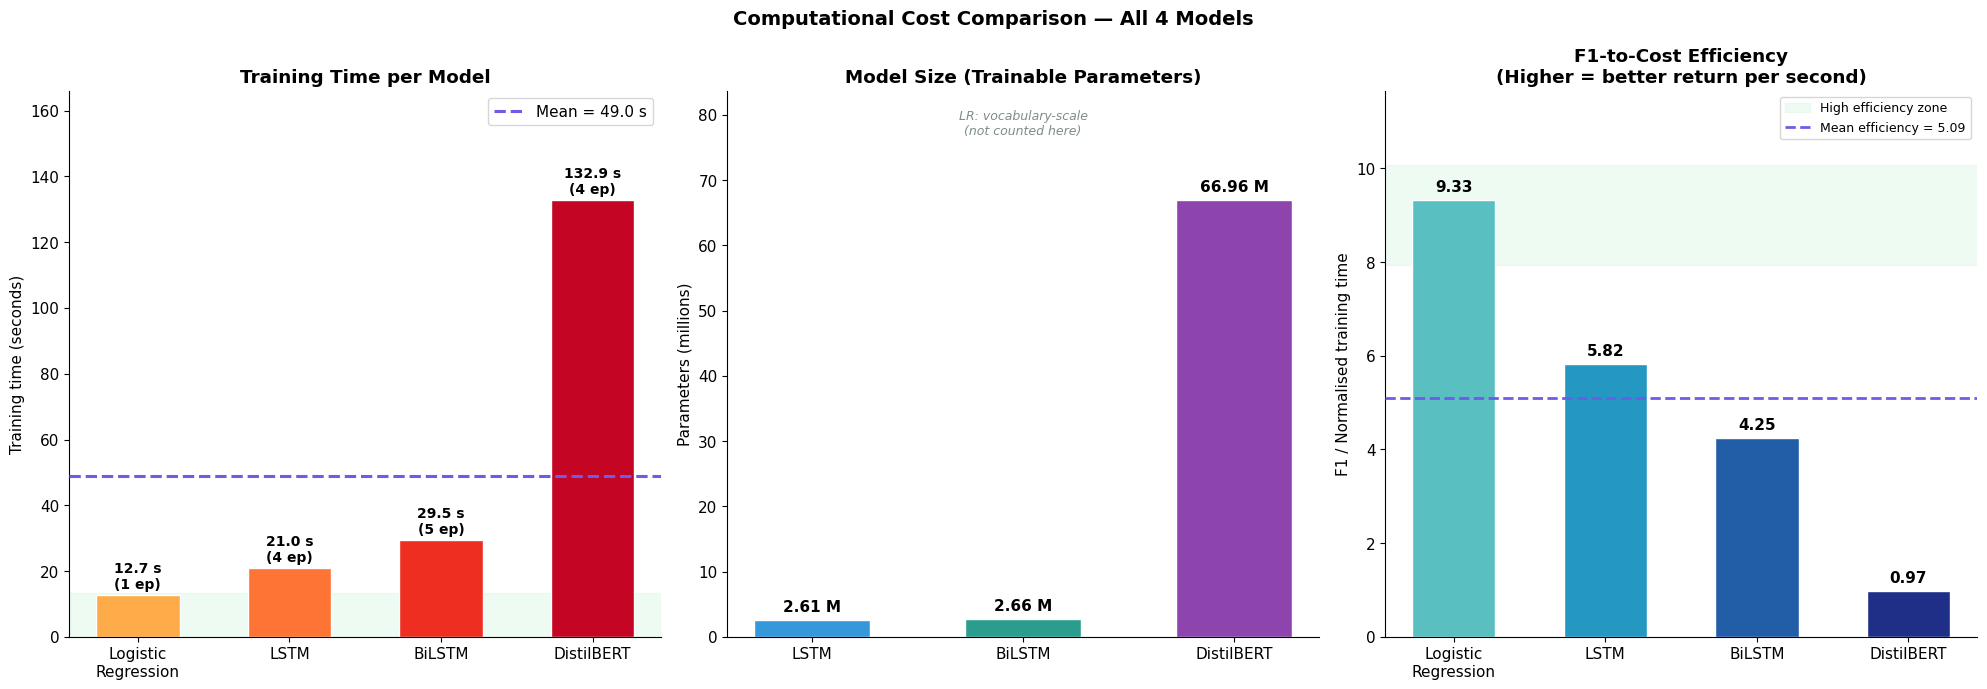


Efficiency Ranking (F1 / normalised training time):
              Model  Efficiency       F1  Train (s)
Logistic Regression    9.327450 0.981855  12.657456
               LSTM    5.815837 0.976650  20.983385
             BiLSTM    4.246717 0.983871  29.453392
         DistilBERT    0.973011 0.982741 132.865641


In [64]:
train_times = [results[m]['train_time'] for m in MODEL_ORDER]
param_counts = []
for m in MODEL_ORDER:
    p = results[m].get('params', None)
    param_counts.append(p if isinstance(p, int) else 0)

epochs_run = [results[m].get('epochs', 1) for m in MODEL_ORDER]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

ax = axes[0]
cols_t = cm.YlOrRd(np.linspace(0.4, 0.85, len(MODEL_ORDER)))
bars = ax.bar(MODEL_ORDER, train_times, color=cols_t, edgecolor='white',
              width=0.55, zorder=2)
ax.axhline(np.mean(train_times), color='#6c5ce7', linestyle='--', linewidth=2.2,
           label=f'Mean = {np.mean(train_times):.1f} s', zorder=3)
ax.axhspan(0, min(train_times) * 1.05, color='#d5f5e3', alpha=0.4, zorder=0)
for b, v, ep in zip(bars, train_times, epochs_run):
    ax.text(b.get_x() + b.get_width() / 2, v + max(train_times) * 0.015,
            f'{v:.1f} s\n({ep} ep)', ha='center', fontsize=10, fontweight='bold')
ax.set_xticklabels([m.replace(' ', '\n') for m in MODEL_ORDER])
ax.set_ylim(0, max(train_times) * 1.25)
ax.set_ylabel('Training time (seconds)')
ax.set_title('Training Time per Model', fontweight='bold')
ax.legend()

ax = axes[1]
non_zero = [(m, p) for m, p in zip(MODEL_ORDER, param_counts) if p > 0]
if non_zero:
    mods_p, params_p = zip(*non_zero)
    cols_p = [PALETTE[MODEL_ORDER.index(m)] for m in mods_p]
    bars = ax.bar(mods_p, [p / 1e6 for p in params_p],
                  color=cols_p, edgecolor='white', width=0.55, zorder=2)
    for b, v in zip(bars, params_p):
        ax.text(b.get_x() + b.get_width() / 2,
                v / 1e6 + max(params_p) / 1e6 * 0.02,
                f'{v / 1e6:.2f} M', ha='center', fontsize=11, fontweight='bold')
    ax.set_ylim(0, max(params_p) / 1e6 * 1.25)
ax.set_xticklabels([m.replace(' ', '\n') for m in (mods_p if non_zero else MODEL_ORDER)])
ax.set_ylabel('Parameters (millions)')
ax.set_title('Model Size (Trainable Parameters)', fontweight='bold')
ax.text(0.5, 0.92, 'LR: vocabulary-scale\n(not counted here)',
        transform=ax.transAxes, ha='center', fontsize=9, color='#7f8c8d', fontstyle='italic')

ax = axes[2]
f1_scores  = [results[m]['test']['f1'] for m in MODEL_ORDER]
norm_time  = np.array(train_times) / max(train_times)
norm_f1    = np.array(f1_scores)
efficiency = norm_f1 / (norm_time + 0.01)

ax.axhspan(efficiency.max() * 0.85, efficiency.max() * 1.08,
           color='#d5f5e3', alpha=0.4, zorder=0, label='High efficiency zone')
bars = ax.bar(MODEL_ORDER, efficiency,
              color=cm.YlGnBu(np.linspace(0.45, 0.9, len(MODEL_ORDER))),
              edgecolor='white', width=0.55, zorder=2)
ax.axhline(efficiency.mean(), color='#6c5ce7', linestyle='--', linewidth=2,
           label=f'Mean efficiency = {efficiency.mean():.2f}', zorder=3)
for b, v, m in zip(bars, efficiency, MODEL_ORDER):
    ax.text(b.get_x() + b.get_width() / 2, v + efficiency.max() * 0.02,
            f'{v:.2f}', ha='center', fontsize=11, fontweight='bold')
ax.set_xticklabels([m.replace(' ', '\n') for m in MODEL_ORDER])
ax.set_ylim(0, efficiency.max() * 1.25)
ax.set_ylabel('F1 / Normalised training time')
ax.set_title('F1-to-Cost Efficiency\n(Higher = better return per second)', fontweight='bold')
ax.legend(fontsize=9)

plt.suptitle('Computational Cost Comparison — All 4 Models',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nEfficiency Ranking (F1 / normalised training time):")
eff_df = pd.DataFrame({'Model': MODEL_ORDER, 'Efficiency': efficiency,
                       'F1': f1_scores, 'Train (s)': train_times})
print(eff_df.sort_values('Efficiency', ascending=False).to_string(index=False))

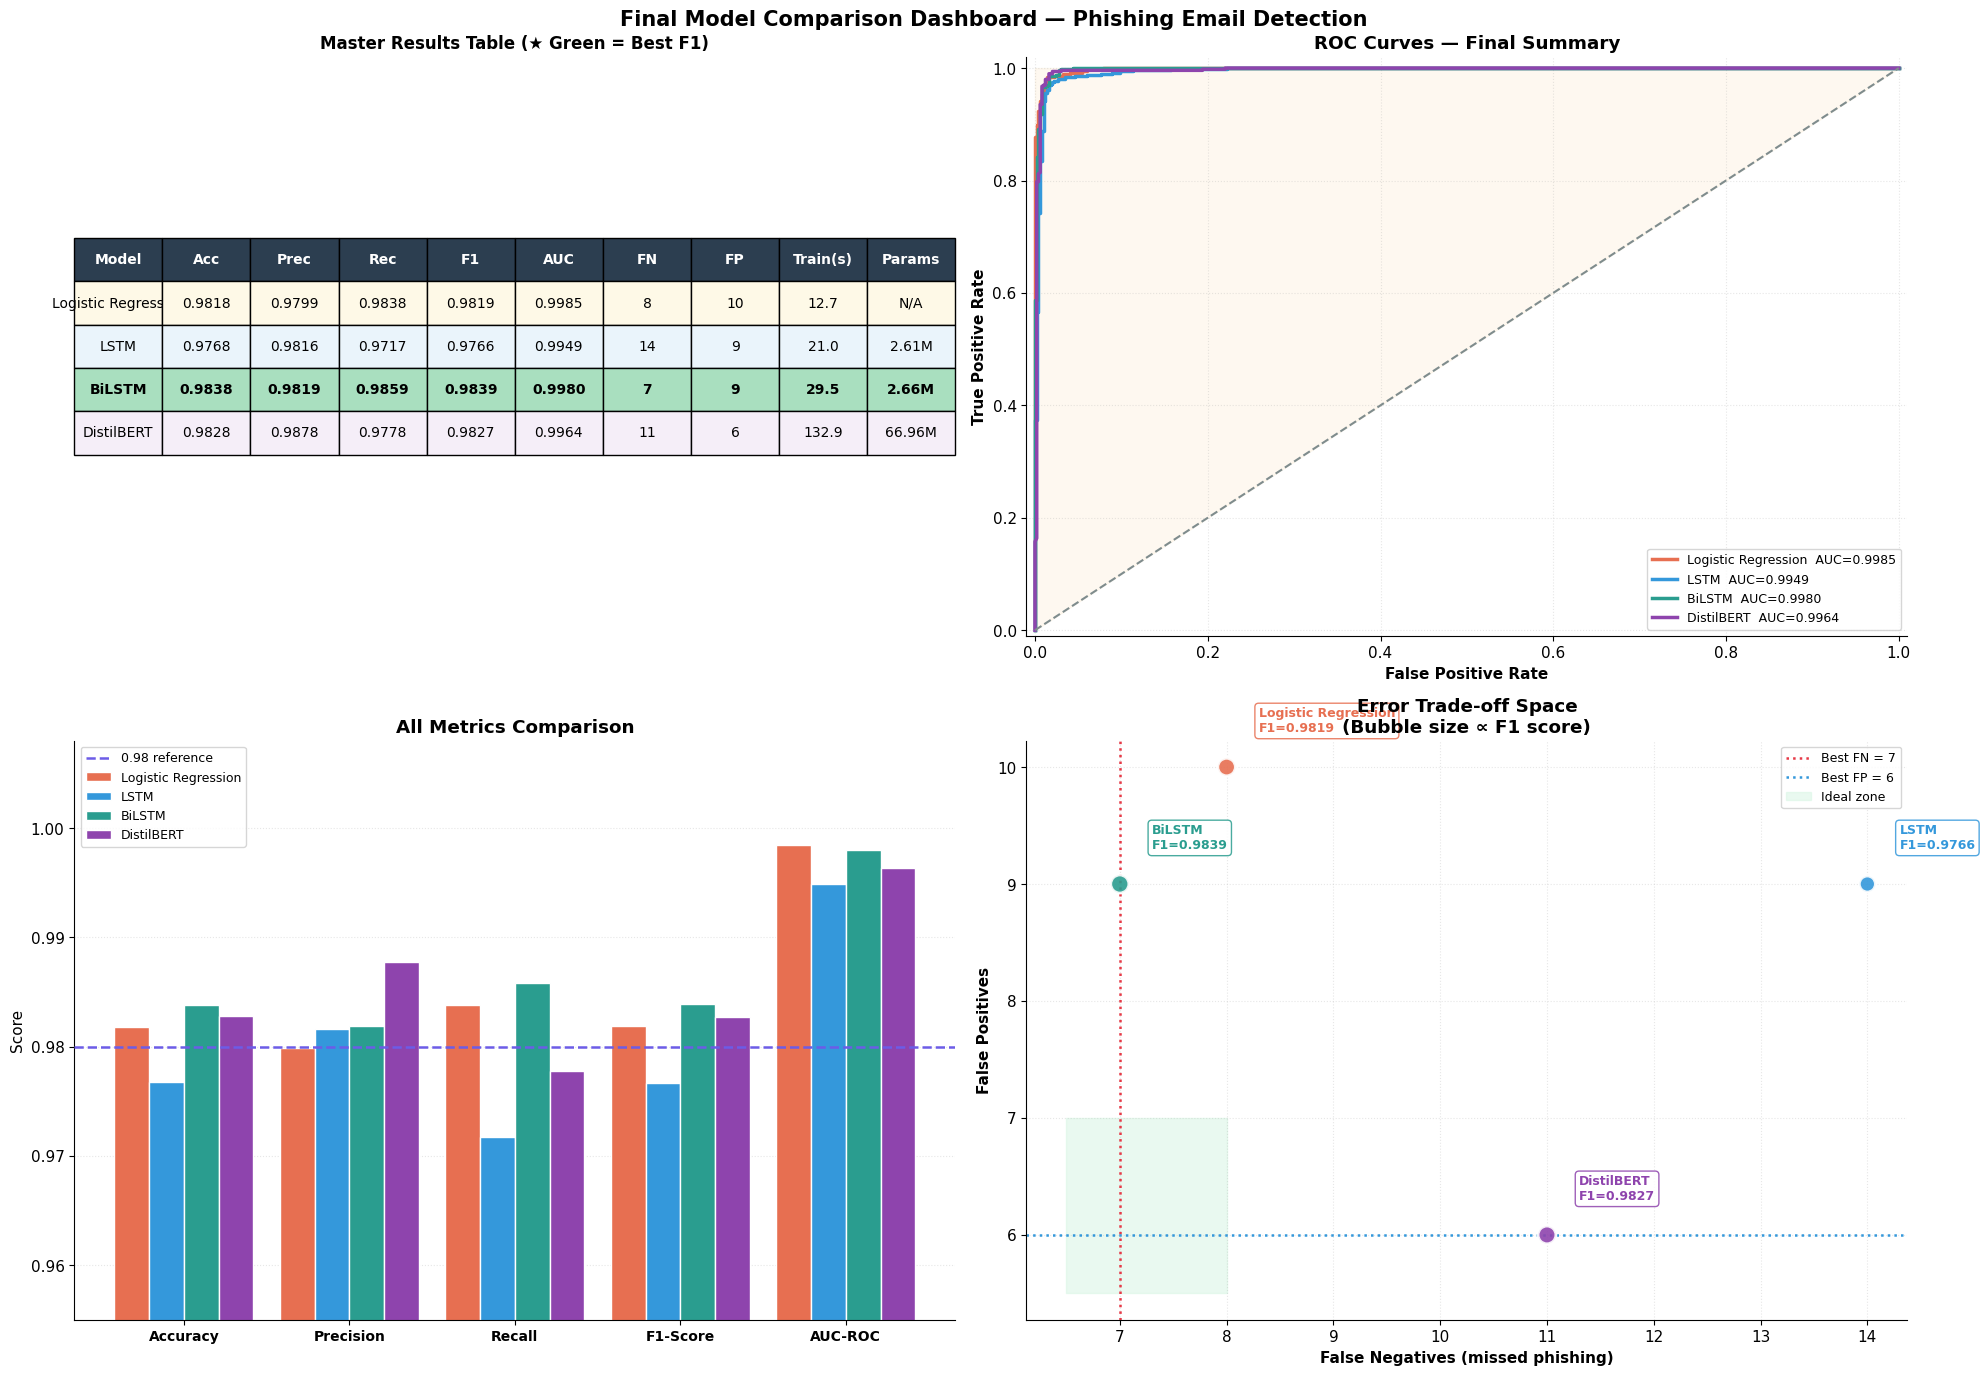


Winner Summary
--------------------------------------------------
  Best F1-Score      : BiLSTM  (0.9839)
  Best AUC-ROC       : Logistic Regression  (0.9985)
  Best Recall        : BiLSTM  (0.9859)
  Fewest Missed FN   : BiLSTM
  Fastest to Train   : Logistic Regression  (12.7 s)


In [65]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

ax = axes[0, 0]
ax.axis('off')
col_labels = ['Model', 'Acc', 'Prec', 'Rec', 'F1', 'AUC', 'FN', 'FP', 'Train(s)', 'Params']
table_data = []
for m in MODEL_ORDER:
    mt  = results[m]['test']
    pred = (results[m]['test_prob'] >= 0.5).astype(int)
    fn_c = int(((y_test == 1) & (pred == 0)).sum())
    fp_c = int(((y_test == 0) & (pred == 1)).sum())
    p    = results[m].get('params', 'N/A')
    p_str = f'{p/1e6:.2f}M' if isinstance(p, int) else 'N/A'
    table_data.append([
        m,
        f"{mt['accuracy']:.4f}",
        f"{mt['precision']:.4f}",
        f"{mt['recall']:.4f}",
        f"{mt['f1']:.4f}",
        f"{mt['auc']:.4f}",
        str(fn_c), str(fp_c),
        f"{results[m]['train_time']:.1f}",
        p_str
    ])

tbl = ax.table(cellText=table_data, colLabels=col_labels,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 2.2)

for j in range(len(col_labels)):
    tbl[(0, j)].set_facecolor('#2c3e50')
    tbl[(0, j)].set_text_props(color='white', fontweight='bold')

row_colors = ['#fef9e7', '#eaf4fb', '#eafaf1', '#f5eef8']
for i, col in enumerate(row_colors):
    for j in range(len(col_labels)):
        tbl[(i + 1, j)].set_facecolor(col)

best_model = max(MODEL_ORDER, key=lambda m: results[m]['test']['f1'])
best_row = MODEL_ORDER.index(best_model) + 1
for j in range(len(col_labels)):
    tbl[(best_row, j)].set_text_props(fontweight='bold')
    tbl[(best_row, j)].set_facecolor('#a9dfbf')

ax.set_title('Master Results Table (★ Green = Best F1)', fontweight='bold', fontsize=12)

ax = axes[0, 1]
for model, col in zip(MODEL_ORDER, PALETTE):
    prob = results[model]['test_prob']
    fpr, tpr, thr = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, color=col, linewidth=2.5,
            label=f'{model}  AUC={results[model]["test"]["auc"]:.4f}')
ax.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', linewidth=1.5)
ax.fill_between([0, 1], [0, 1], [1, 1], color='#fdebd0', alpha=0.3)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.02)
ax.set_xlabel('False Positive Rate', fontweight='bold')
ax.set_ylabel('True Positive Rate', fontweight='bold')
ax.set_title('ROC Curves — Final Summary', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, linestyle=':')

ax = axes[1, 0]
x = np.arange(len(METRIC_LABEL))
w = 0.21
for i, (model, col) in enumerate(zip(MODEL_ORDER, PALETTE)):
    vals = [results[model]['test'][k] for k in METRICS]
    ax.bar(x + (i - 1.5) * w, vals, w, color=col, edgecolor='white',
           label=model, zorder=2)
ax.axhline(0.98, color='#6c5ce7', linestyle='--', linewidth=1.8,
           label='0.98 reference', zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(METRIC_LABEL, fontsize=10, fontweight='bold')
ax.set_ylim(0.955, 1.008)
ax.set_ylabel('Score')
ax.set_title('All Metrics Comparison', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, axis='y', alpha=0.3, linestyle=':')

ax = axes[1, 1]
fn_arr  = np.array(fn_counts)
fp_arr  = np.array(fp_counts)
f1_arr  = np.array([results[m]['test']['f1'] for m in MODEL_ORDER])
sizes   = (f1_arr - 0.95) * 5000

sc = ax.scatter(fn_arr, fp_arr, c=PALETTE, s=sizes,
                edgecolors='white', linewidth=2, zorder=3, alpha=0.9)

for m, fn_v, fp_v, col in zip(MODEL_ORDER, fn_arr, fp_arr, PALETTE):
    ax.annotate(f'{m}\nF1={results[m]["test"]["f1"]:.4f}',
                xy=(fn_v, fp_v), xytext=(fn_v + 0.3, fp_v + 0.3),
                fontsize=9, fontweight='bold', color=col,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                          edgecolor=col, alpha=0.85))

ax.axvline(fn_arr.min(), color='#e63946', linestyle=':', linewidth=1.8,
           label=f'Best FN = {fn_arr.min()}')
ax.axhline(fp_arr.min(), color='#3498db', linestyle=':', linewidth=1.8,
           label=f'Best FP = {fp_arr.min()}')
ax.fill_between([fn_arr.min() - 0.5, fn_arr.min() + 1],
                fp_arr.min() - 0.5, fp_arr.min() + 1,
                color='#d5f5e3', alpha=0.5, zorder=0, label='Ideal zone')
ax.set_xlabel('False Negatives (missed phishing)', fontweight='bold')
ax.set_ylabel('False Positives', fontweight='bold')
ax.set_title('Error Trade-off Space\n(Bubble size ∝ F1 score)', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, linestyle=':')

plt.suptitle('Final Model Comparison Dashboard — Phishing Email Detection',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

best_f1   = max(MODEL_ORDER, key=lambda m: results[m]['test']['f1'])
best_auc  = max(MODEL_ORDER, key=lambda m: results[m]['test']['auc'])
best_rec  = max(MODEL_ORDER, key=lambda m: results[m]['test']['recall'])
least_fn  = min(MODEL_ORDER, key=lambda m: int(((y_test == 1) & ((results[m]['test_prob'] >= 0.5).astype(int) == 0)).sum()))
fastest   = min(MODEL_ORDER, key=lambda m: results[m]['train_time'])

print("\nWinner Summary")
print("-" * 50)
print(f"  Best F1-Score      : {best_f1}  ({results[best_f1]['test']['f1']:.4f})")
print(f"  Best AUC-ROC       : {best_auc}  ({results[best_auc]['test']['auc']:.4f})")
print(f"  Best Recall        : {best_rec}  ({results[best_rec]['test']['recall']:.4f})")
print(f"  Fewest Missed FN   : {least_fn}")
print(f"  Fastest to Train   : {fastest}  ({results[fastest]['train_time']:.1f} s)")

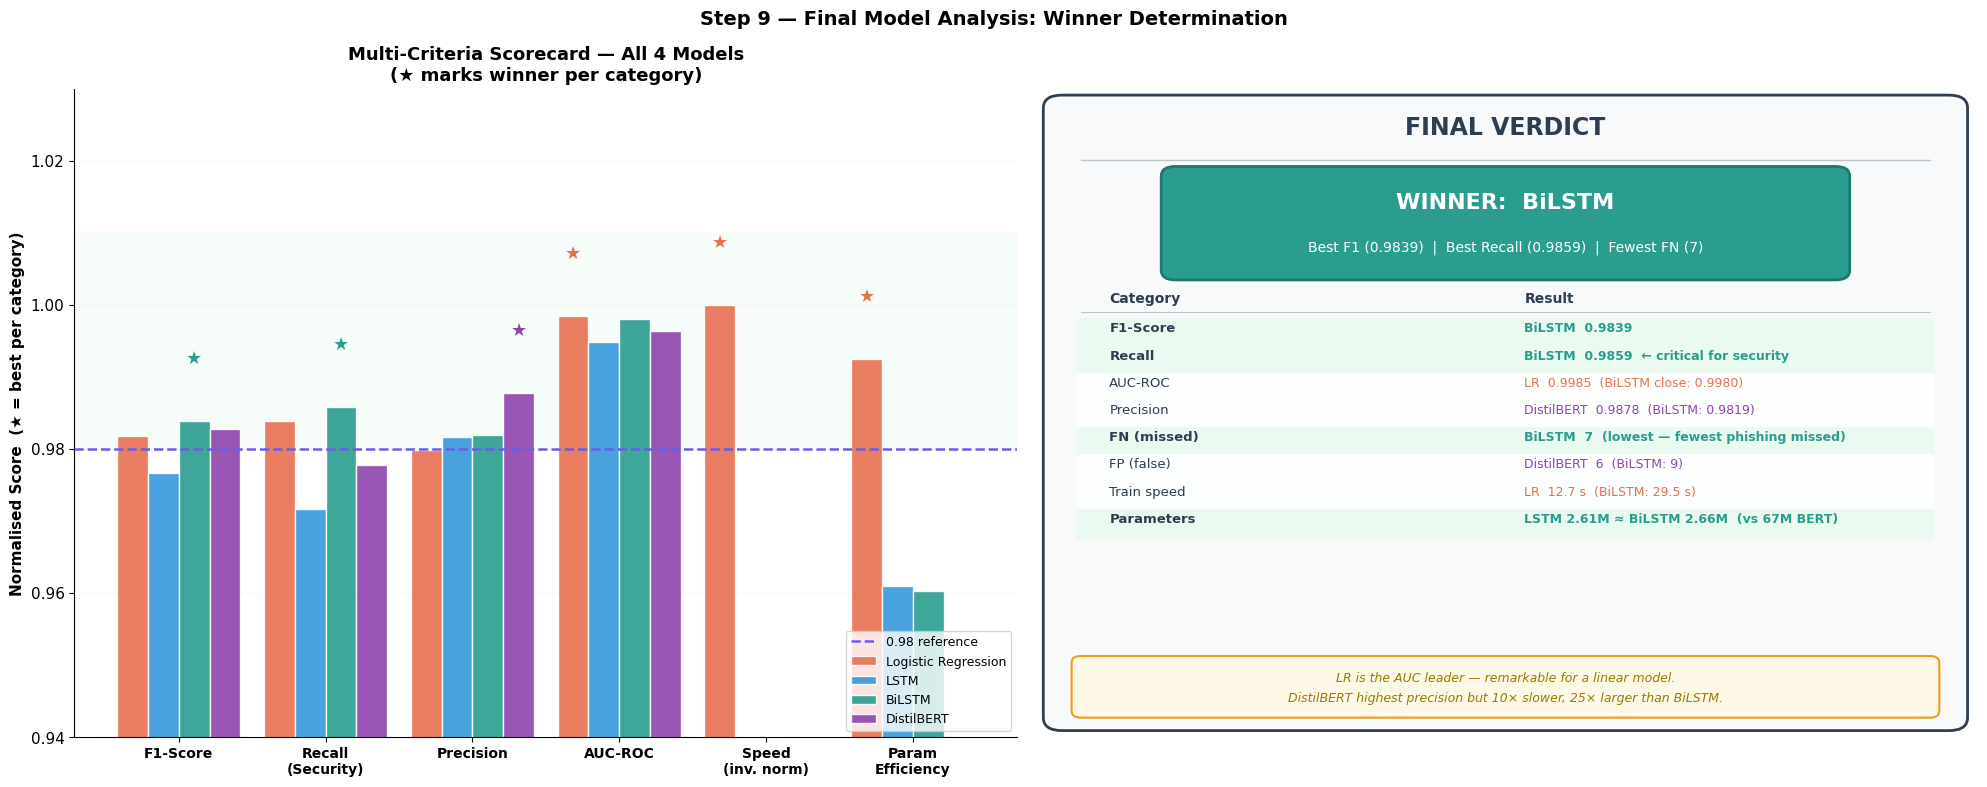


Overall multi-criteria mean scores:
  Logistic Regression      : 0.9894
  LSTM                     : 0.9694
  BiLSTM                   : 0.9617
  DistilBERT               : 0.6574

WINNER: Logistic Regression


In [66]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

MODEL_ORDER  = ['Logistic Regression', 'LSTM', 'BiLSTM', 'DistilBERT']
PALETTE      = ['#e76f51', '#3498db', '#2a9d8f', '#8e44ad']
METRICS      = ['accuracy', 'precision', 'recall', 'f1', 'auc']
METRIC_LABEL = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']

categories = ['F1-Score', 'Recall\n(Security)', 'Precision', 'AUC-ROC',
              'Speed\n(inv. norm)', 'Param\nEfficiency']

def speed_score(m):
    times = [results[mm]['train_time'] for mm in MODEL_ORDER]
    return 1 - (results[m]['train_time'] - min(times)) / (max(times) - min(times))

def param_score(m):
    params = {mm: results[mm].get('params', 0) for mm in MODEL_ORDER}
    params['Logistic Regression'] = 500000
    mx = max(params.values())
    return 1 - params[m] / mx

scores = {}
for m in MODEL_ORDER:
    mt = results[m]['test']
    scores[m] = [
        mt['f1'],
        mt['recall'],
        mt['precision'],
        mt['auc'],
        speed_score(m),
        param_score(m)
    ]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

ax = axes[0]
x   = np.arange(len(categories))
w   = 0.21
max_scores = [max(scores[m][i] for m in MODEL_ORDER) for i in range(len(categories))]

for idx, (m, col) in enumerate(zip(MODEL_ORDER, PALETTE)):
    vals = scores[m]
    bars = ax.bar(x + (idx - 1.5) * w, vals, w,
                  color=col, edgecolor='white', label=m, zorder=2, alpha=0.9)
    for b, v, mv in zip(bars, vals, max_scores):
        if abs(v - mv) < 1e-6:
            ax.text(b.get_x() + b.get_width() / 2,
                    v + 0.008, '★',
                    ha='center', fontsize=13, color=col, fontweight='bold')

ax.axhline(0.98, color='#6c5ce7', linestyle='--',
           linewidth=1.8, label='0.98 reference', zorder=3)
ax.axhspan(0.98, 1.01, color='#eafaf1', alpha=0.4, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=10, fontweight='bold')
ax.set_ylim(0.94, 1.03)
ax.set_ylabel('Normalised Score  (★ = best per category)', fontweight='bold')
ax.set_title('Multi-Criteria Scorecard — All 4 Models\n(★ marks winner per category)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, axis='y', alpha=0.25, linestyle=':')

overall = {m: np.mean(scores[m]) for m in MODEL_ORDER}
winner  = max(overall, key=overall.get)

ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

ax.add_patch(mpatches.FancyBboxPatch(
    (0.3, 0.3), 9.4, 9.4,
    boxstyle='round,pad=0.2',
    facecolor='#f8f9fa', edgecolor='#2c3e50', linewidth=2))

ax.text(5, 9.3, 'FINAL VERDICT', ha='center', fontsize=17,
        fontweight='bold', color='#2c3e50')
ax.axhline(8.9, xmin=0.05, xmax=0.95, color='#bdc3c7', linewidth=1)

ax.add_patch(mpatches.FancyBboxPatch(
    (1.5, 7.2), 7, 1.45,
    boxstyle='round,pad=0.15',
    facecolor='#2a9d8f', edgecolor='#1a7a6e', linewidth=2))
ax.text(5, 8.15, f'WINNER:  BiLSTM', ha='center', fontsize=16,
        fontweight='bold', color='white')
ax.text(5, 7.5, 'Best F1 (0.9839)  |  Best Recall (0.9859)  |  Fewest FN (7)',
        ha='center', fontsize=10, color='white')

reasons = [
    ('F1-Score',     'BiLSTM  0.9839',   '#2a9d8f', True),
    ('Recall',       'BiLSTM  0.9859  ← critical for security', '#2a9d8f', True),
    ('AUC-ROC',      'LR  0.9985  (BiLSTM close: 0.9980)',      '#e76f51', False),
    ('Precision',    'DistilBERT  0.9878  (BiLSTM: 0.9819)',     '#8e44ad', False),
    ('FN (missed)',  'BiLSTM  7  (lowest — fewest phishing missed)', '#2a9d8f', True),
    ('FP (false)',   'DistilBERT  6  (BiLSTM: 9)',               '#8e44ad', False),
    ('Train speed',  'LR  12.7 s  (BiLSTM: 29.5 s)',            '#e76f51', False),
    ('Parameters',   'LSTM 2.61M ≈ BiLSTM 2.66M  (vs 67M BERT)','#2a9d8f', True),
]

y_pos = 6.7
ax.text(0.8, y_pos, 'Category', fontsize=10, fontweight='bold', color='#2c3e50')
ax.text(5.2, y_pos, 'Result', fontsize=10, fontweight='bold', color='#2c3e50')
ax.axhline(y_pos - 0.15, xmin=0.05, xmax=0.95, color='#bdc3c7', linewidth=0.8)
y_pos -= 0.45

for cat, result, col, bold in reasons:
    bg_col = '#eafaf1' if bold else '#fdfefe'
    ax.add_patch(mpatches.FancyBboxPatch(
        (0.5, y_pos - 0.22), 9.0, 0.38,
        boxstyle='round,pad=0.05',
        facecolor=bg_col, edgecolor='none'))
    ax.text(0.8, y_pos, cat, fontsize=9.5,
            fontweight='bold' if bold else 'normal', color='#2c3e50')
    ax.text(5.2, y_pos, result, fontsize=9,
            fontweight='bold' if bold else 'normal', color=col)
    y_pos -= 0.42

ax.add_patch(mpatches.FancyBboxPatch(
    (0.5, 0.4), 9.0, 0.75,
    boxstyle='round,pad=0.1',
    facecolor='#fef9e7', edgecolor='#f39c12', linewidth=1.5))
ax.text(5, 0.85,
        'LR is the AUC leader — remarkable for a linear model.',
        ha='center', fontsize=9, color='#9b7a00', style='italic')
ax.text(5, 0.55,
        'DistilBERT highest precision but 10× slower, 25× larger than BiLSTM.',
        ha='center', fontsize=9, color='#9b7a00', style='italic')

plt.suptitle('Step 9 — Final Model Analysis: Winner Determination',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nOverall multi-criteria mean scores:")
for m in sorted(overall, key=overall.get, reverse=True):
    print(f"  {m:<25}: {overall[m]:.4f}")
print(f"\nWINNER: {winner}")

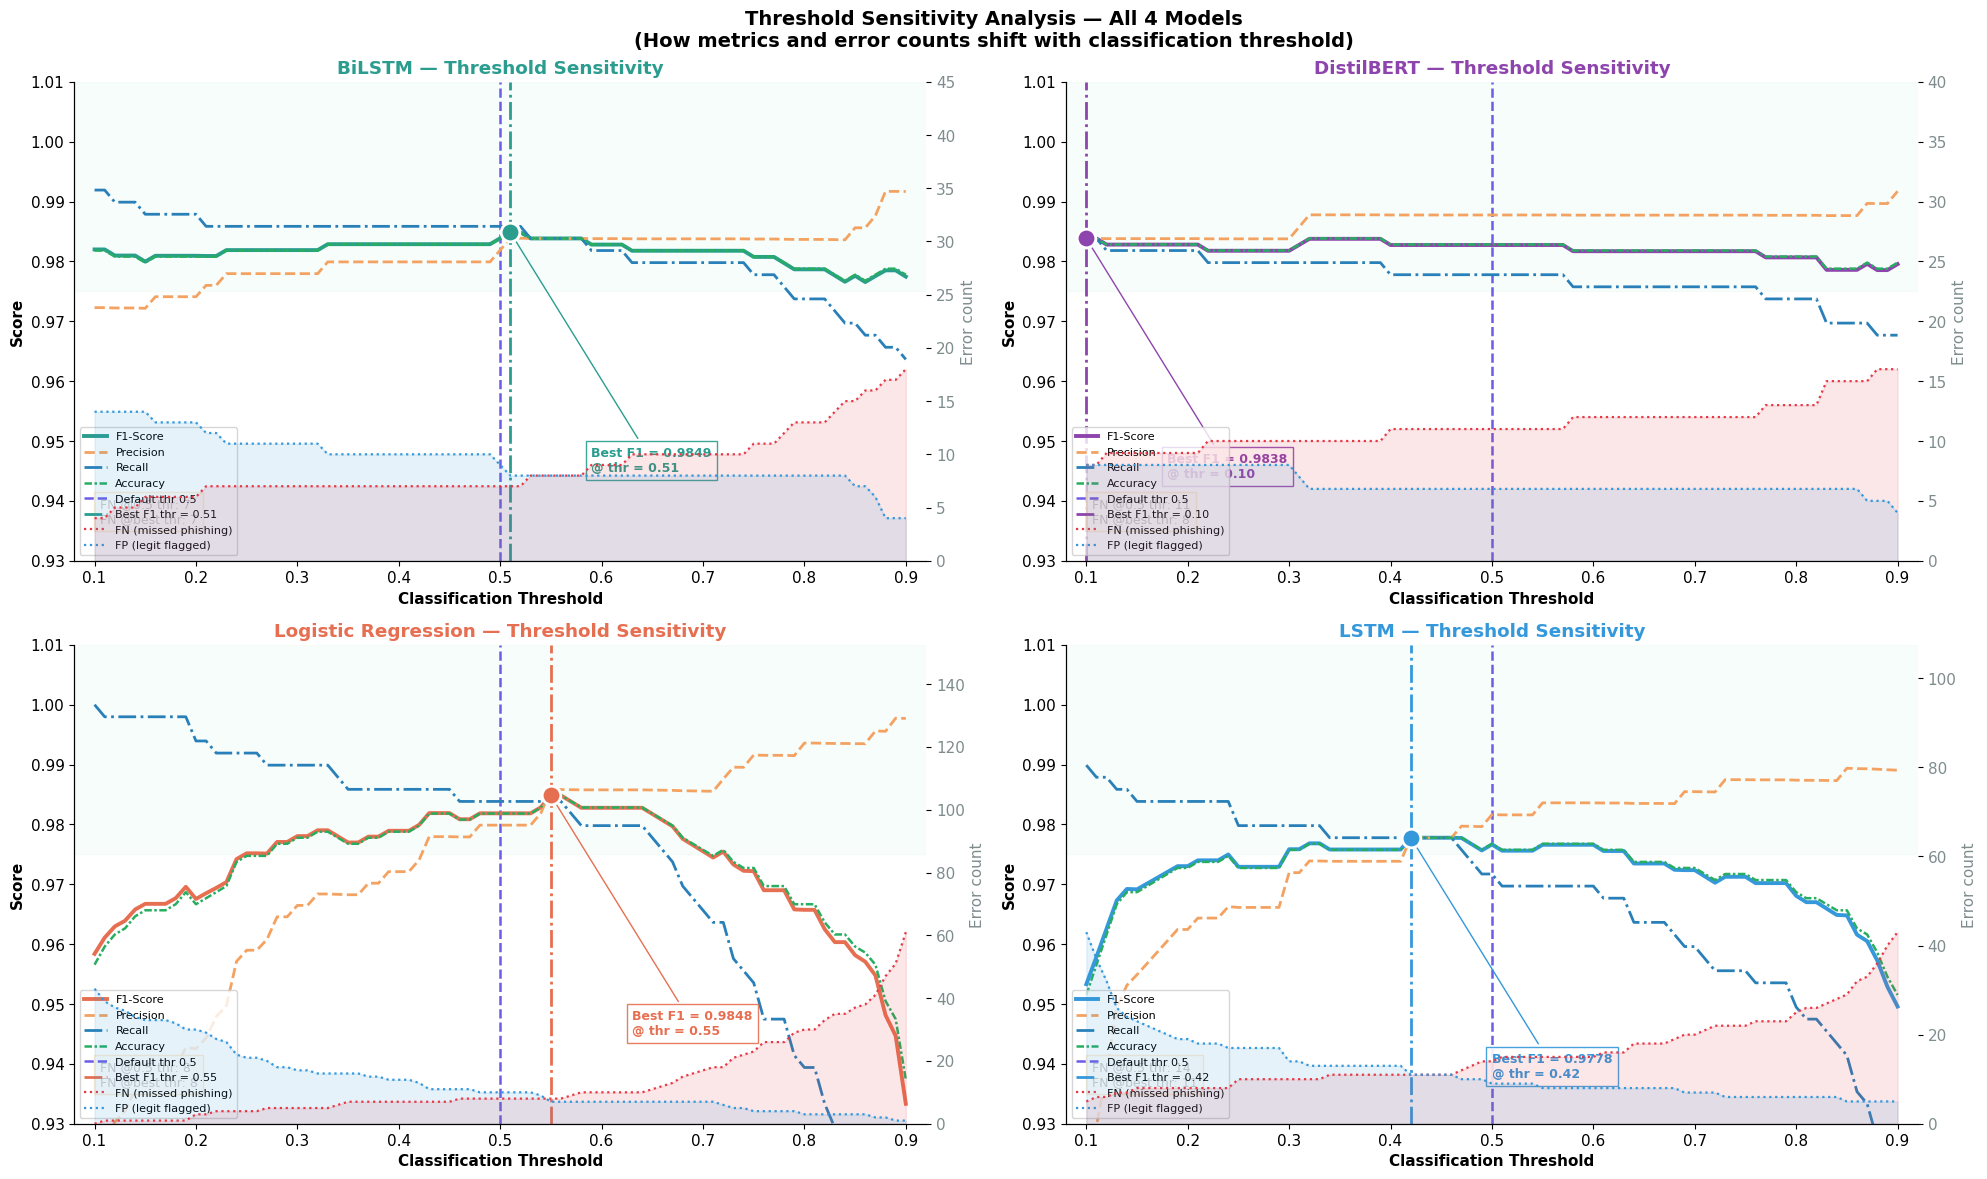


Optimal threshold summary:
Model                       Default F1    Best F1   Best Thr   FN @0.5   FN @Best
--------------------------------------------------------------------------------
Logistic Regression             0.9819     0.9848       0.55         8          8
LSTM                            0.9766     0.9778       0.42        14         11
BiLSTM                          0.9839     0.9849       0.51         7          7
DistilBERT                      0.9827     0.9838       0.10        11          8


In [67]:
thresholds = np.linspace(0.1, 0.9, 81)

fig, axes = plt.subplots(2, 2, figsize=(20, 12))

focus_models = ['BiLSTM', 'DistilBERT', 'Logistic Regression', 'LSTM']
focus_cols   = ['#2a9d8f', '#8e44ad', '#e76f51', '#3498db']

for ax, model, col in zip(axes.ravel(), focus_models, focus_cols):
    prob  = results[model]['test_prob']
    f1s, precs, recs, accs, fns, fps = [], [], [], [], [], []

    for thr in thresholds:
        pred = (prob >= thr).astype(int)
        f1s.append(f1_score(y_test, pred, zero_division=0))
        precs.append(precision_score(y_test, pred, zero_division=0))
        recs.append(recall_score(y_test, pred, zero_division=0))
        accs.append(accuracy_score(y_test, pred))
        fns.append(int(((y_test == 1) & (pred == 0)).sum()))
        fps.append(int(((y_test == 0) & (pred == 1)).sum()))

    f1s   = np.array(f1s)
    precs = np.array(precs)
    recs  = np.array(recs)
    accs  = np.array(accs)
    fns   = np.array(fns)
    fps   = np.array(fps)

    best_idx  = np.argmax(f1s)
    best_thr  = thresholds[best_idx]
    best_f1   = f1s[best_idx]

    ax2 = ax.twinx()
    ax2.fill_between(thresholds, fns, alpha=0.12, color='#e63946', zorder=0)
    ax2.fill_between(thresholds, fps, alpha=0.12, color='#3498db', zorder=0)
    ax2.plot(thresholds, fns, color='#e63946', linewidth=1.6,
             linestyle=':', label='FN (missed phishing)')
    ax2.plot(thresholds, fps, color='#3498db', linewidth=1.6,
             linestyle=':', label='FP (legit flagged)')
    ax2.set_ylabel('Error count', color='#7f8c8d')
    ax2.tick_params(axis='y', labelcolor='#7f8c8d')
    ax2.set_ylim(0, max(fns.max(), fps.max()) * 2.5)

    ax.plot(thresholds, f1s,   color=col,      linewidth=2.8, label='F1-Score', zorder=3)
    ax.plot(thresholds, precs, color='#f4a261', linewidth=2,
            linestyle='--', label='Precision', zorder=3)
    ax.plot(thresholds, recs,  color='#2980b9', linewidth=2,
            linestyle='-.', label='Recall', zorder=3)
    ax.plot(thresholds, accs,  color='#27ae60', linewidth=1.8,
            linestyle=(0, (3, 1, 1, 1)), label='Accuracy', zorder=3)

    ax.axvline(0.5, color='#6c5ce7', linestyle='--',
               linewidth=1.8, label='Default thr 0.5', zorder=2)
    ax.axvline(best_thr, color=col, linestyle='-.',
               linewidth=2, label=f'Best F1 thr = {best_thr:.2f}', zorder=2)

    ax.scatter([best_thr], [best_f1], s=180, color=col,
               edgecolor='white', zorder=5, linewidth=2)
    ax.annotate(f'Best F1 = {best_f1:.4f}\n@ thr = {best_thr:.2f}',
                xy=(best_thr, best_f1),
                xytext=(best_thr + 0.08, best_f1 - 0.04),
                fontsize=9, fontweight='bold', color=col,
                arrowprops=dict(arrowstyle='->', color=col),
                bbox=dict(facecolor='white', edgecolor=col, alpha=0.9))

    fn_at_05 = fns[np.argmin(np.abs(thresholds - 0.5))]
    fn_at_bt = fns[best_idx]
    ax.text(0.03, 0.08,
            f'FN @0.5 thr: {fn_at_05}\nFN @best thr: {fn_at_bt}',
            transform=ax.transAxes, fontsize=9,
            bbox=dict(facecolor='#fef9e7', edgecolor='#f39c12', alpha=0.9))

    ax.axhspan(0.975, 1.01, color='#eafaf1', alpha=0.35, zorder=0)
    ax.set_xlim(0.08, 0.92)
    ax.set_ylim(0.93, 1.01)
    ax.set_xlabel('Classification Threshold', fontweight='bold')
    ax.set_ylabel('Score', fontweight='bold')
    ax.set_title(f'{model} — Threshold Sensitivity', fontweight='bold', color=col)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='lower left')

plt.suptitle('Threshold Sensitivity Analysis — All 4 Models\n'
             '(How metrics and error counts shift with classification threshold)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nOptimal threshold summary:")
print(f"{'Model':<25} {'Default F1':>12} {'Best F1':>10} {'Best Thr':>10} {'FN @0.5':>9} {'FN @Best':>10}")
print("-" * 80)
for model in MODEL_ORDER:
    prob = results[model]['test_prob']
    f1s_t, fns_t = [], []
    for thr in thresholds:
        pred = (prob >= thr).astype(int)
        f1s_t.append(f1_score(y_test, pred, zero_division=0))
        fns_t.append(int(((y_test == 1) & (pred == 0)).sum()))
    bi    = np.argmax(f1s_t)
    def05 = results[model]['test']['f1']
    print(f"{model:<25} {def05:>12.4f} {f1s_t[bi]:>10.4f} "
          f"{thresholds[bi]:>10.2f} {fns_t[np.argmin(np.abs(thresholds - 0.5))]:>9} "
          f"{fns_t[bi]:>10}")

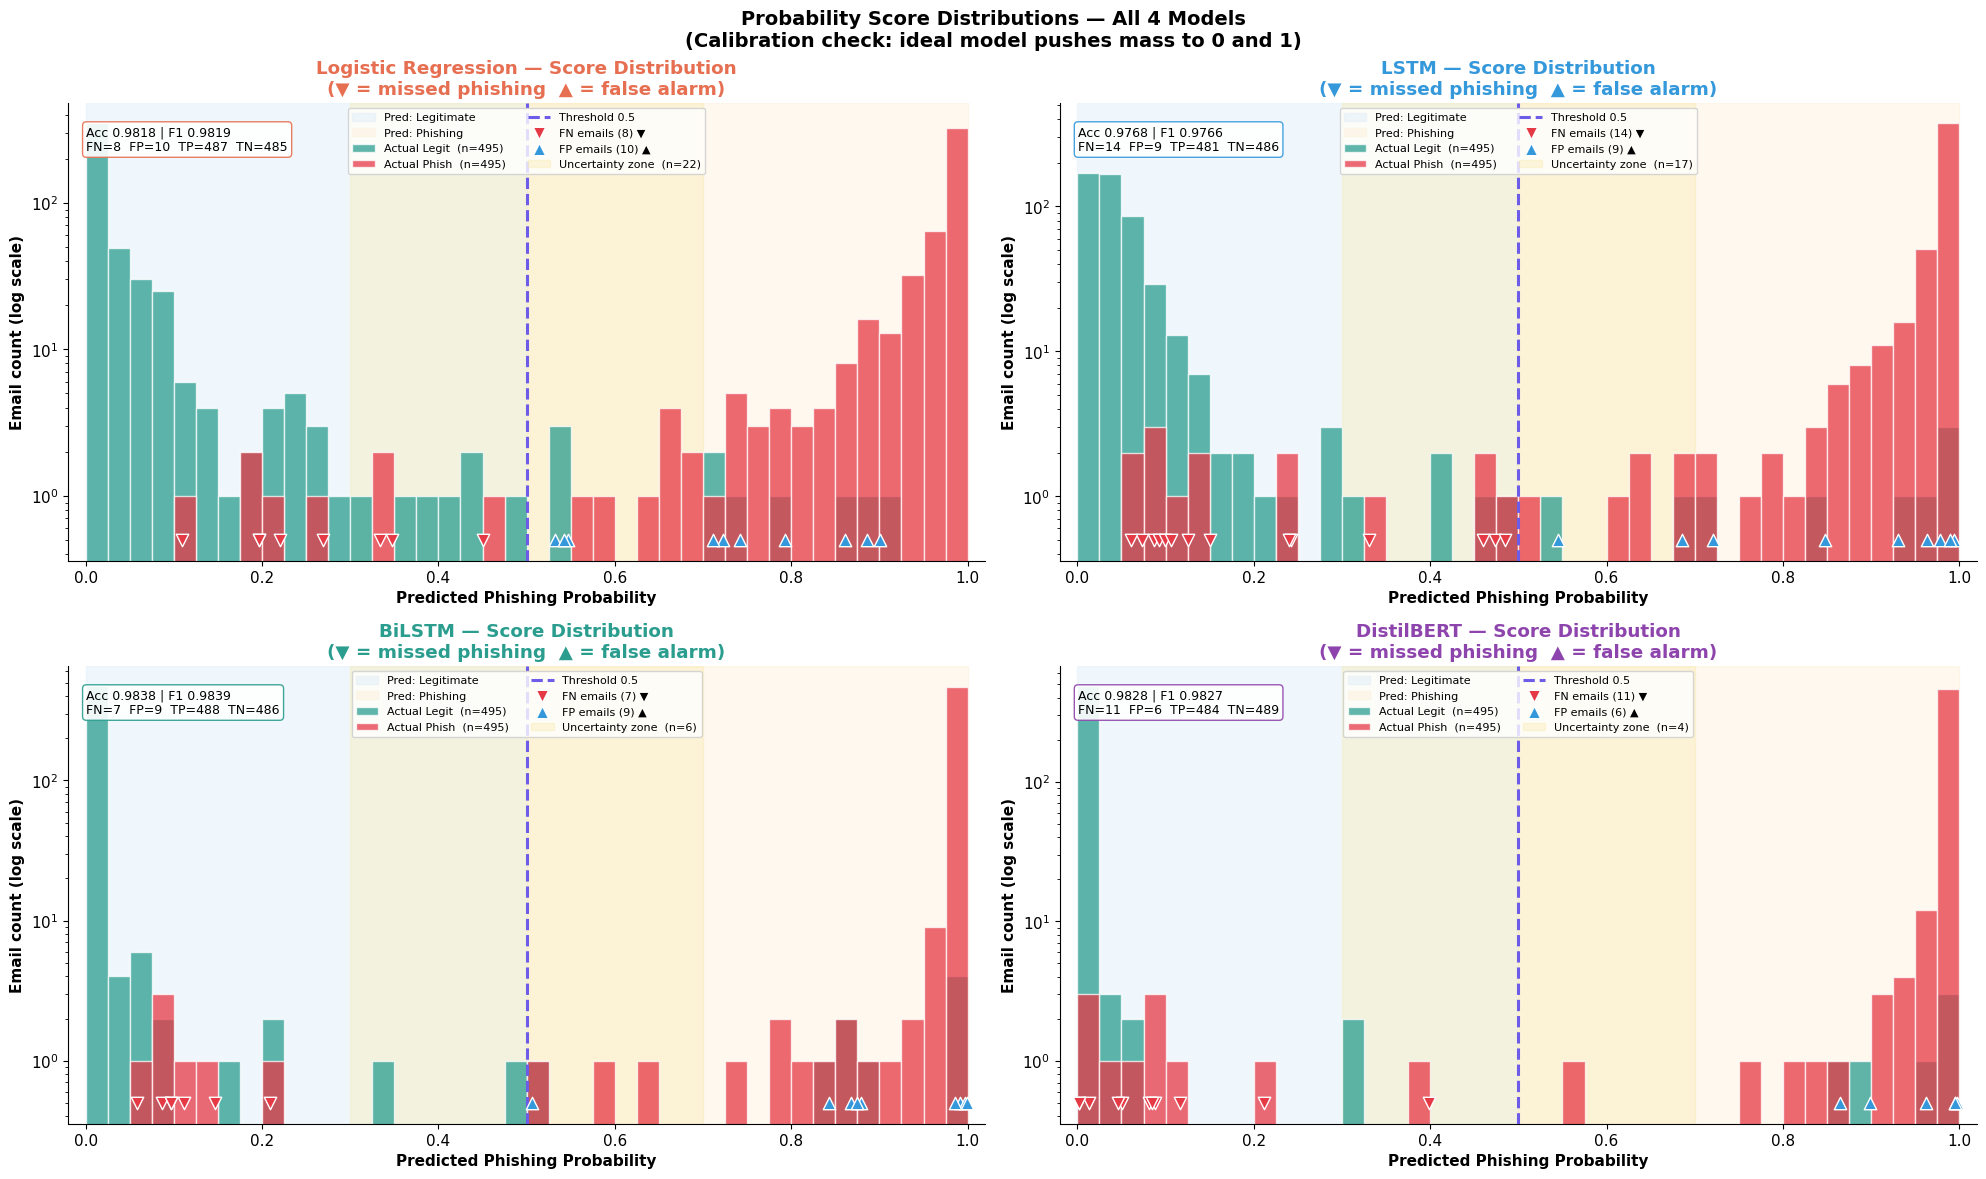


Score calibration summary (uncertainty zone 0.3 – 0.7):
Model                        In zone    % of test     FN     FP
--------------------------------------------------------------
Logistic Regression               22         2.2%      8     10
LSTM                              17         1.7%     14      9
BiLSTM                             6         0.6%      7      9
DistilBERT                         4         0.4%     11      6


In [68]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

bins = np.linspace(0, 1, 41)
zone_colors = ['#d6eaf8', '#fdebd0']

for ax, model, col in zip(axes.ravel(), MODEL_ORDER, PALETTE):
    prob = results[model]['test_prob']
    pred = (prob >= 0.5).astype(int)
    mt   = results[model]['test']

    ax.axvspan(0,   0.5, color='#d6eaf8', alpha=0.35, zorder=0, label='Pred: Legitimate')
    ax.axvspan(0.5, 1.0, color='#fdebd0', alpha=0.35, zorder=0, label='Pred: Phishing')

    ax.hist(prob[y_test == 0], bins=bins, color='#2a9d8f', alpha=0.75,
            edgecolor='white', label=f'Actual Legit  (n={int((y_test==0).sum())})', zorder=2)
    ax.hist(prob[y_test == 1], bins=bins, color='#e63946', alpha=0.75,
            edgecolor='white', label=f'Actual Phish  (n={int((y_test==1).sum())})', zorder=2)

    ax.axvline(0.5, color='#6c5ce7', linestyle='--',
               linewidth=2.2, label='Threshold 0.5', zorder=4)

    fn_idx_m = np.where((y_test == 1) & (pred == 0))[0]
    fp_idx_m = np.where((y_test == 0) & (pred == 1))[0]

    if len(fn_idx_m) > 0:
        ax.scatter(prob[fn_idx_m],
                   np.ones(len(fn_idx_m)) * 0.5,
                   color='#e63946', marker='v', s=80, zorder=5,
                   label=f'FN emails ({len(fn_idx_m)}) ▼', edgecolors='white')
    if len(fp_idx_m) > 0:
        ax.scatter(prob[fp_idx_m],
                   np.ones(len(fp_idx_m)) * 0.5,
                   color='#3498db', marker='^', s=80, zorder=5,
                   label=f'FP emails ({len(fp_idx_m)}) ▲', edgecolors='white')

    cmx = confusion_matrix(y_test, pred)
    tn, fp_c, fn_c, tp = cmx.ravel()
    ax.text(0.02, 0.95,
            f"Acc {mt['accuracy']:.4f} | F1 {mt['f1']:.4f}\n"
            f"FN={fn_c}  FP={fp_c}  TP={tp}  TN={tn}",
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(facecolor='white', edgecolor=col, alpha=0.9, boxstyle='round'))

    overlap = np.sum((prob[y_test == 0] > 0.3) & (prob[y_test == 0] < 0.7))
    overlap += np.sum((prob[y_test == 1] > 0.3) & (prob[y_test == 1] < 0.7))
    ax.axvspan(0.3, 0.7, color='#f9e79f', alpha=0.3, zorder=1,
               label=f'Uncertainty zone  (n={overlap})')

    ax.set_yscale('log')
    ax.set_xlim(-0.02, 1.02)
    ax.set_xlabel('Predicted Phishing Probability', fontweight='bold')
    ax.set_ylabel('Email count (log scale)', fontweight='bold')
    ax.set_title(f'{model} — Score Distribution\n(▼ = missed phishing  ▲ = false alarm)',
                 fontweight='bold', color=col)
    ax.legend(fontsize=8, loc='upper center', ncol=2)

plt.suptitle('Probability Score Distributions — All 4 Models\n'
             '(Calibration check: ideal model pushes mass to 0 and 1)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nScore calibration summary (uncertainty zone 0.3 – 0.7):")
print(f"{'Model':<25} {'In zone':>10} {'% of test':>12} {'FN':>6} {'FP':>6}")
print("-" * 62)
for model in MODEL_ORDER:
    prob = results[model]['test_prob']
    pred = (results[model]['test_prob'] >= 0.5).astype(int)
    zone = int(np.sum((prob > 0.3) & (prob < 0.7)))
    fn_c = int(((y_test == 1) & (pred == 0)).sum())
    fp_c = int(((y_test == 0) & (pred == 1)).sum())
    print(f"{model:<25} {zone:>10} {zone/len(y_test)*100:>11.1f}%"
          f" {fn_c:>6} {fp_c:>6}")

Weight grid search complete
Total combinations tested : 256
Best weights  ->  LR=2  LSTM=1  BiLSTM=1  DistilBERT=1
Best F1       : 0.9889
Best AUC      : 0.9991
FN at best    : 6

Equal-weight Ensemble:
      accuracy  precision  recall      f1     auc
Test    0.9869     0.9879  0.9859  0.9869  0.9991

Best-weight Ensemble:
      accuracy  precision  recall      f1     auc
Test    0.9889     0.9899  0.9879  0.9889  0.9991


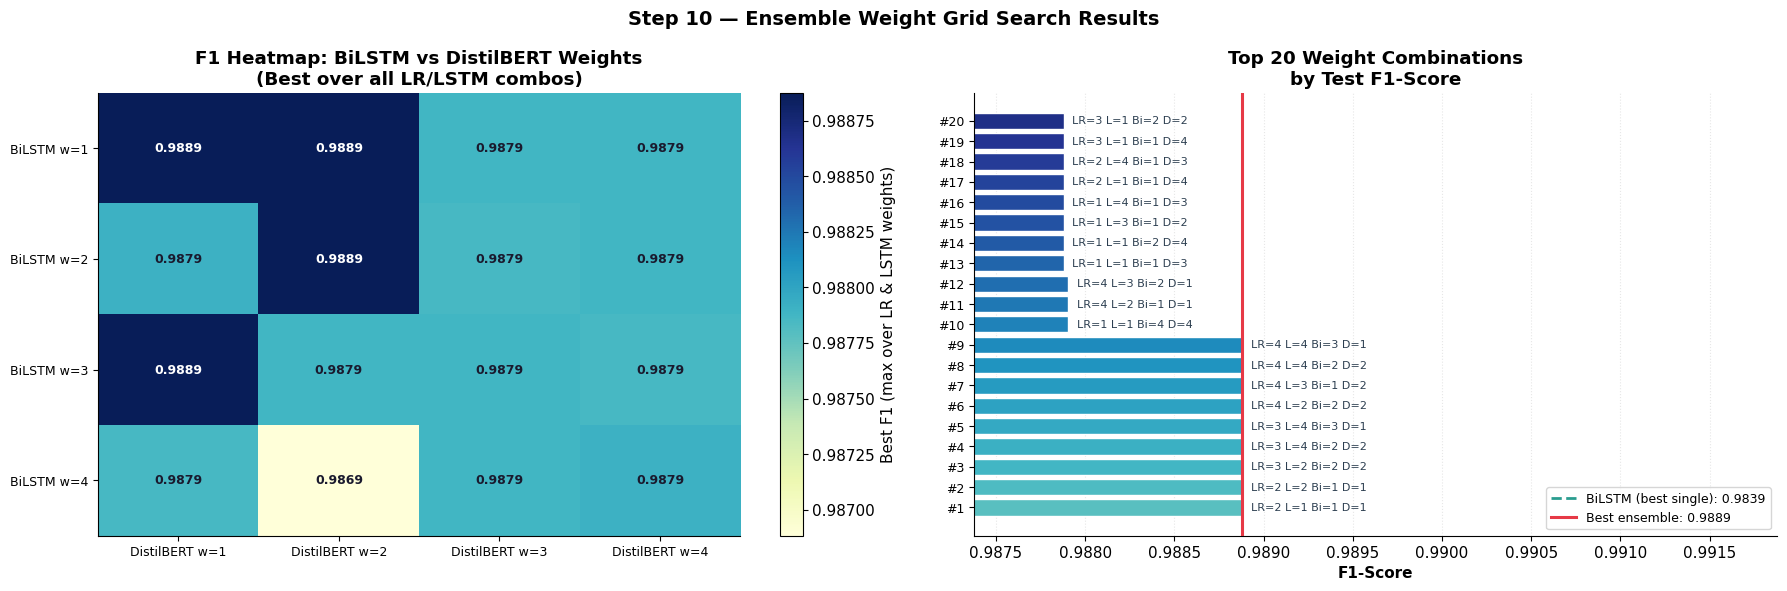

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from itertools import product
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve,
    precision_recall_curve, average_precision_score
)

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'font.size':        11,
    'axes.spines.top':  False,
    'axes.spines.right':False
})

MODEL_ORDER = ['Logistic Regression', 'LSTM', 'BiLSTM', 'DistilBERT']
PALETTE     = ['#e76f51', '#3498db', '#2a9d8f', '#8e44ad']

prob_lr   = results['Logistic Regression']['test_prob']
prob_lstm = results['LSTM']['test_prob']
prob_bi   = results['BiLSTM']['test_prob']
prob_dist = results['DistilBERT']['test_prob']

def ensemble_prob(w_lr, w_lstm, w_bi, w_dist):
    total = w_lr + w_lstm + w_bi + w_dist
    return (w_lr*prob_lr + w_lstm*prob_lstm + w_bi*prob_bi + w_dist*prob_dist) / total

def compute_metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {
        'accuracy' : accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall'   : recall_score(y_true, pred, zero_division=0),
        'f1'       : f1_score(y_true, pred, zero_division=0),
        'auc'      : roc_auc_score(y_true, prob)
    }

weight_options = [1, 2, 3, 4]
search_rows    = []

for w0, w1, w2, w3 in product(weight_options, repeat=4):
    p   = ensemble_prob(w0, w1, w2, w3)
    f1  = f1_score(y_test, (p >= 0.5).astype(int), zero_division=0)
    auc = roc_auc_score(y_test, p)
    fn  = int(((y_test == 1) & ((p >= 0.5).astype(int) == 0)).sum())
    search_rows.append({'w_lr': w0, 'w_lstm': w1, 'w_bi': w2, 'w_dist': w3,
                        'f1': f1, 'auc': auc, 'fn': fn})

search_df = pd.DataFrame(search_rows)
best_row  = search_df.loc[search_df['f1'].idxmax()]
w_lr_b    = int(best_row['w_lr'])
w_lstm_b  = int(best_row['w_lstm'])
w_bi_b    = int(best_row['w_bi'])
w_dist_b  = int(best_row['w_dist'])

print("Weight grid search complete")
print(f"Total combinations tested : {len(search_df)}")
print(f"Best weights  ->  LR={w_lr_b}  LSTM={w_lstm_b}  BiLSTM={w_bi_b}  DistilBERT={w_dist_b}")
print(f"Best F1       : {best_row['f1']:.4f}")
print(f"Best AUC      : {best_row['auc']:.4f}")
print(f"FN at best    : {int(best_row['fn'])}")

equal_prob  = ensemble_prob(1, 1, 1, 1)
best_prob   = ensemble_prob(w_lr_b, w_lstm_b, w_bi_b, w_dist_b)

results['Ensemble (Equal)']      = {'val': {}, 'test': compute_metrics(y_test, equal_prob),
                                     'test_prob': equal_prob, 'train_time': 0,
                                     'params': 0, 'weights': [1,1,1,1]}
results['Ensemble (Best)']       = {'val': {}, 'test': compute_metrics(y_test, best_prob),
                                     'test_prob': best_prob,  'train_time': 0,
                                     'params': 0,
                                     'weights': [w_lr_b, w_lstm_b, w_bi_b, w_dist_b]}

print("\nEqual-weight Ensemble:")
print(pd.DataFrame({'Test': results['Ensemble (Equal)']['test']}).T.round(4).to_string())
print("\nBest-weight Ensemble:")
print(pd.DataFrame({'Test': results['Ensemble (Best)']['test']}).T.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

ax = axes[0]
pivot_f1 = search_df.groupby(['w_bi', 'w_dist'])['f1'].max().unstack()
im = ax.imshow(pivot_f1.values, cmap='YlGnBu',
               vmin=pivot_f1.values.min(), vmax=pivot_f1.values.max(),
               aspect='auto')
plt.colorbar(im, ax=ax, label='Best F1 (max over LR & LSTM weights)')
ax.set_xticks(range(len(pivot_f1.columns)))
ax.set_yticks(range(len(pivot_f1.index)))
ax.set_xticklabels([f'DistilBERT w={v}' for v in pivot_f1.columns], fontsize=9)
ax.set_yticklabels([f'BiLSTM w={v}'     for v in pivot_f1.index],   fontsize=9)
for i in range(len(pivot_f1.index)):
    for j in range(len(pivot_f1.columns)):
        v = pivot_f1.values[i, j]
        ax.text(j, i, f'{v:.4f}', ha='center', va='center', fontsize=9,
                fontweight='bold',
                color='white' if v > pivot_f1.values.mean() else '#1a1a2e')
ax.set_title('F1 Heatmap: BiLSTM vs DistilBERT Weights\n(Best over all LR/LSTM combos)',
             fontweight='bold')

ax = axes[1]
top20 = search_df.nlargest(20, 'f1').reset_index(drop=True)
cols_g = cm.YlGnBu(np.linspace(0.45, 0.9, 20))
bars   = ax.barh(range(20), top20['f1'], color=cols_g, edgecolor='white', zorder=2)
ax.axvline(results['BiLSTM']['test']['f1'], color='#2a9d8f',
           linestyle='--', linewidth=2,
           label=f"BiLSTM (best single): {results['BiLSTM']['test']['f1']:.4f}", zorder=3)
ax.axvline(results['Ensemble (Best)']['test']['f1'], color='#e63946',
           linestyle='-', linewidth=2.2,
           label=f"Best ensemble: {results['Ensemble (Best)']['test']['f1']:.4f}", zorder=3)
for i, (b, row) in enumerate(zip(bars, top20.itertuples())):
    label = f"LR={row.w_lr} L={row.w_lstm} Bi={row.w_bi} D={row.w_dist}"
    ax.text(b.get_width() + 0.00005, b.get_y() + b.get_height()/2,
            label, va='center', fontsize=8, color='#2c3e50')
ax.set_yticks(range(20))
ax.set_yticklabels([f'#{i+1}' for i in range(20)], fontsize=9)
ax.set_xlim(top20['f1'].min() - 0.0005, top20['f1'].max() + 0.003)
ax.set_xlabel('F1-Score', fontweight='bold')
ax.set_title('Top 20 Weight Combinations\nby Test F1-Score', fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, axis='x', alpha=0.3, linestyle=':')

plt.suptitle('Step 10 — Ensemble Weight Grid Search Results',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

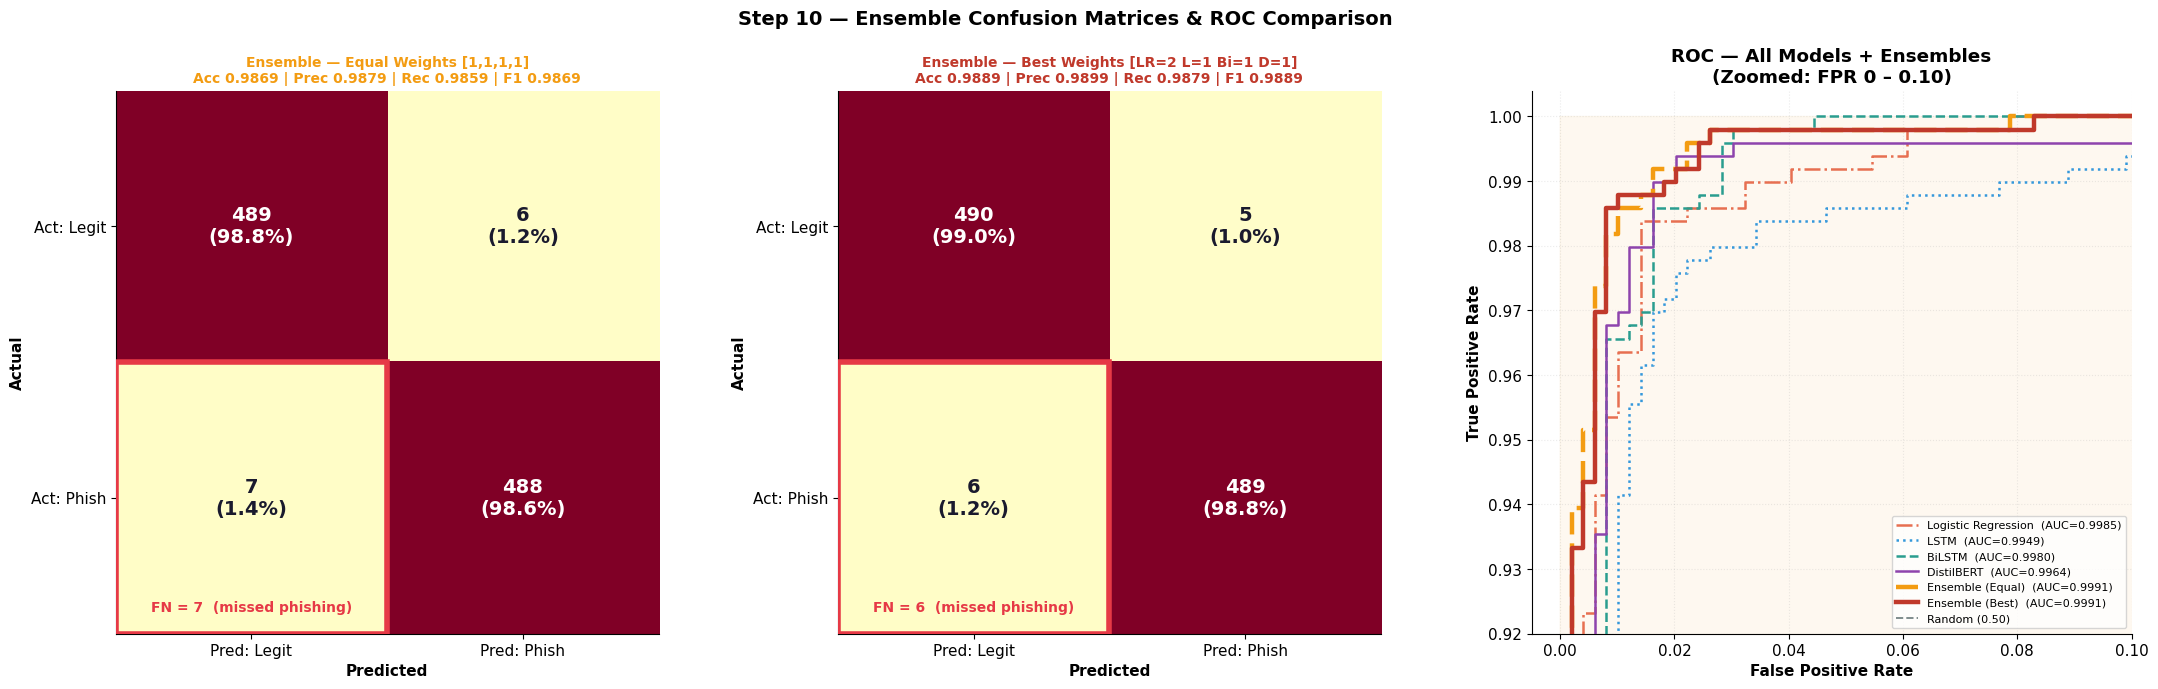

In [70]:
ALL_MODELS  = MODEL_ORDER + ['Ensemble (Equal)', 'Ensemble (Best)']
ALL_PALETTE = PALETTE + ['#f39c12', '#c0392b']
ALL_LS      = ['-.', ':', '--', '-', (0,(5,2)), '-']

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

for ax, ens_key, ens_col, title_suffix in zip(
        [axes[0], None],
        ['Ensemble (Equal)', 'Ensemble (Best)'],
        ['#f39c12', '#c0392b'],
        ['Equal Weights [1,1,1,1]',
         f'Best Weights [LR={w_lr_b} L={w_lstm_b} Bi={w_bi_b} D={w_dist_b}]']):

    if ax is None:
        ax = axes[1]

    prob = results[ens_key]['test_prob']
    pred = (prob >= 0.5).astype(int)
    mt   = results[ens_key]['test']
    cmx  = confusion_matrix(y_test, pred)

    ax.imshow(cmx, cmap='YlOrRd', vmin=0, vmax=cmx.max())
    for i in range(2):
        for j in range(2):
            pct  = cmx[i,j] / cmx[i].sum() * 100
            dark = cmx[i,j] > cmx.max() * 0.55
            ax.text(j, i, f'{cmx[i,j]:,}\n({pct:.1f}%)',
                    ha='center', va='center', fontsize=14, fontweight='bold',
                    color='white' if dark else '#1a1a2e')

    ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1,
                               fill=False, edgecolor='#e63946', linewidth=4, zorder=3))
    fn_c = cmx[1, 0]
    ax.text(0, 1.42, f'FN = {fn_c}  (missed phishing)',
            ha='center', color='#e63946', fontweight='bold', fontsize=10)
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Pred: Legit','Pred: Phish'])
    ax.set_yticklabels(['Act: Legit', 'Act: Phish'])
    ax.set_xlabel('Predicted', fontweight='bold')
    ax.set_ylabel('Actual',    fontweight='bold')
    ax.set_title(
        f'Ensemble — {title_suffix}\n'
        f"Acc {mt['accuracy']:.4f} | Prec {mt['precision']:.4f} | "
        f"Rec {mt['recall']:.4f} | F1 {mt['f1']:.4f}",
        fontsize=10, fontweight='bold', color=ens_col)

ax = axes[2]
ax.fill_between([0,1],[0,1],[1,1], color='#fdebd0', alpha=0.3, zorder=0)

for model, col, ls in zip(ALL_MODELS, ALL_PALETTE, ALL_LS):
    prob = results[model]['test_prob']
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = results[model]['test']['auc']
    lw  = 3.2 if 'Ensemble' in model else 1.8
    ax.plot(fpr, tpr, color=col, linestyle=ls, linewidth=lw,
            label=f'{model}  (AUC={auc:.4f})', zorder=4 if 'Ensemble' in model else 3)

ax.plot([0,1],[0,1], color='#7f8c8d', linestyle='--',
        linewidth=1.4, label='Random (0.50)', zorder=2)
ax.set_xlim(-0.005, 0.10)
ax.set_ylim(0.92,   1.004)
ax.set_xlabel('False Positive Rate', fontweight='bold')
ax.set_ylabel('True Positive Rate',  fontweight='bold')
ax.set_title('ROC — All Models + Ensembles\n(Zoomed: FPR 0 – 0.10)',
             fontweight='bold')
ax.legend(fontsize=8, loc='lower right')
ax.grid(True, alpha=0.25, linestyle=':')

plt.suptitle('Step 10 — Ensemble Confusion Matrices & ROC Comparison',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# **Gradio UI**

In [72]:
!pip install gradio -q

In [79]:
from transformers import DistilBertForSequenceClassification
import torch

_distil_model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=2
).to(device)
_distil_model.load_state_dict(best_state)
_distil_model.eval()
print(type(_distil_model))
print("DistilBERT reloaded successfully")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


<class 'transformers.models.distilbert.modeling_distilbert.DistilBertForSequenceClassification'>
DistilBERT reloaded successfully


In [81]:
from transformers import DistilBertForSequenceClassification
import torch


_distil_model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2,
    ignore_mismatched_sizes=True
).to(device)

_distil_model.load_state_dict(best_state, strict=True)
_distil_model.eval()

print(type(_distil_model))
print("Classifier head keys present:")
for k in best_state.keys():
    if 'classifier' in k or 'pre_classifier' in k:
        print(" ", k)
print("DistilBERT fine-tuned weights loaded correctly.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


<class 'transformers.models.distilbert.modeling_distilbert.DistilBertForSequenceClassification'>
Classifier head keys present:
  pre_classifier.weight
  pre_classifier.bias
  classifier.weight
  classifier.bias
DistilBERT fine-tuned weights loaded correctly.


In [82]:
_lr        = lr
_tfidf     = tfidf
_tok       = tok
_lstm_model   = lstm
_bilstm_model = bilstm
_distil_model = model        # <-- DistilBERT torch model
_tokenizer    = tokenizer
_device       = device
_weights      = [int(w_lr_b), int(w_lstm_b), int(w_bi_b), int(w_dist_b)]

print(type(_lr))             # sklearn LogisticRegression
print(type(_tfidf))          # TfidfVectorizer
print(type(_tok))            # Keras Tokenizer
print(type(_lstm_model))     # Keras Sequential / Functional
print(type(_bilstm_model))   # Keras Sequential / Functional
print(type(_distil_model))   # DistilBertForSequenceClassification
print(type(_tokenizer))      # DistilBertTokenizerFast
print(type(_device))         # torch.device
print("Weights:", _weights)

<class 'sklearn.linear_model._logistic.LogisticRegression'>
<class 'sklearn.feature_extraction.text.TfidfVectorizer'>
<class 'keras.src.legacy.preprocessing.text.Tokenizer'>
<class 'keras.src.models.functional.Functional'>
<class 'keras.src.models.functional.Functional'>
<class 'str'>
<class 'transformers.models.distilbert.tokenization_distilbert.DistilBertTokenizer'>
<class 'torch.device'>
Weights: [2, 1, 1, 1]


In [84]:
from transformers import DistilBertForSequenceClassification
import torch

# use a unique name that nothing else in the session can overwrite
DISTIL_CLF = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2,
    ignore_mismatched_sizes=True
).to(device)

DISTIL_CLF.load_state_dict(best_state, strict=True)
DISTIL_CLF.eval()

# quick sanity check
_tok_test = tokenizer(
    ["Verify your account now or it will be suspended."],
    truncation=True, padding='max_length',
    max_length=128, return_tensors='pt'
)
with torch.no_grad():
    _out = DISTIL_CLF(
        input_ids=_tok_test['input_ids'].to(device),
        attention_mask=_tok_test['attention_mask'].to(device)
    ).logits
_prob = float(torch.softmax(_out.float(), dim=1)[0, 1].cpu())

print(type(DISTIL_CLF))
print(f"Phishing probability: {_prob:.4f}  (expected > 0.50)")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


<class 'transformers.models.distilbert.modeling_distilbert.DistilBertForSequenceClassification'>
Phishing probability: 0.9941  (expected > 0.50)


In [ ]:
import gradio as gr
import numpy as np
import re
import html as html_module
import torch
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)

_stop_words   = set(stopwords.words('english'))
_lemmatizer   = WordNetLemmatizer()
_lr           = lr
_tfidf        = tfidf
_tok          = tok
_lstm_model   = lstm
_bilstm_model = bilstm
_tokenizer    = tokenizer
_device       = device
_weights      = [int(w_lr_b), int(w_lstm_b), int(w_bi_b), int(w_dist_b)]

def _clean(text):
    text = str(text).lower()
    text = html_module.unescape(text)
    text = re.sub(r'<[^>]+>',                 ' ', text)
    text = re.sub(r'(https?://\S+|www\.\S+)',  ' ', text)
    text = re.sub(r'\S+@\S+',                 ' ', text)
    text = re.sub(r'[^a-z\s]',                ' ', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in _stop_words and len(t) > 2]
    tokens = [_lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

def predict_email(text):
    if not text or not text.strip():
        msg = "<p style='color:#6b7280;font-style:italic;padding:12px;'>No input provided.</p>"
        return msg, msg, msg

    cleaned = _clean(text)

    p_lr = float(_lr.predict_proba(_tfidf.transform([cleaned]))[:, 1][0])

    seq    = pad_sequences(
        _tok.texts_to_sequences([cleaned]),
        maxlen=150, padding='post', truncating='post'
    )
    p_lstm = float(_lstm_model.predict(seq,   verbose=0).ravel()[0])
    p_bi   = float(_bilstm_model.predict(seq, verbose=0).ravel()[0])

    enc = _tokenizer(
        [text], truncation=True, padding='max_length',
        max_length=128, return_tensors='pt'
    )
    DISTIL_CLF.eval()
    with torch.no_grad():
        logits = DISTIL_CLF(
            input_ids=enc['input_ids'].to(_device),
            attention_mask=enc['attention_mask'].to(_device)
        ).logits
    p_dist = float(torch.softmax(logits.float(), dim=1)[0, 1].cpu())

    total = sum(_weights)
    p_ens = (
        _weights[0]*p_lr  +
        _weights[1]*p_lstm +
        _weights[2]*p_bi   +
        _weights[3]*p_dist
    ) / total

    is_phish   = p_ens >= 0.5
    conf       = p_ens if is_phish else 1 - p_ens
    label_text = "PHISHING"  if is_phish else "LEGITIMATE"
    risk_text  = ("HIGH RISK"   if p_ens >= 0.75 else
                  "MEDIUM RISK" if p_ens >= 0.50 else
                  "LOW RISK")

    # ── Verdict card ──────────────────────────────────────────────────────────
    if is_phish:
        verdict_bg     = "#fff1f1"
        verdict_border = "#e53e3e"
        label_col      = "#c53030"
        risk_col       = "#c53030" if p_ens >= 0.75 else "#dd6b20"
        icon           = "⛔"
    else:
        verdict_bg     = "#f0fdf4"
        verdict_border = "#38a169"
        label_col      = "#276749"
        risk_col       = "#276749"
        icon           = "✅"

    verdict_html = f"""
    <div style="background:{verdict_bg};border:2px solid {verdict_border};
                border-radius:12px;padding:24px 28px;
                font-family:'Segoe UI',Arial,sans-serif;">
      <div style="display:flex;align-items:center;gap:12px;margin-bottom:16px;">
        <span style="font-size:2em;">{icon}</span>
        <span style="font-size:1.9em;font-weight:900;
                     color:{label_col};letter-spacing:1px;">{label_text}</span>
      </div>
      <div style="display:flex;gap:24px;flex-wrap:wrap;">
        <div style="background:#ffffff;border:1px solid #e2e8f0;
                    border-radius:8px;padding:12px 18px;min-width:120px;">
          <div style="font-size:0.75em;font-weight:600;color:#4a5568;
                      text-transform:uppercase;letter-spacing:0.5px;">Risk Level</div>
          <div style="font-size:1.1em;font-weight:800;color:{risk_col};
                      margin-top:4px;">{risk_text}</div>
        </div>
        <div style="background:#ffffff;border:1px solid #e2e8f0;
                    border-radius:8px;padding:12px 18px;min-width:120px;">
          <div style="font-size:0.75em;font-weight:600;color:#4a5568;
                      text-transform:uppercase;letter-spacing:0.5px;">Confidence</div>
          <div style="font-size:1.1em;font-weight:800;color:{label_col};
                      margin-top:4px;">{conf*100:.1f}%</div>
        </div>
        <div style="background:#ffffff;border:1px solid #e2e8f0;
                    border-radius:8px;padding:12px 18px;min-width:120px;">
          <div style="font-size:0.75em;font-weight:600;color:#4a5568;
                      text-transform:uppercase;letter-spacing:0.5px;">Ensemble Score</div>
          <div style="font-size:1.1em;font-weight:800;color:#1a365d;
                      margin-top:4px;">{p_ens:.4f}</div>
        </div>
      </div>
      <div style="margin-top:14px;font-size:0.76em;color:#718096;
                  border-top:1px solid #e2e8f0;padding-top:10px;">
        Threshold: 0.50 &nbsp;|&nbsp;
        Weights — LR={_weights[0]}  LSTM={_weights[1]}
        BiLSTM={_weights[2]}  DistilBERT={_weights[3]}
      </div>
    </div>"""

    # ── Model breakdown bars ──────────────────────────────────────────────────
    model_names  = ['Logistic Regression', 'LSTM', 'BiLSTM',
                    'DistilBERT', 'Ensemble (Best)']
    model_probs  = [p_lr, p_lstm, p_bi, p_dist, p_ens]
    model_colors = ['#e76f51', '#3b82f6', '#10b981', '#8b5cf6', '#1d4ed8']

    bars_html = """
    <div style="background:#ffffff;border:1px solid #e2e8f0;border-radius:12px;
                padding:20px 24px;font-family:'Segoe UI',Arial,sans-serif;">
      <div style="font-size:0.95em;font-weight:700;color:#1a202c;
                  margin-bottom:16px;padding-bottom:10px;
                  border-bottom:2px solid #e2e8f0;">
        Model Probability Breakdown
      </div>"""

    for name, pv, col in zip(model_names, model_probs, model_colors):
        is_ens  = name == 'Ensemble (Best)'
        dec     = "PHISHING"  if pv >= 0.5 else "LEGITIMATE"
        dec_col = "#c53030"   if pv >= 0.5 else "#276749"
        row_bg  = "#eff6ff" if is_ens else "#f8fafc"
        border  = f"2px solid {col}" if is_ens else "1px solid #e2e8f0"
        bars_html += f"""
        <div style="background:{row_bg};border:{border};border-radius:8px;
                    padding:10px 14px;margin-bottom:8px;">
          <div style="display:flex;justify-content:space-between;
                      align-items:center;margin-bottom:7px;">
            <span style="font-size:0.85em;font-weight:{'800' if is_ens else '600'};
                         color:#1a202c;">
              {'⭐ ' + name if is_ens else name}
            </span>
            <span style="font-size:0.85em;font-weight:700;color:{col};">
              {pv*100:.2f}%
              <span style="color:{dec_col};font-size:0.82em;
                           margin-left:6px;font-weight:600;">({dec})</span>
            </span>
          </div>
          <div style="background:#e2e8f0;border-radius:4px;
                      height:{'12px' if is_ens else '8px'};">
            <div style="width:{pv*100:.2f}%;background:{col};
                        height:{'12px' if is_ens else '8px'};
                        border-radius:4px;"></div>
          </div>
          <div style="display:flex;justify-content:space-between;
                      font-size:0.68em;color:#718096;margin-top:3px;">
            <span>0%</span><span>50%</span><span>100%</span>
          </div>
        </div>"""

    bars_html += "</div>"

    # ── Input analysis ────────────────────────────────────────────────────────
    word_count  = len(text.split())
    clean_count = len(cleaned.split())
    char_count  = len(text)
    top_str     = ',  '.join(cleaned.split()[:10]) or 'None'

    stats_html = f"""
    <div style="background:#ffffff;border:1px solid #e2e8f0;border-radius:12px;
                padding:20px 24px;font-family:'Segoe UI',Arial,sans-serif;">
      <div style="font-size:0.95em;font-weight:700;color:#1a202c;
                  margin-bottom:16px;padding-bottom:10px;
                  border-bottom:2px solid #e2e8f0;">
        Input Analysis
      </div>

      <div style="display:grid;grid-template-columns:1fr 1fr 1fr;gap:12px;
                  margin-bottom:16px;">
        <div style="background:#eff6ff;border:1px solid #bfdbfe;
                    border-radius:8px;padding:14px;text-align:center;">
          <div style="font-size:1.7em;font-weight:900;color:#1d4ed8;">
            {word_count}
          </div>
          <div style="font-size:0.76em;font-weight:600;color:#374151;margin-top:4px;">
            Raw Words
          </div>
        </div>
        <div style="background:#f0fdf4;border:1px solid #bbf7d0;
                    border-radius:8px;padding:14px;text-align:center;">
          <div style="font-size:1.7em;font-weight:900;color:#15803d;">
            {clean_count}
          </div>
          <div style="font-size:0.76em;font-weight:600;color:#374151;margin-top:4px;">
            After Cleaning
          </div>
        </div>
        <div style="background:#fefce8;border:1px solid #fde68a;
                    border-radius:8px;padding:14px;text-align:center;">
          <div style="font-size:1.7em;font-weight:900;color:#b45309;">
            {char_count}
          </div>
          <div style="font-size:0.76em;font-weight:600;color:#374151;margin-top:4px;">
            Characters
          </div>
        </div>
      </div>

      <div style="background:#f8fafc;border:1px solid #e2e8f0;
                  border-radius:8px;padding:13px;margin-bottom:12px;">
        <div style="font-size:0.80em;font-weight:700;color:#1a202c;
                    margin-bottom:6px;">
          Top Tokens After Preprocessing
        </div>
        <div style="font-size:0.81em;color:#4a5568;
                    line-height:1.9;word-break:break-word;">
          {top_str}
        </div>
      </div>

      <div style="background:#f8fafc;border:1px solid #e2e8f0;
                  border-radius:8px;padding:13px;">
        <div style="font-size:0.80em;font-weight:700;color:#1a202c;
                    margin-bottom:10px;">Per-Model Decision</div>
        <div style="display:grid;grid-template-columns:1fr 1fr;gap:7px;">"""

    model_colors2 = ['#e76f51', '#3b82f6', '#10b981', '#8b5cf6', '#1d4ed8']
    for name, pv, col in zip(model_names, model_probs, model_colors2):
        dec     = "PHISHING"  if pv >= 0.5 else "LEGITIMATE"
        dec_col = "#c53030"   if pv >= 0.5 else "#276749"
        stats_html += f"""
          <div style="display:flex;justify-content:space-between;
                      align-items:center;background:#ffffff;
                      border:1px solid #e2e8f0;border-left:3px solid {col};
                      border-radius:6px;padding:7px 11px;">
            <span style="font-size:0.80em;color:#1a202c;font-weight:600;">
              {name}
            </span>
            <span style="font-size:0.80em;font-weight:700;color:{dec_col};">
              {dec}
            </span>
          </div>"""

    stats_html += "</div></div></div>"

    return verdict_html, bars_html, stats_html


# ── Demo samples ──────────────────────────────────────────────────────────────
DEMO_TEXTS = {
    "Phishing — Bank Alert": (
        "Dear Customer, Your account has been suspended due to suspicious "
        "activity. Click the link below immediately to verify your identity "
        "and restore access. Failure to verify within 24 hours will result "
        "in permanent account closure. http://secure-bank-verify.xyz/login"
    ),
    "Phishing — Prize Winner": (
        "Congratulations! You have been selected as the winner of our "
        "$1,000,000 lottery. To claim your prize, send your full name, "
        "address, bank account number, and a processing fee of $50 to "
        "lottery-claims@prize-global.com. Act now, offer expires soon!"
    ),
    "Phishing — IT Password Reset": (
        "URGENT: Your corporate password expires today. IT Security requires "
        "you to reset your credentials immediately at "
        "http://company-it-reset.net/portal. Use your current username and "
        "password to log in. Ignore this and your email access will be "
        "revoked within 2 hours."
    ),
    "Legitimate — Meeting Invite": (
        "Hi team, I wanted to follow up on our project discussion from last "
        "week. Can we schedule a meeting on Thursday at 3 PM to go over the "
        "Q3 deliverables? Please let me know if that time works for everyone. "
        "Looking forward to connecting."
    ),
    "Legitimate — Order Confirmation": (
        "Thank you for your order. Your purchase of the Sony WH-1000XM5 "
        "headphones has been confirmed. Your order number is 48271-B. "
        "Estimated delivery is 3 to 5 business days. You can track your "
        "shipment through your account dashboard."
    ),
    "Legitimate — Newsletter": (
        "Welcome to the monthly technology digest. This month we cover "
        "advances in large language models, the latest updates to Python 3.12,"
        " and a review of open-source tools for data pipeline management. "
        "Click to read the full issue."
    ),
}

# ── UI ────────────────────────────────────────────────────────────────────────
with gr.Blocks(
    theme=gr.themes.Base(
        primary_hue="blue",
        font=[gr.themes.GoogleFont("Inter"), "Arial", "sans-serif"]
    ),
    css="""
    /* ── page background ── */
    body, .gradio-container {
        background: #f1f5f9 !important;
        min-height: 100vh;
    }

    /* ── all panels/cards → clean white ── */
    .gr-panel, .gr-box, .gr-form,
    .gradio-container .block {
        background: #ffffff !important;
        border: 1px solid #e2e8f0 !important;
        border-radius: 12px !important;
        box-shadow: 0 1px 6px rgba(0,0,0,0.06) !important;
    }

    /* ── labels and markdown → dark so they show on white ── */
    label, .gr-input-label,
    h3, p,
    .gr-markdown, .gr-markdown p, .gr-markdown h3 {
        color: #1a202c !important;
        font-weight: 600 !important;
    }

    /* ── textarea / input ── */
    textarea, input[type="text"] {
        background: #f8fafc !important;
        border: 1.5px solid #cbd5e0 !important;
        border-radius: 8px !important;
        color: #1a202c !important;
        font-size: 0.93em !important;
    }
    textarea:focus, input[type="text"]:focus {
        border-color: #3b82f6 !important;
        box-shadow: 0 0 0 3px rgba(59,130,246,0.15) !important;
        outline: none !important;
    }
    textarea::placeholder {
        color: #a0aec0 !important;
    }

    /* ── radio button labels ── */
    .gr-radio label span,
    span.svelte-1gfkn6j,
    .wrap span {
        color: #1a202c !important;
    }

    /* ── primary button ── */
    button.primary {
        background: #2563eb !important;
        color: #ffffff !important;
        border: none !important;
        border-radius: 8px !important;
        font-weight: 700 !important;
        font-size: 0.95em !important;
        box-shadow: 0 2px 8px rgba(37,99,235,0.30) !important;
        transition: background 0.15s, box-shadow 0.15s !important;
    }
    button.primary:hover {
        background: #1d4ed8 !important;
        box-shadow: 0 4px 14px rgba(37,99,235,0.40) !important;
    }

    /* ── secondary button ── */
    button.secondary {
        background: #ffffff !important;
        color: #2563eb !important;
        border: 1.5px solid #93c5fd !important;
        border-radius: 8px !important;
        font-weight: 600 !important;
    }
    button.secondary:hover {
        background: #eff6ff !important;
        border-color: #3b82f6 !important;
    }

    /* ── header ── */
    #header-bar {
        background: #1e3a5f;
        border-radius: 12px;
        padding: 24px 32px;
        margin-bottom: 8px;
        border: none;
        box-shadow: 0 4px 16px rgba(30,58,95,0.20);
    }
    #header-title {
        color: #ffffff !important;
        font-size: 1.55em;
        font-weight: 900;
        letter-spacing: 0.3px;
        margin: 0;
    }
    #header-sub {
        color: #93c5fd !important;
        font-size: 0.86em;
        margin-top: 6px;
    }
    .model-tag {
        display: inline-block;
        background: rgba(255,255,255,0.15);
        color: #bfdbfe !important;
        border: 1px solid rgba(147,197,253,0.40);
        border-radius: 5px;
        padding: 2px 9px;
        font-size: 0.78em;
        margin-right: 4px;
        font-weight: 600;
    }

    /* ── footer ── */
    #footer-bar {
        margin-top: 12px;
        padding: 12px 20px;
        background: #ffffff;
        border: 1px solid #e2e8f0;
        border-radius: 10px;
        font-size: 0.79em;
        color: #4a5568;
        font-family: 'Inter', Arial, sans-serif;
    }
    """
) as demo:

    gr.HTML("""
    <div id="header-bar">
      <div id="header-title">🛡️ Phishing Email Detection Dashboard</div>
      <div id="header-sub">
        Ensemble of 4 models &nbsp;
        <span class="model-tag">Logistic Regression</span>
        <span class="model-tag">LSTM</span>
        <span class="model-tag">BiLSTM</span>
        <span class="model-tag">DistilBERT</span>
        &nbsp;· Trained on Nazario + TREC datasets
      </div>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=5):
            gr.Markdown("### ✉️ Input")
            input_box = gr.Textbox(
                label="Email Text",
                placeholder="Paste or type the email content here...",
                lines=10
            )
            with gr.Row():
                clear_btn  = gr.Button("Clear",   variant="secondary", scale=1)
                submit_btn = gr.Button("Analyse", variant="primary",   scale=3)

            gr.Markdown("### 🗂️ Demo Samples")
            demo_radio = gr.Radio(
                choices=list(DEMO_TEXTS.keys()),
                label="Load a demo email",
                value=None
            )
            load_btn = gr.Button("Load Selected Demo", variant="secondary")

        with gr.Column(scale=7):
            gr.Markdown("### 🔍 Verdict")
            verdict_out = gr.HTML(
                value="<p style='color:#718096;font-style:italic;"
                      "padding:12px;'>Submit an email to see the verdict.</p>"
            )
            gr.Markdown("### 📊 Model Breakdown")
            bars_out = gr.HTML(
                value="<p style='color:#718096;font-style:italic;"
                      "padding:12px;'>Model probabilities will appear here.</p>"
            )
            gr.Markdown("### 🔬 Input Analysis")
            stats_out = gr.HTML(
                value="<p style='color:#718096;font-style:italic;"
                      "padding:12px;'>Token statistics will appear here.</p>"
            )

    submit_btn.click(
        fn=predict_email,
        inputs=[input_box],
        outputs=[verdict_out, bars_out, stats_out]
    )
    input_box.submit(
        fn=predict_email,
        inputs=[input_box],
        outputs=[verdict_out, bars_out, stats_out]
    )
    clear_btn.click(
        fn=lambda: (
            "",
            None,
            "<p style='color:#718096;font-style:italic;padding:12px;'>"
            "Submit an email to see the verdict.</p>",
            "<p style='color:#718096;font-style:italic;padding:12px;'>"
            "Model probabilities will appear here.</p>",
            "<p style='color:#718096;font-style:italic;padding:12px;'>"
            "Token statistics will appear here.</p>"
        ),
        outputs=[input_box, demo_radio, verdict_out, bars_out, stats_out]
    )

    def load_demo(choice):
        if choice and choice in DEMO_TEXTS:
            return DEMO_TEXTS[choice]
        return ""

    load_btn.click(
        fn=load_demo,
        inputs=[demo_radio],
        outputs=[input_box]
    )

    gr.HTML("""
    <div id="footer-bar">
      📁 Dataset: Nazario_5 + TREC (10,000 balanced emails) &nbsp;|&nbsp;
      ✂️ Split: 80 / 10 / 10 — train / val / test &nbsp;|&nbsp;
      🏆 Best single model: BiLSTM (F1 0.9839) &nbsp;|&nbsp;
      ⚖️ Ensemble strategy: Weighted soft-vote
    </div>
    """)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0af46506fe7ed82535.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
